# CUSUM — Cumulative Sum Control Charts
# A Complete Guide: Theory → Returns → Volatility → ARL → Change Points → Applications

## Notebook Overview

The **Cumulative Sum (CUSUM)** chart is one of the most powerful sequential change-detection tools in statistics. Originally designed for industrial quality control (Page, 1954), it accumulates deviations from a target value and fires a signal when the accumulated evidence exceeds a threshold — making it far more sensitive to **small, persistent shifts** than memoryless tests like the Shewhart chart.

In quantitative finance, CUSUM is used for:
- **Regime detection** — identifying when return or volatility dynamics change
- **Risk management** — early warning of volatility spikes
- **Signal generation** — trend/mean-reversion switching in systematic strategies

### What this notebook covers

| Part | Topic | Key idea |
|------|-------|----------|
| I | Theory & foundations | CUSUM equations, one- and two-sided formulations |
| II | One-sided CUSUM on returns | Detecting persistent drift in one direction |
| III | Two-sided CUSUM on returns | Detecting drift in both directions simultaneously |
| IV | CUSUM on volatility | Applying CUSUM to r², |r|, and rolling HV |
| V | CUSUM on GARCH residuals | Filtering out known variance before testing |
| VI | Average Run Length (ARL) | Quantifying the speed vs. false-alarm trade-off |
| VII | Multiple change points | Binary segmentation for recursive detection |
| VIII | CUSUM vs EWMA vs Shewhart | Comparative analysis of control chart methods |
| IX | 3D parameter surfaces | Interactive Plotly visualisations of ARL and CUSUM paths |
| X | Applications | Regime filtering, vol-targeting, and ML event labelling |
| XI | Reference summary | Decision guide and formula cheat-sheet |

**Prerequisites:** Basic probability, familiarity with log returns and GBM, exposure to GARCH is helpful for Part V.

### Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.patches import FancyArrowPatch
from scipy import stats
from scipy.optimize import minimize, brentq
from scipy.special import ndtr          # normal CDF — fast vectorised
import warnings
import plotly.graph_objects as go
import plotly.figure_factory as ff
from plotly.subplots import make_subplots

warnings.filterwarnings('ignore')
plt.rcParams.update({
    'figure.dpi': 120, 'axes.grid': True, 'grid.alpha': 0.3,
    'axes.spines.top': False, 'axes.spines.right': False,
    'font.size': 11,
})
np.random.seed(42)
print('Libraries loaded.')

Libraries loaded.


### Synthetic Data Generation

We simulate a 1,200-day GBM price path with **three volatility regimes** (low → high → very high) to give CUSUM clear regime transitions to detect. The parameters match the companion Volatility notebook so results are directly comparable.

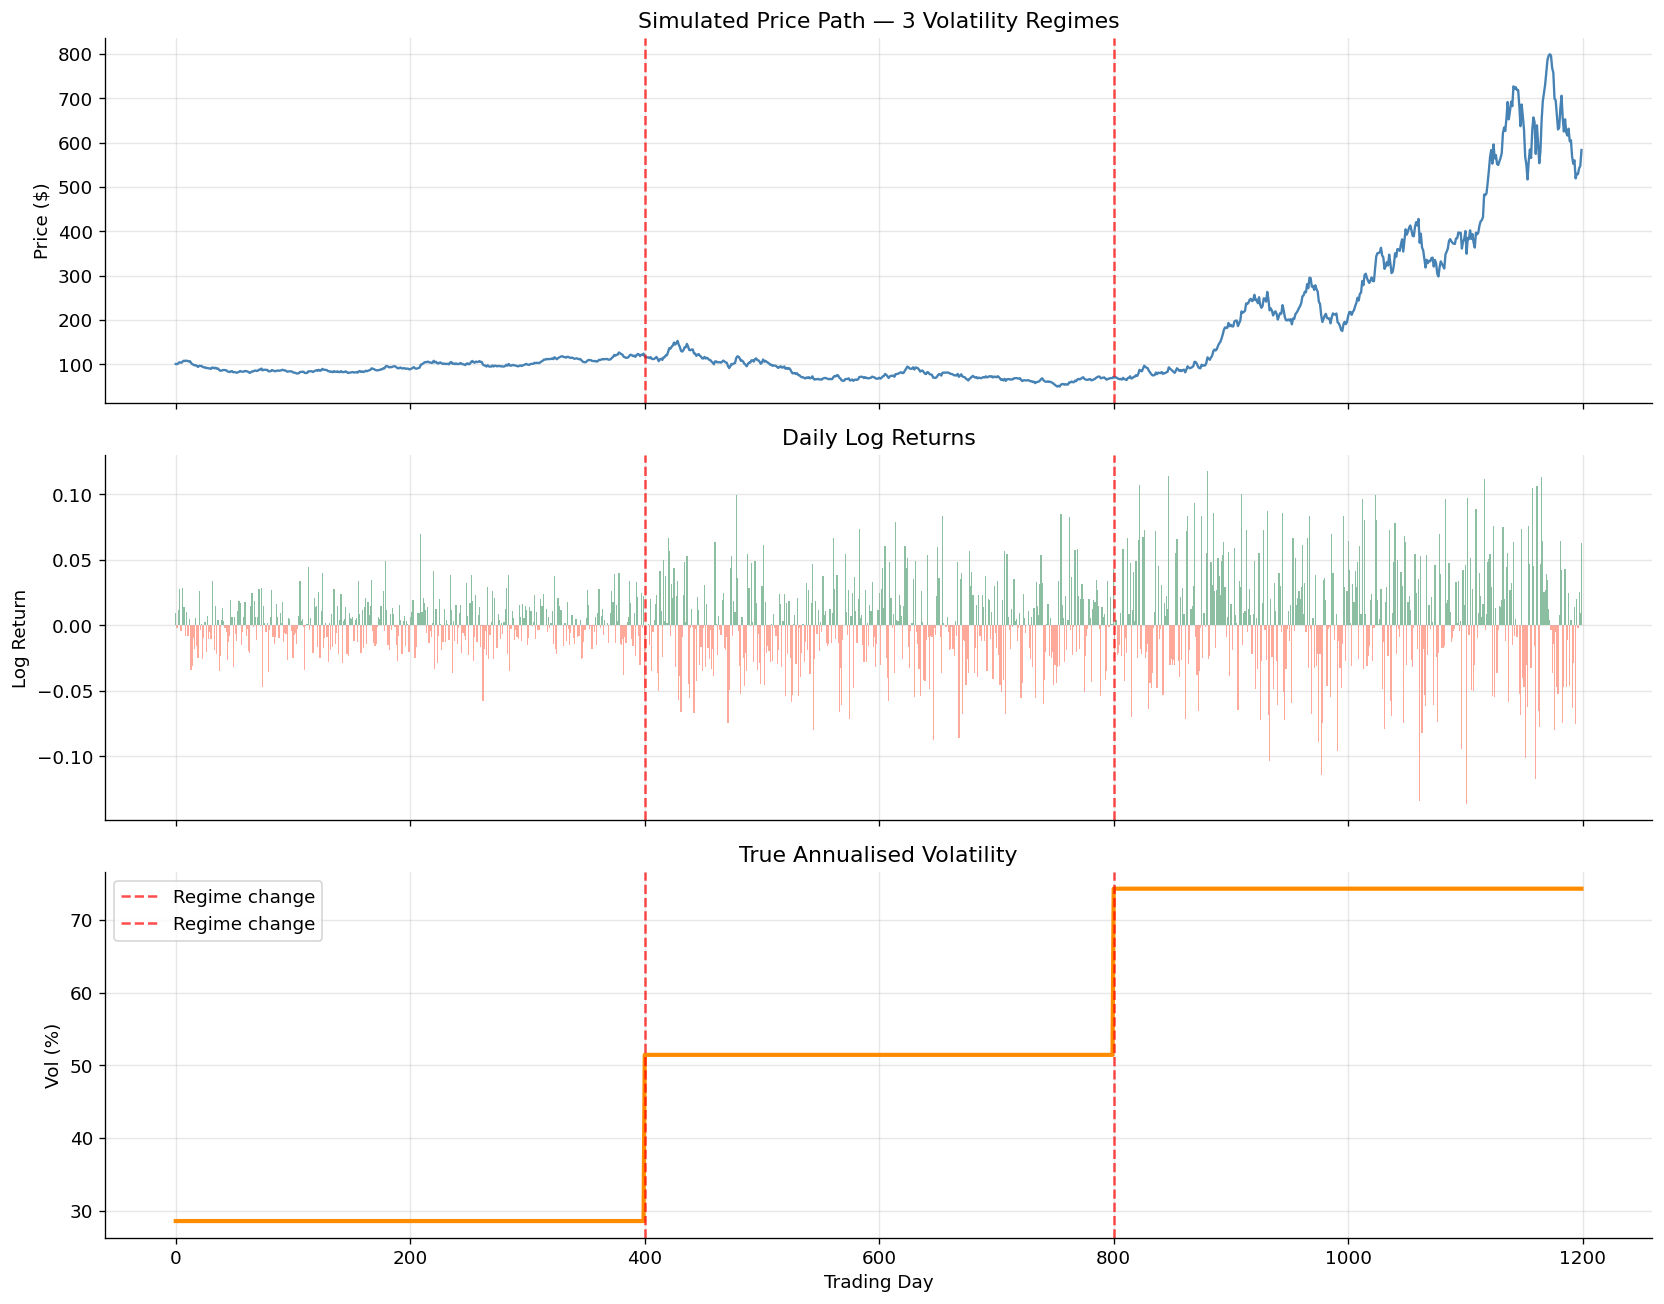

Regime 1 (days 0-400):    true vol = 28.6%
Regime 2 (days 400-800): true vol = 51.4%
Regime 3 (days 800-1200):  true vol = 74.3%


In [2]:
# ── Synthetic data: GBM price path matching Volatility.ipynb convention ──────
# Identical setup so results are comparable to the Volatility notebook

n_days   = 1200
S0       = 100.0
mu_daily = 0.0003        # ~7.5% annual drift
TRUE_VOL = 0.018         # ~28.6% annual vol (daily)
ANN      = np.sqrt(252)

# Three-regime vol path: low → high → very-high (useful for CUSUM demo)
vol_path = np.concatenate([
    np.full(n_days // 3,     TRUE_VOL),
    np.full(n_days // 3,     TRUE_VOL * 1.8),
    np.full(n_days - 2*(n_days//3), TRUE_VOL * 2.6),
])
regime_labels = np.concatenate([
    np.zeros(n_days // 3),
    np.ones(n_days // 3),
    np.full(n_days - 2*(n_days//3), 2),
]).astype(int)

Z = np.random.standard_normal(n_days)
log_rets = (mu_daily - 0.5 * vol_path**2) + vol_path * Z
prices   = S0 * np.exp(np.cumsum(log_rets))
prices   = np.concatenate([[S0], prices])

# OHLC (for range-based vol later)
intraday_factor = 0.6
H = prices[1:] * np.exp(np.abs(np.random.normal(0, vol_path * intraday_factor, n_days)))
L = prices[1:] * np.exp(-np.abs(np.random.normal(0, vol_path * intraday_factor, n_days)))
O = prices[:-1]; C = prices[1:]
H = np.maximum(H, np.maximum(O, C)); L = np.minimum(L, np.minimum(O, C))

t          = np.arange(n_days)
true_ann   = vol_path * ANN * 100     # ground-truth annualised vol (%)
chg_pts    = [n_days // 3, 2 * (n_days // 3)]   # true change-point locations

# ── Quick overview plot ───────────────────────────────────────────────────────
fig, axes = plt.subplots(3, 1, figsize=(14, 11), sharex=True)

axes[0].plot(t, prices[1:], color='steelblue', linewidth=1.4)
for cp in chg_pts:
    axes[0].axvline(cp, color='red', linestyle='--', alpha=0.7)
axes[0].set_title('Simulated Price Path — 3 Volatility Regimes')
axes[0].set_ylabel('Price ($)')

axes[1].bar(t, log_rets,
            color=np.where(log_rets >= 0, 'seagreen', 'tomato'), alpha=0.55, width=1)
for cp in chg_pts:
    axes[1].axvline(cp, color='red', linestyle='--', alpha=0.7)
axes[1].set_title('Daily Log Returns')
axes[1].set_ylabel('Log Return')

axes[2].plot(t, true_ann, color='darkorange', linewidth=2.5)
for cp in chg_pts:
    axes[2].axvline(cp, color='red', linestyle='--', alpha=0.7, label='Regime change')
axes[2].set_title('True Annualised Volatility')
axes[2].set_ylabel('Vol (%)')
axes[2].set_xlabel('Trading Day')
axes[2].legend()

plt.tight_layout()
plt.show()

print(f'Regime 1 (days 0-{chg_pts[0]}):    true vol = {TRUE_VOL*ANN:.1%}')
print(f'Regime 2 (days {chg_pts[0]}-{chg_pts[1]}): true vol = {TRUE_VOL*1.8*ANN:.1%}')
print(f'Regime 3 (days {chg_pts[1]}-{n_days}):  true vol = {TRUE_VOL*2.6*ANN:.1%}')

---

# Part I — CUSUM Theory: Mathematical Foundations

## 1.1 Origin

The **Cumulative Sum (CUSUM)** chart was introduced by **E. S. Page (1954)** for industrial quality control. Unlike Shewhart charts (which react only to the current observation), CUSUM *accumulates* evidence of a shift — making it far more sensitive to **small, sustained changes** in the process mean.

In quantitative finance, CUSUM is used to detect:
- Persistent drift in returns (trend vs noise)
- Volatility regime changes
- Structural breaks in parameters
- Signal triggers for systematic trading strategies

## 1.2 The Core Idea

Given a sequence of observations $x_1, x_2, \ldots$, we ask: *has the process mean shifted from $\mu_0$ to $\mu_1 = \mu_0 + \delta$?*

The **log-likelihood ratio** for each new point favoring the shifted hypothesis:

$$s_t = \ln \frac{f_1(x_t)}{f_0(x_t)} = \frac{\delta}{\sigma^2} \left(x_t - \mu_0 - \frac{\delta}{2}\right)$$

After standardising $y_t = (x_t - \mu_0)/\sigma$, the score simplifies to:

$$s_t = \delta/\sigma \cdot \left(y_t - \frac{\delta/\sigma}{2}\right) = \delta/\sigma \cdot (y_t - k), \quad k = \frac{\delta}{2\sigma}$$

## 1.3 CUSUM Recursion — One-Sided (Upper)

The **upper CUSUM** accumulates positive deviations above the reference value $k$:

$$\boxed{C_t^+ = \max\!\left(0,\ C_{t-1}^+ + (y_t - k)\right)}$$

- $k$ = **allowance** (reference value) — set to $\delta/(2\sigma)$, half the target shift in $\sigma$ units
- $C_0^+ = 0$ (reset to zero prevents old evidence from dominating)
- **Signal**: when $C_t^+ > h$, declare an upward shift

**Lower CUSUM** detects negative shifts:

$$C_t^- = \max\!\left(0,\ C_{t-1}^- - (y_t + k)\right)$$

## 1.4 Parameters: $k$ and $h$

| Parameter | Symbol | Meaning | Typical value |
|-----------|--------|---------|--------------|
| Allowance | $k$ | Minimum shift worth detecting (in σ units), halved | 0.5 (detect 1σ shift) |
| Decision interval | $h$ | Threshold to declare a signal | 4–5 |
| Slack | $\delta$ | Target shift in σ units = $2k$ | 1.0 |

The pair $(k, h)$ jointly controls the **Average Run Length (ARL)**:
- **ARL₀** = expected run length when *in control* (want large: fewer false alarms)
- **ARL₁** = expected run length when *out of control* (want small: faster detection)

Standard design: $k=0.5$, $h=5$ → ARL₀ ≈ 500, ARL₁ ≈ 10 for a 1σ shift.

## 1.5 Comparison with Shewhart and EWMA

| Method | Memory | Best for | Weakness |
|--------|--------|---------|---------|
| Shewhart (3σ) | None | Large shifts (≥3σ) | Blind to small shifts |
| EWMA | Exponential decay | Medium shifts (1–2σ) | Parameter tuning |
| **CUSUM** | Accumulates since last reset | **Small persistent shifts** | Assumes known $\mu_0, \sigma$ |

### 1.5 Core CUSUM Implementations

Below we define the two workhorse functions used throughout the notebook:
- `cusum_one_sided` — upper detector only, signals when cumulative positive deviations exceed threshold $h$
- `cusum_two_sided` — runs both an upper ($C^+$) and lower ($C^-$) detector simultaneously

Both functions accept raw data and standardise internally using the in-control mean $\mu_0$ and standard deviation $\sigma_0$.

In [3]:

# ── Core CUSUM implementations ─────────────────────────────────────────────────

def cusum_one_sided(x, k=0.5, h=5.0, mu0=None, sigma=None, reset=True):
    """
    Upper one-sided CUSUM on raw series x.
    Standardises internally if mu0 and sigma are provided.
    Returns: C_upper, signal_indices
    """
    x = np.asarray(x, dtype=float)
    if mu0 is not None and sigma is not None:
        y = (x - mu0) / sigma
    else:
        burn = max(20, len(x) // 5)
        mu0_est  = np.nanmean(x[:burn])
        sig_est  = np.nanstd(x[:burn], ddof=1)
        y = (x - mu0_est) / sig_est

    n  = len(y)
    C  = np.zeros(n)
    signals = []
    for i in range(1, n):
        C[i] = max(0.0, C[i-1] + y[i] - k)
        if C[i] > h:
            signals.append(i)
            if reset:
                C[i] = 0.0
    return C, np.array(signals, dtype=int)


def cusum_two_sided(x, k=0.5, h=5.0, mu0=None, sigma=None, reset=True):
    """
    Two-sided CUSUM: detects both upward and downward shifts.
    Returns: C_upper, C_lower, up_signals, dn_signals  (signal arrays are int dtype)
    """
    x = np.asarray(x, dtype=float)
    if mu0 is not None and sigma is not None:
        y = (x - mu0) / sigma
    else:
        burn = max(20, len(x) // 5)
        mu0_est = np.nanmean(x[:burn])
        sig_est = np.nanstd(x[:burn], ddof=1)
        y = (x - mu0_est) / sig_est

    n  = len(y)
    Cu = np.zeros(n)
    Cl = np.zeros(n)
    up_signals, dn_signals = [], []
    for i in range(1, n):
        Cu[i] = max(0.0, Cu[i-1] + (y[i] - k))
        Cl[i] = max(0.0, Cl[i-1] - (y[i] + k))
        if Cu[i] > h:
            up_signals.append(i)
            if reset: Cu[i] = 0.0
        if Cl[i] > h:
            dn_signals.append(i)
            if reset: Cl[i] = 0.0
    # dtype=int ensures empty arrays don't default to float64 (which breaks indexing)
    return Cu, Cl, np.array(up_signals, dtype=int), np.array(dn_signals, dtype=int)


def tabular_cusum(x, k=0.5, h=5.0, mu0=0.0, sigma=1.0):
    """
    Classic tabular CUSUM (Page 1954) — returns full path without resets.
    Useful for visualising the accumulation.
    """
    y  = (np.asarray(x, float) - mu0) / sigma
    Cu = np.zeros(len(y));  Cl = np.zeros(len(y))
    for i in range(1, len(y)):
        Cu[i] = max(0.0, Cu[i-1] + y[i] - k)
        Cl[i] = max(0.0, Cl[i-1] - y[i] - k)
    return Cu, Cl

print('CUSUM functions defined.')


CUSUM functions defined.


---

# Part II — One-Sided CUSUM on Returns

## 2.1 Motivation

Daily log returns under GBM are approximately i.i.d. $\mathcal{N}(\mu, \sigma^2)$. A **persistent upward drift** in returns (e.g., a regime with strong momentum) or a **persistent downward drift** (e.g., a bear market with negative bias) cannot be reliably detected from individual observations — they look like noise. CUSUM accumulates the evidence.

## 2.2 The Standardised Score

We standardise each return by the **in-control** (regime 1) parameters:

$$y_t = \frac{r_t - \hat{\mu}_0}{\hat{\sigma}_0}$$

Then run the upper CUSUM:

$$C_t^+ = \max\!\left(0,\ C_{t-1}^+ + y_t - k\right)$$

A signal fires when $C_t^+ > h$, indicating the mean has shifted upward by at least $2k\sigma$.

### 2.3 One-Sided CUSUM — Visualisation

We estimate in-control parameters ($\mu_0$, $\sigma_0$) from a 200-day burn-in period, then run the one-sided CUSUM with three different allowance values ($k = 0.25, 0.50, 1.00$) at a fixed threshold $h = 5$. Smaller $k$ accumulates evidence faster but is noisier; larger $k$ requires a stronger shift before accumulation begins.

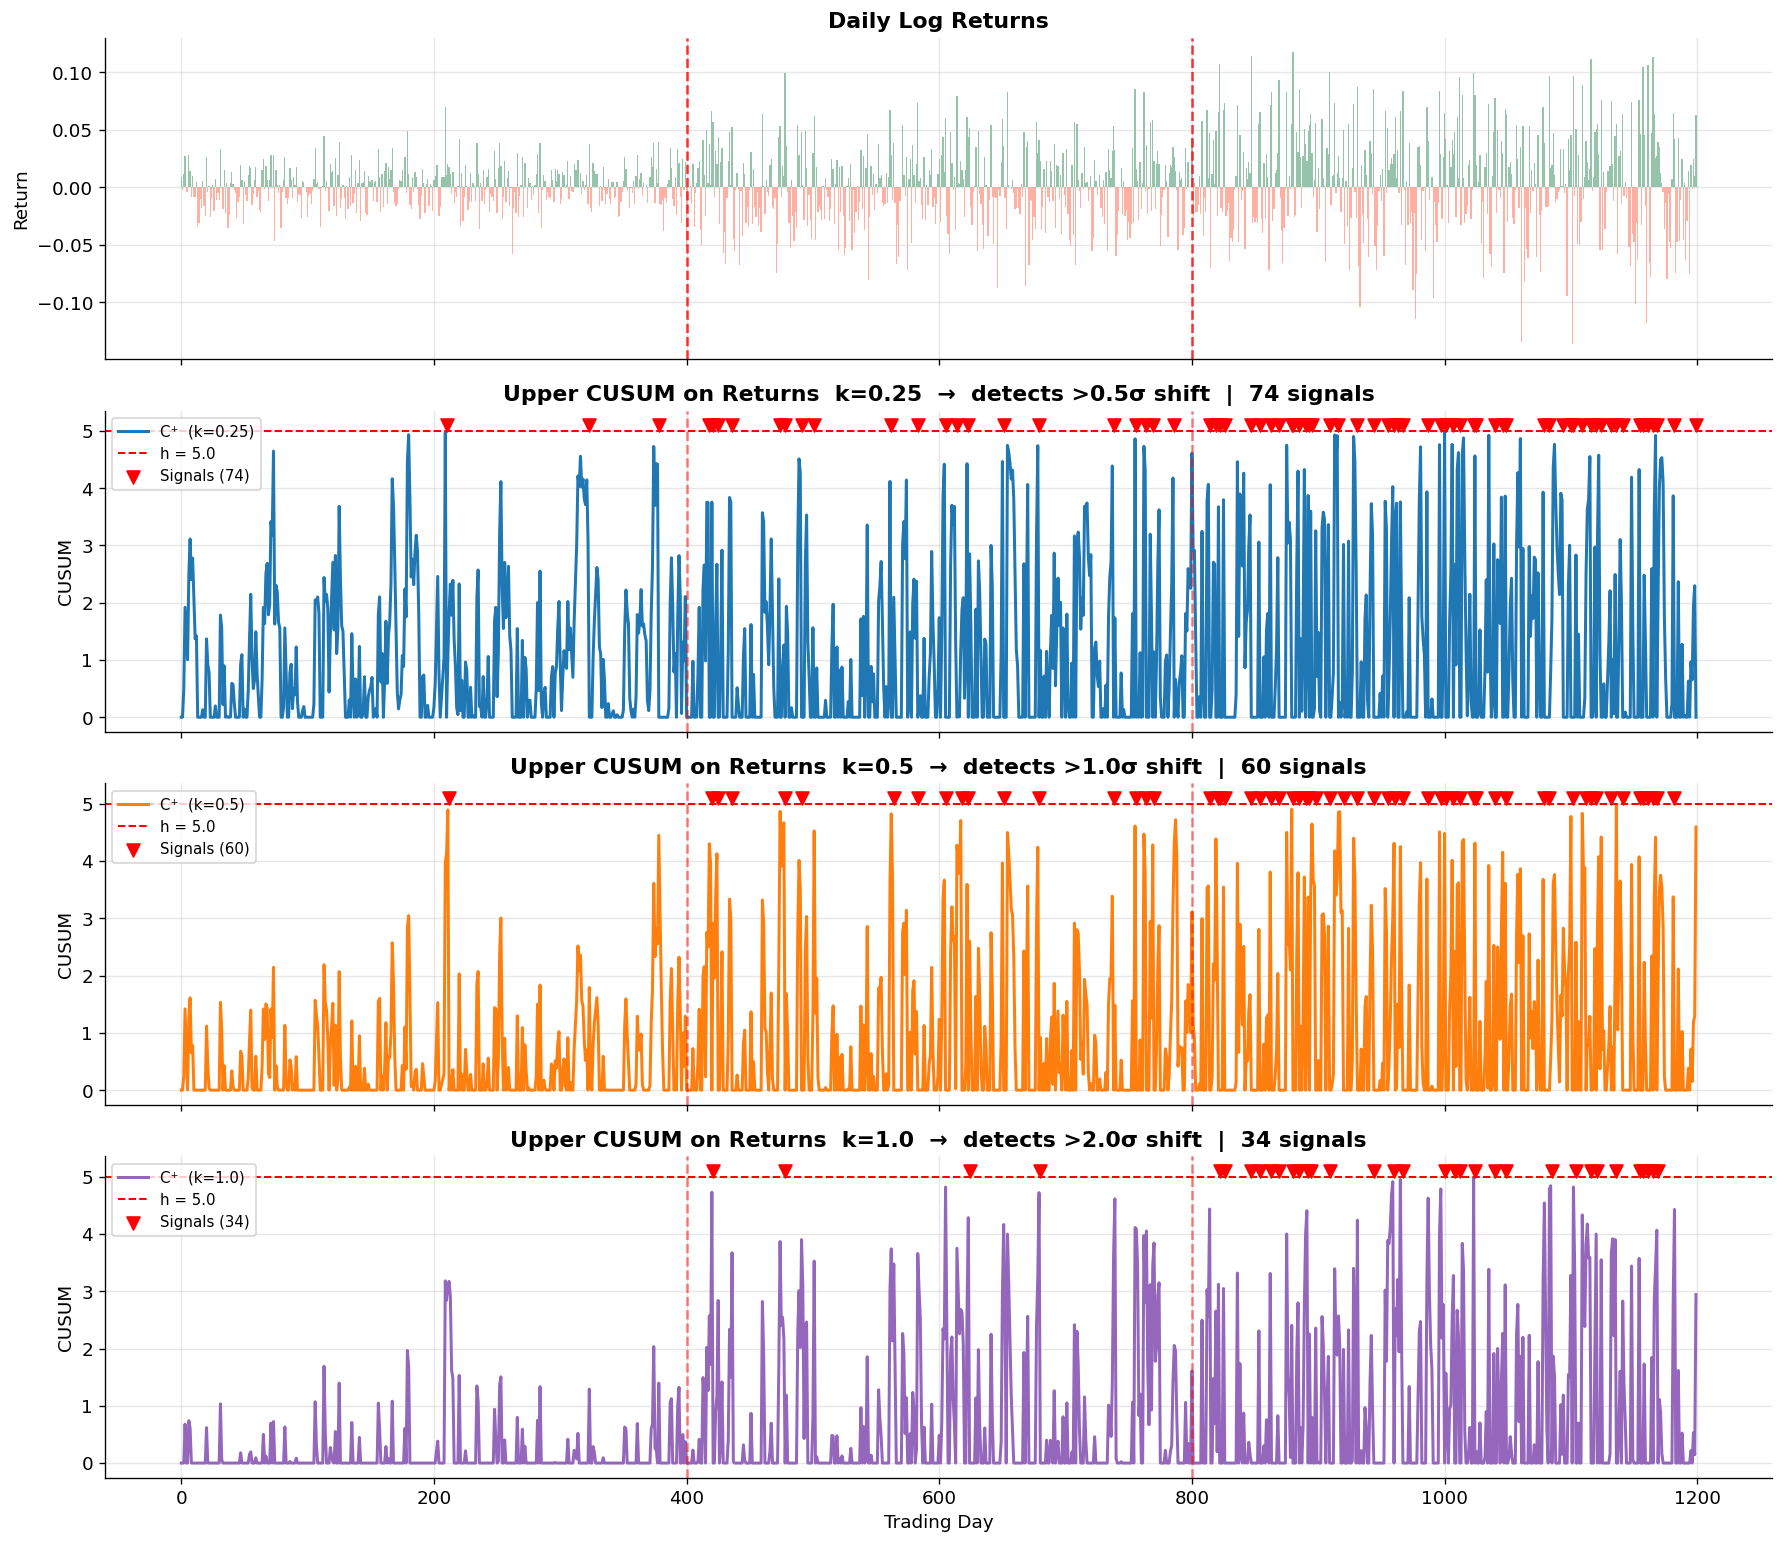

In-control estimates  μ₀=-0.000596  σ₀=0.016758

Signal counts (h=5.0):
  k=0.25:  74 signals
  k=0.5 :  60 signals
  k=1.0 :  34 signals


In [4]:

# ── 2.3 One-sided CUSUM on returns ────────────────────────────────────────────
# Estimate in-control parameters from burn-in (first 200 days)
burn   = 200
mu0    = np.mean(log_rets[:burn])
sigma0 = np.std(log_rets[:burn], ddof=1)

k_vals = [0.25, 0.50, 1.00]   # different allowances
h      = 5.0

fig, axes = plt.subplots(len(k_vals) + 1, 1, figsize=(15, 13), sharex=True)

# Top panel: returns
axes[0].bar(t, log_rets, color=np.where(log_rets >= 0, 'seagreen', 'tomato'),
            alpha=0.5, width=1)
for cp in chg_pts:
    axes[0].axvline(cp, color='red', linestyle='--', alpha=0.8, linewidth=1.5)
axes[0].set_title('Daily Log Returns', fontweight='bold')
axes[0].set_ylabel('Return')

palette = ['#1f77b4', '#ff7f0e', '#9467bd']
for ax, k_v, col in zip(axes[1:], k_vals, palette):
    Cu, sigs = cusum_one_sided(log_rets, k=k_v, h=h, mu0=mu0, sigma=sigma0, reset=True)
    ax.plot(t, Cu, color=col, linewidth=1.8, label=f'C⁺  (k={k_v})')
    ax.axhline(h, color='red', linestyle='--', linewidth=1.2, label=f'h = {h}')
    for cp in chg_pts:
        ax.axvline(cp, color='red', linestyle='--', alpha=0.5)
    if len(sigs):
        ax.scatter(sigs, np.full(len(sigs), h*1.02), marker='v', color='red',
                   s=60, zorder=5, label=f'Signals ({len(sigs)})')
    ax.set_ylabel('CUSUM')
    ax.set_title(f'Upper CUSUM on Returns  k={k_v}  →  detects >{2*k_v:.1f}σ shift  |  {len(sigs)} signals',
                 fontweight='bold')
    ax.legend(loc='upper left', fontsize=9)

axes[-1].set_xlabel('Trading Day')
plt.tight_layout()
plt.show()

# Print signal summary
print(f'In-control estimates  μ₀={mu0:.6f}  σ₀={sigma0:.6f}')
print(f'\nSignal counts (h={h}):')
for k_v in k_vals:
    _, sigs = cusum_one_sided(log_rets, k=k_v, h=h, mu0=mu0, sigma=sigma0)
    print(f'  k={k_v:<4}: {len(sigs):3d} signals')

### 2.4 Threshold Sensitivity Sweep

How does the decision threshold $h$ affect signal frequency? We fix $k = 0.5$ and sweep $h \in \{2, 4, 5, 8\}$. Low $h$ fires frequently (many false alarms in-control), while high $h$ fires rarely (slow detection even when a real shift occurs). This is the **ARL₀ vs ARL₁ trade-off** previewed visually.

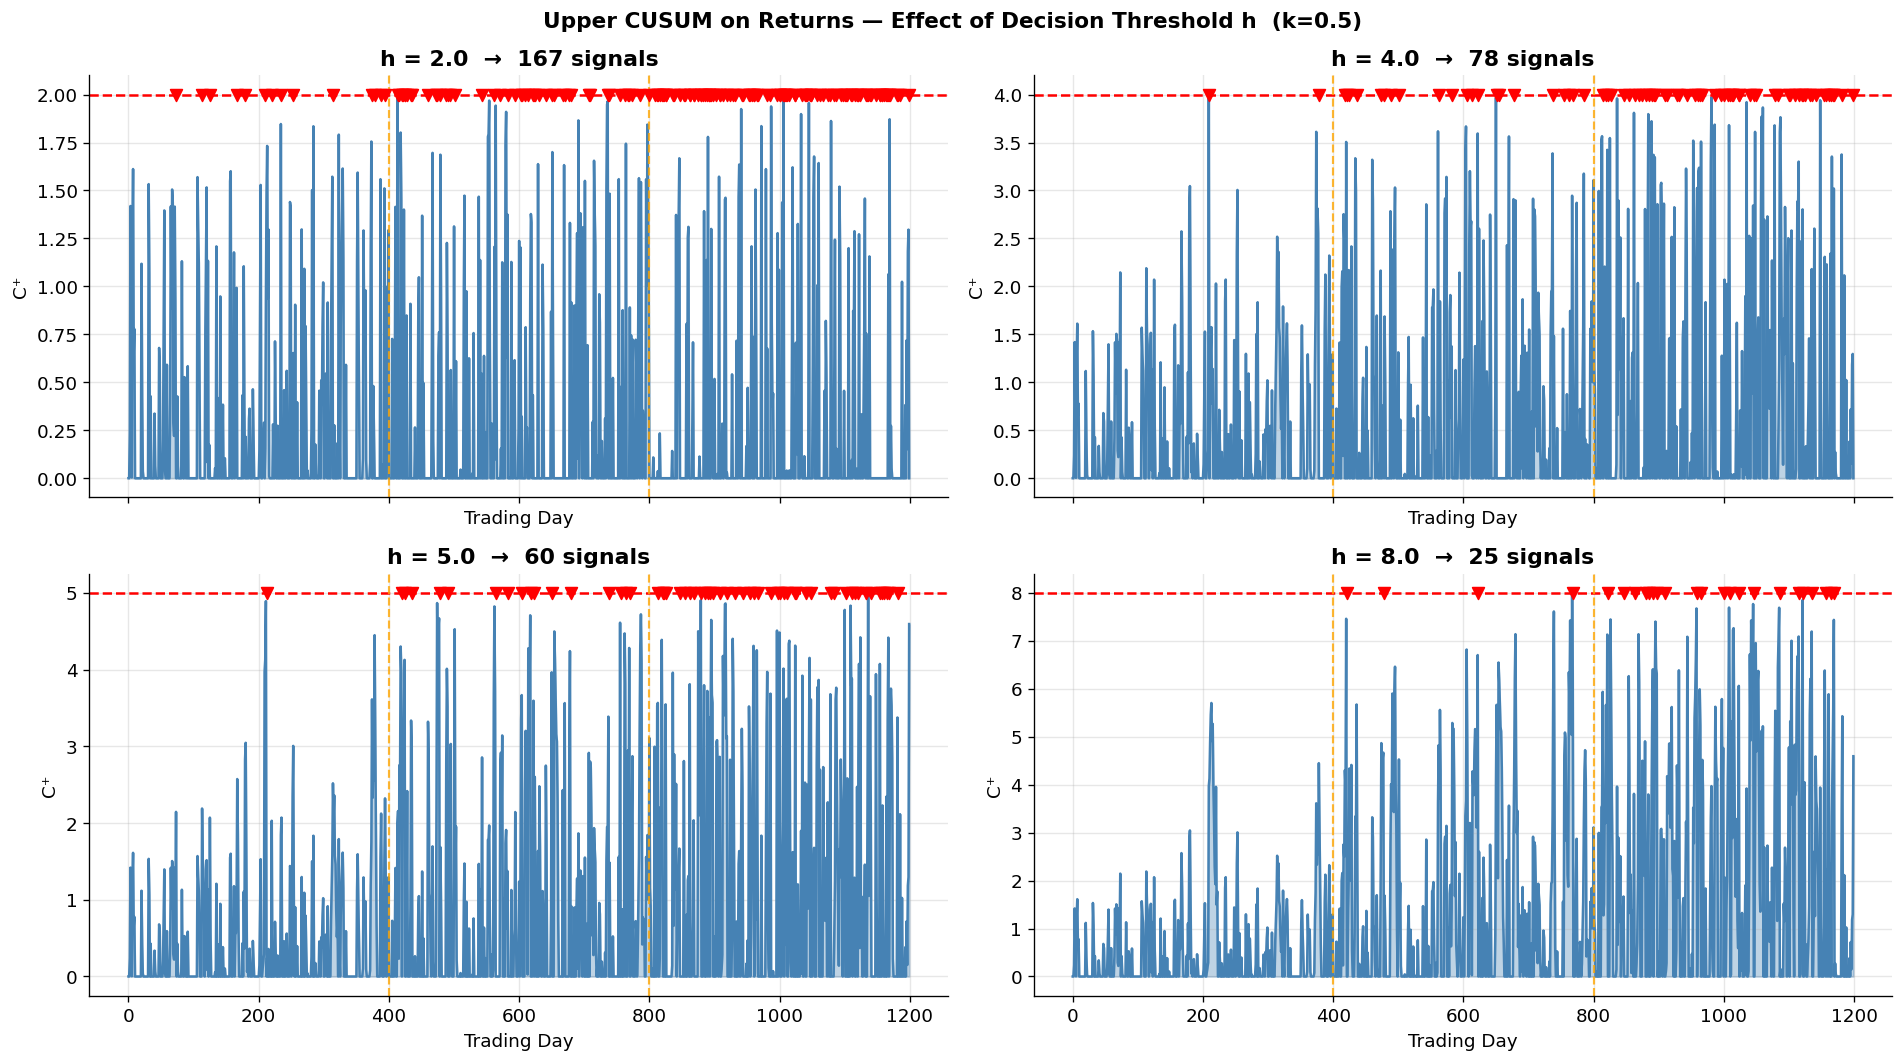

Observation: smaller h → more signals (faster but noisier); larger h → fewer false alarms but slower detection.


In [5]:

# ── 2.4 Effect of h (decision threshold) — sensitivity sweep ─────────────────
k_fixed = 0.5
h_vals  = [2.0, 4.0, 5.0, 8.0]

fig, axes = plt.subplots(2, 2, figsize=(16, 9), sharex=True, sharey=False)

for ax, h_v in zip(axes.flat, h_vals):
    Cu, sigs = cusum_one_sided(log_rets, k=k_fixed, h=h_v, mu0=mu0, sigma=sigma0)
    ax.fill_between(t, Cu, alpha=0.35, color='steelblue')
    ax.plot(t, Cu, color='steelblue', linewidth=1.5)
    ax.axhline(h_v, color='red', linestyle='--', linewidth=1.5)
    for cp in chg_pts:
        ax.axvline(cp, color='orange', linestyle='--', alpha=0.8, linewidth=1.3)
    if len(sigs):
        ax.scatter(sigs, np.full(len(sigs), h_v), marker='v',
                   color='red', s=50, zorder=5)
    ax.set_title(f'h = {h_v}  →  {len(sigs)} signals', fontweight='bold')
    ax.set_ylabel('C⁺')
    ax.set_xlabel('Trading Day')

plt.suptitle(f'Upper CUSUM on Returns — Effect of Decision Threshold h  (k={k_fixed})',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

print('Observation: smaller h → more signals (faster but noisier); larger h → fewer false alarms but slower detection.')

### 2.5 Interactive 3D Surface — Time × Allowance $k$

A Plotly surface showing how the CUSUM statistic $C^+$ evolves jointly over time and across different $k$ values. The ridge that forms at each regime change point reveals how quickly different allowances respond to the shift.

In [6]:

# ── 2.5 Plotly 3D: One-sided CUSUM path surface — Time × Allowance k ──────────
# Shows how CUSUM accumulates differently on returns for various k values

k_sweep_ret = np.arange(0.1, 1.55, 0.05)
n_show_ret  = min(800, n_days)

C_ret_surface = np.zeros((len(k_sweep_ret), n_show_ret))
for i, kk in enumerate(k_sweep_ret):
    Cu_tmp, _ = cusum_one_sided(log_rets[:n_show_ret], k=kk, h=999,
                                 mu0=mu0, sigma=sigma0, reset=False)
    C_ret_surface[i] = Cu_tmp

T_r, K_r = np.meshgrid(np.arange(n_show_ret), k_sweep_ret)

fig = go.Figure(go.Surface(
    x=T_r, y=K_r, z=C_ret_surface,
    colorscale='Viridis',
    colorbar=dict(title='C⁺', len=0.65),
    hovertemplate='Day=%{x}<br>k=%{y:.2f}<br>C⁺=%{z:.2f}<extra></extra>',
    opacity=0.9,
))
for cp in chg_pts:
    if cp < n_show_ret:
        fig.add_trace(go.Scatter3d(
            x=[cp]*len(k_sweep_ret), y=k_sweep_ret,
            z=C_ret_surface[:, cp],
            mode='lines', line=dict(color='red', width=5),
            name=f'Regime change (day {cp})',
        ))
fig.update_layout(
    title='3D: One-Sided CUSUM on Returns — Sensitivity to Allowance k<br>'
          '<sup>Small k (front) accumulates faster → more false alarms; '
          'large k (back) is selective but slower. Red = true change points</sup>',
    scene=dict(
        xaxis_title='Trading Day',
        yaxis_title='Allowance k',
        zaxis_title='C⁺ (no reset)',
        camera=dict(eye=dict(x=1.5, y=-1.8, z=1.0)),
    ),
    height=650, width=1050, margin=dict(l=0, r=0, t=80, b=0),
    legend=dict(x=0.01, y=0.95),
)
fig.show()


---

# Part III — Two-Sided CUSUM on Returns

## 3.1 Why Two-Sided?

The one-sided CUSUM only detects shifts in **one direction**. In financial markets, we care about both:
- **Upward drift** (positive momentum, bull regime)
- **Downward drift** (negative momentum, bear regime)

The two-sided CUSUM runs both an upper and a lower detector simultaneously:

$$C_t^+ = \max(0,\ C_{t-1}^+ + y_t - k) \qquad \text{upper (detects positive shift)}$$
$$C_t^- = \max(0,\ C_{t-1}^- - y_t - k) \qquad \text{lower (detects negative shift)}$$

A signal fires when either $C_t^+ > h$ or $C_t^- > h$.

## 3.2 Interpretation in Finance

| Signal type | Interpretation |
|-------------|----------------|
| $C^+ > h$ | Sustained positive returns — bull momentum / uptrend |
| $C^- > h$ | Sustained negative returns — bear momentum / downtrend |
| Both silent | Mean-reverting noise, no persistent drift |

## 3.3 The V-Mask (Alternative Representation)

The two-sided CUSUM is equivalent to a **V-mask** drawn on the cumulative sum path. A signal occurs when the path crosses either arm of the V. The angle $\theta = \arctan(k)$ and lead distance $d = h/k$ define the mask shape. We focus on the recursive form here as it is more practical for real-time monitoring.

### 3.4 Two-Sided CUSUM — Full Visualisation

We run the two-sided CUSUM ($k = 0.5$, $h = 5$) on returns and plot three panels:
1. **Returns** with signal markers — triangles show where $C^+$ or $C^-$ fired
2. **Upper detector** $C^+$ — accumulates evidence of positive drift
3. **Lower detector** $C^-$ — accumulates evidence of negative drift

Together they capture shifts in both directions, which is essential for financial data where both bull and bear regimes matter.

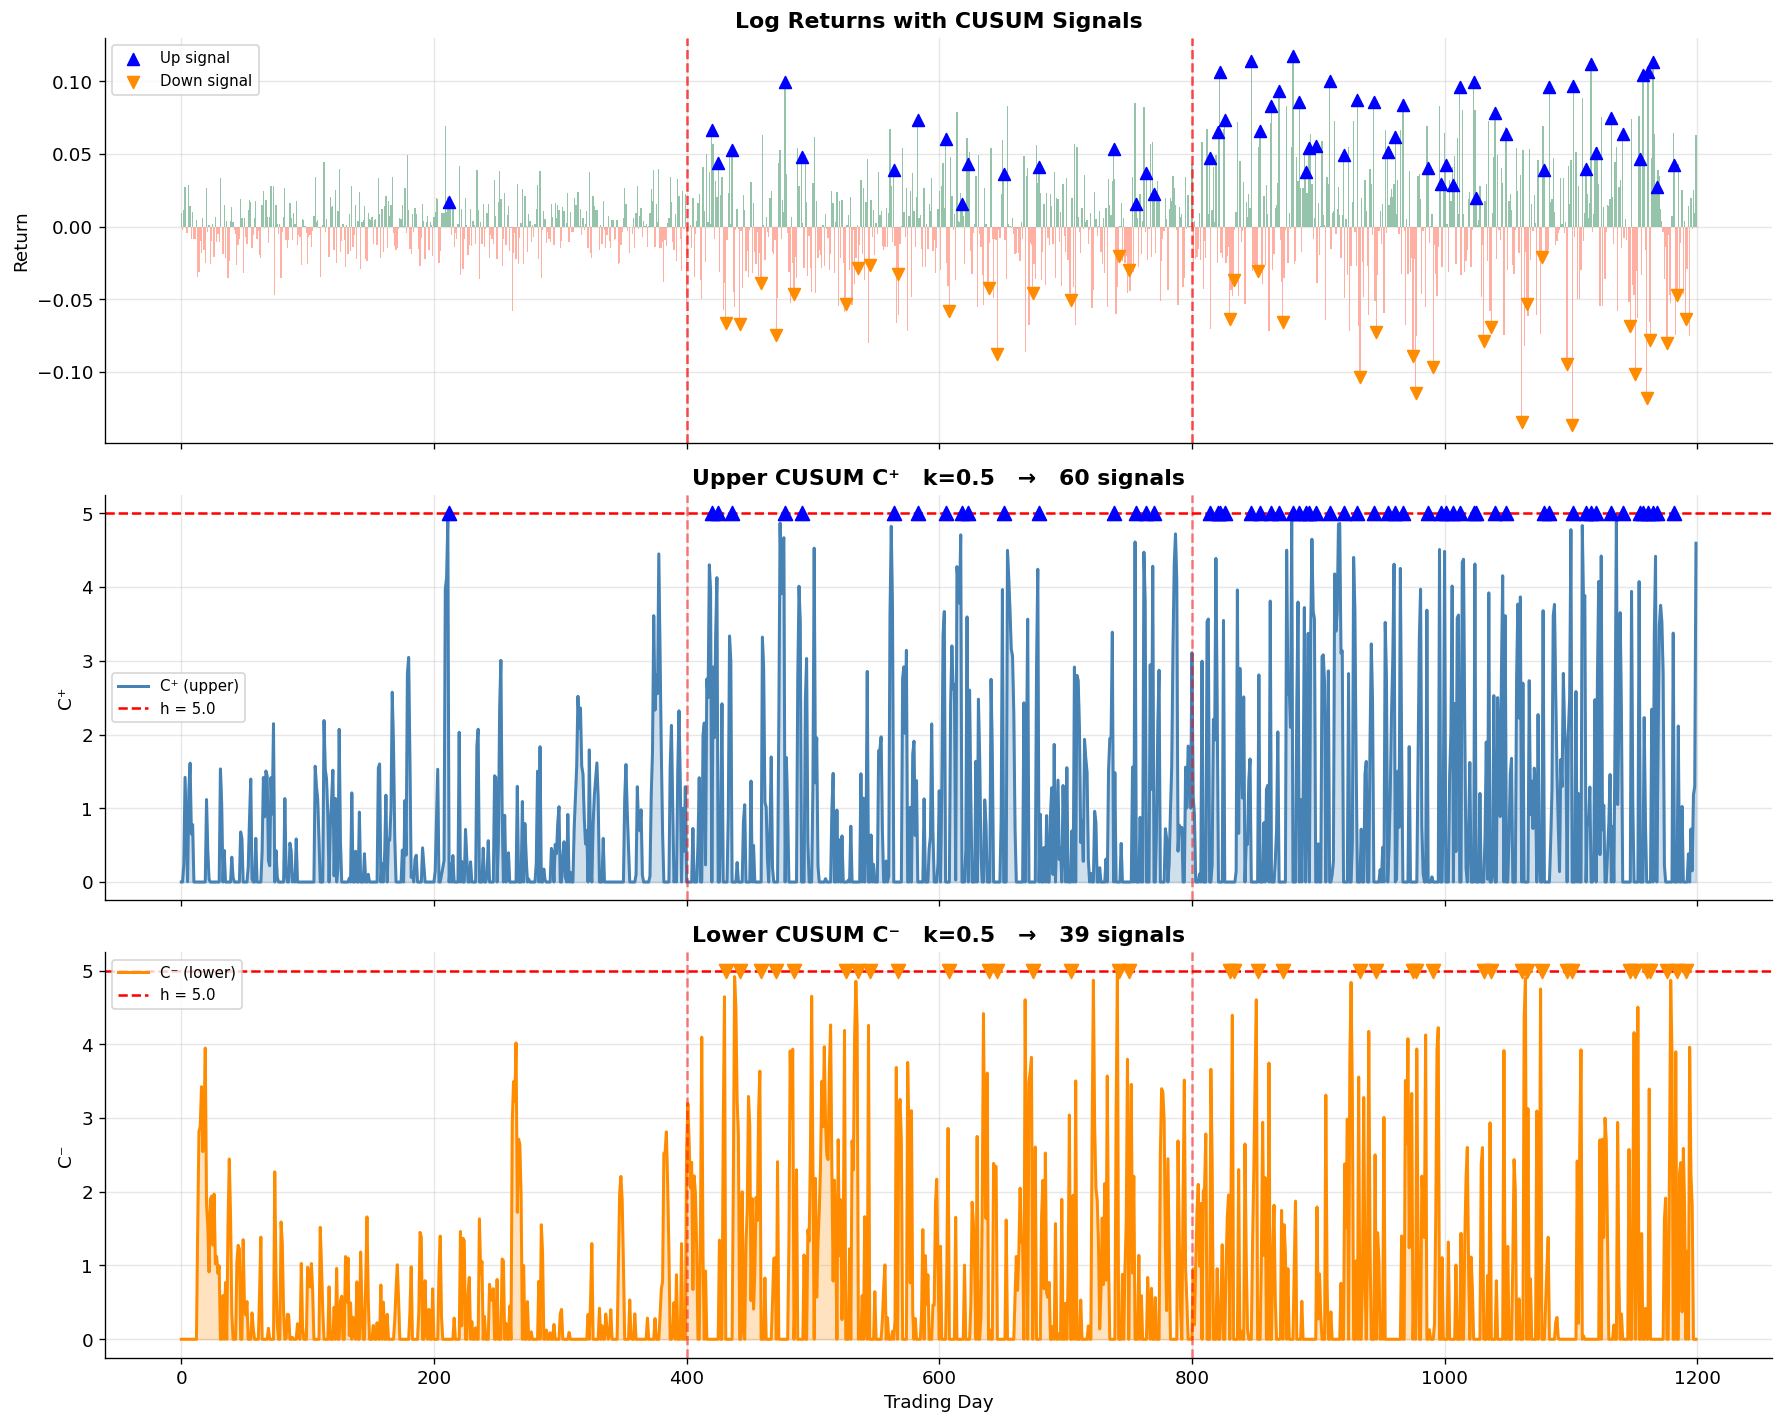

Two-sided CUSUM (k=0.5, h=5.0):
  Upward signals  : 60  at days [212 420 425 436 478 491 564 583 605 618]...
  Downward signals: 39  at days [431 442 459 471 485 526 536 545 567 608]...


In [7]:

# ── 3.4 Two-sided CUSUM on returns — full visualisation ──────────────────────
k, h = 0.5, 5.0
Cu, Cl, up_sigs, dn_sigs = cusum_two_sided(log_rets, k=k, h=h,
                                            mu0=mu0, sigma=sigma0, reset=True)

fig, axes = plt.subplots(3, 1, figsize=(15, 12), sharex=True)

# Panel 1: raw returns with signal markers
ax = axes[0]
ax.bar(t, log_rets, color=np.where(log_rets >= 0, 'seagreen', 'tomato'),
       alpha=0.5, width=1)
for cp in chg_pts:
    ax.axvline(cp, color='red', linestyle='--', alpha=0.7)
if len(up_sigs):
    ax.scatter(up_sigs, log_rets[up_sigs], marker='^', color='blue',
               s=50, zorder=6, label='Up signal')
if len(dn_sigs):
    ax.scatter(dn_sigs, log_rets[dn_sigs], marker='v', color='darkorange',
               s=50, zorder=6, label='Down signal')
ax.set_title('Log Returns with CUSUM Signals', fontweight='bold')
ax.set_ylabel('Return')
ax.legend(fontsize=9)

# Panel 2: upper CUSUM
ax2 = axes[1]
ax2.fill_between(t, Cu, alpha=0.25, color='steelblue')
ax2.plot(t, Cu, color='steelblue', linewidth=1.8, label='C⁺ (upper)')
ax2.axhline(h, color='red', linestyle='--', linewidth=1.5, label=f'h = {h}')
for cp in chg_pts:
    ax2.axvline(cp, color='red', linestyle='--', alpha=0.5)
if len(up_sigs):
    ax2.scatter(up_sigs, np.full(len(up_sigs), h), marker='^',
                color='blue', s=70, zorder=6)
ax2.set_title(f'Upper CUSUM C⁺   k={k}   →   {len(up_sigs)} signals', fontweight='bold')
ax2.set_ylabel('C⁺')
ax2.legend(fontsize=9)

# Panel 3: lower CUSUM
ax3 = axes[2]
ax3.fill_between(t, Cl, alpha=0.25, color='darkorange')
ax3.plot(t, Cl, color='darkorange', linewidth=1.8, label='C⁻ (lower)')
ax3.axhline(h, color='red', linestyle='--', linewidth=1.5, label=f'h = {h}')
for cp in chg_pts:
    ax3.axvline(cp, color='red', linestyle='--', alpha=0.5)
if len(dn_sigs):
    ax3.scatter(dn_sigs, np.full(len(dn_sigs), h), marker='v',
                color='darkorange', s=70, zorder=6)
ax3.set_title(f'Lower CUSUM C⁻   k={k}   →   {len(dn_sigs)} signals', fontweight='bold')
ax3.set_ylabel('C⁻')
ax3.set_xlabel('Trading Day')
ax3.legend(fontsize=9)

plt.tight_layout()
plt.show()

print(f'Two-sided CUSUM (k={k}, h={h}):')
print(f'  Upward signals  : {len(up_sigs)}  at days {up_sigs[:10]}{"..." if len(up_sigs)>10 else ""}')
print(f'  Downward signals: {len(dn_sigs)}  at days {dn_sigs[:10]}{"..." if len(dn_sigs)>10 else ""}')

### 3.5 Cumulative Sum Path & V-Mask Perspective

Before the $\max(0, \ldots)$ clamp, the raw cumulative sum of standardised returns is a random walk. The classical **V-mask** is an alternative graphical device: a V-shaped template is slid along the cumulative sum, and a signal fires when the path protrudes outside the mask arms. Here we plot both the full cumulative path and a V-mask illustration on a short trailing window.

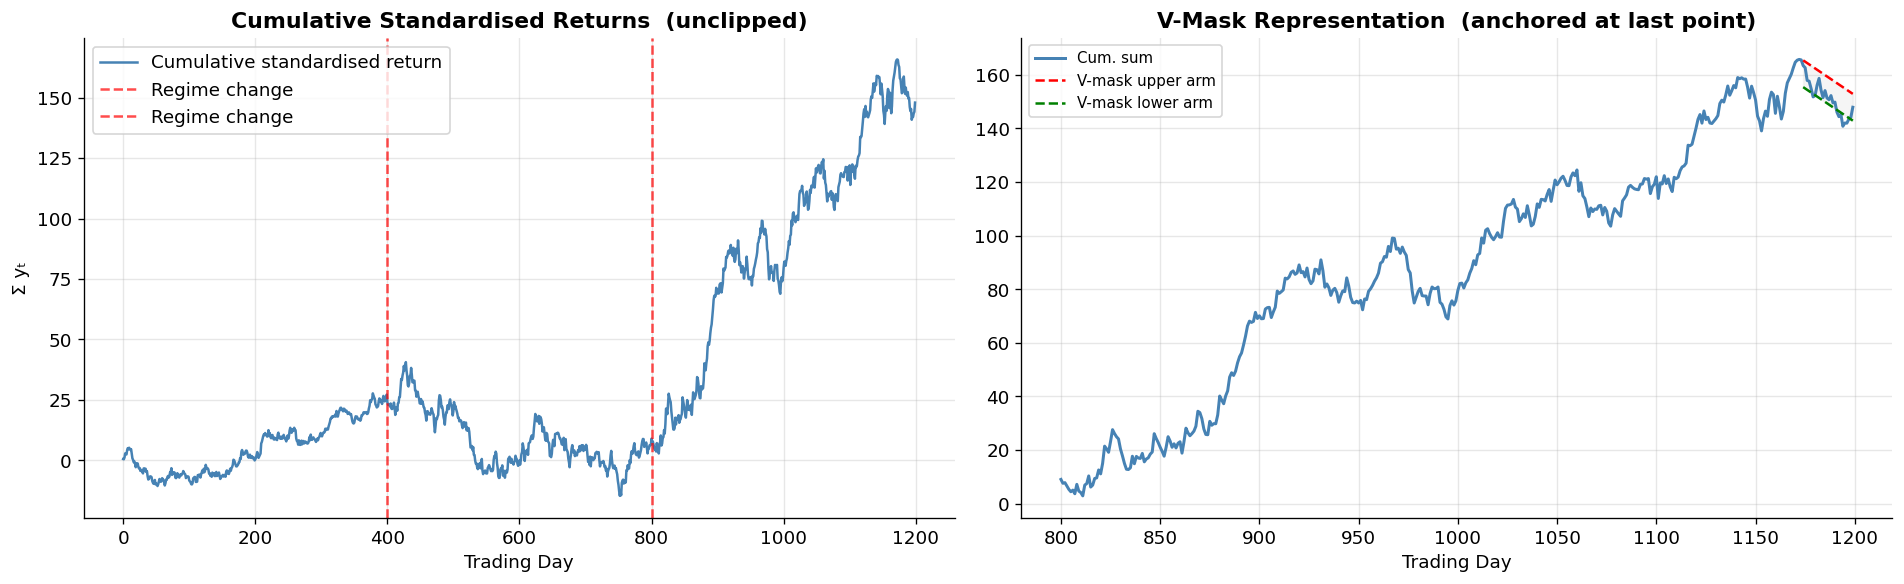

In [8]:

# ── 3.5 Cumulative-sum path (no reset) — V-mask perspective ──────────────────
# The cumulative sum of standardised returns is the raw process before the max(0,...) clamp.
# This gives the "wandering random walk" view that the V-mask overlays onto.

y_std = (log_rets - mu0) / sigma0
cum_y = np.cumsum(y_std)

# Build V-mask arms anchored at each point in the final 30% of data
# V-mask: for any historical point s < t, alarm if cum_y[s] > cum_y[t] + k*(t-s) - h
# We just visualise the concept on a short window
window_vm = slice(n_days - 400, n_days)
t_vm      = t[window_vm]
cy_vm     = cum_y[window_vm]

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Left: Full cumulative sum path
ax = axes[0]
ax.plot(t, cum_y, color='steelblue', linewidth=1.5, label='Cumulative standardised return')
for cp in chg_pts:
    ax.axvline(cp, color='red', linestyle='--', alpha=0.7, label='Regime change')
ax.set_title('Cumulative Standardised Returns  (unclipped)', fontweight='bold')
ax.set_xlabel('Trading Day')
ax.set_ylabel('Σ yₜ')
ax.legend()

# Right: V-mask on last window
ax2 = axes[1]
ax2.plot(t_vm, cy_vm, color='steelblue', linewidth=1.8, label='Cum. sum')
# Draw illustrative V-mask anchored at the last point
t_anchor = t_vm[-1]; cy_anchor = cy_vm[-1]
d = h / k   # lead distance
t_left = np.arange(t_anchor - int(d*2.5), t_anchor + 1)
arm_up = cy_anchor + k * (t_anchor - t_left) + h
arm_dn = cy_anchor + k * (t_anchor - t_left) - h
ax2.plot(t_left, arm_up, 'r--', linewidth=1.5, label='V-mask upper arm')
ax2.plot(t_left, arm_dn, 'g--', linewidth=1.5, label='V-mask lower arm')
ax2.fill_between(t_left, arm_dn, arm_up, alpha=0.08, color='gray')
ax2.set_title('V-Mask Representation  (anchored at last point)', fontweight='bold')
ax2.set_xlabel('Trading Day')
ax2.legend(fontsize=9)

plt.tight_layout()
plt.show()

### 3.6 Interactive 3D Trajectory — $(\text{Time},\, C^+,\, C^-)$ Space

A 3D scatter/line plot in Plotly showing the joint evolution of $C^+$ and $C^-$ over time (no reset). Colour encodes the true volatility regime. The trajectory bends sharply at regime boundaries — a visual signature that CUSUM can exploit.

In [9]:

# ── 3.6 Plotly 3D: Two-sided CUSUM trajectory in (Time, C⁺, C⁻) space ────────
# A 3D trajectory showing how both detectors evolve simultaneously

Cu_nrs, Cl_nrs, _, _ = cusum_two_sided(
    log_rets, k=0.5, h=999, mu0=mu0, sigma=sigma0, reset=False
)

n_3d_ts = min(800, n_days)
colors_ts = np.zeros(n_3d_ts)
for i, cp in enumerate(chg_pts):
    if cp < n_3d_ts:
        colors_ts[cp:] = i + 1

fig = go.Figure()

# Main trajectory
fig.add_trace(go.Scatter3d(
    x=np.arange(n_3d_ts),
    y=Cu_nrs[:n_3d_ts],
    z=Cl_nrs[:n_3d_ts],
    mode='lines',
    line=dict(
        color=colors_ts,
        colorscale=[[0,'steelblue'],[0.33,'steelblue'],
                    [0.34,'darkorange'],[0.66,'darkorange'],
                    [0.67,'red'],[1.0,'red']],
        width=4,
    ),
    name='CUSUM trajectory',
    hovertemplate='Day=%{x}<br>C⁺=%{y:.2f}<br>C⁻=%{z:.2f}<extra></extra>',
))

# Mark regime change points
for cp in chg_pts:
    if cp < n_3d_ts:
        fig.add_trace(go.Scatter3d(
            x=[cp], y=[Cu_nrs[cp]], z=[Cl_nrs[cp]],
            mode='markers',
            marker=dict(size=8, color='red', symbol='diamond'),
            name=f'Change point (day {cp})',
        ))

fig.update_layout(
    title='3D: Two-Sided CUSUM Trajectory  (C⁺ vs C⁻ over Time)<br>'
          '<sup>Blue = Regime 1, Orange = Regime 2, Red = Regime 3. '
          'Trajectory tilts toward C⁺ axis during upward drift, C⁻ during downward</sup>',
    scene=dict(
        xaxis_title='Trading Day',
        yaxis_title='Upper Detector C⁺',
        zaxis_title='Lower Detector C⁻',
        camera=dict(eye=dict(x=1.5, y=-1.5, z=1.0)),
    ),
    height=650, width=1050, margin=dict(l=0, r=0, t=80, b=0),
)
fig.show()


---

# Part IV — CUSUM on Volatility

## 4.1 Why Apply CUSUM to Volatility?

Returns drift slowly and noisily — but **volatility regime changes are often abrupt and large**. Volatility shifts carry direct risk-management implications:

- A jump in volatility → position sizes should shrink
- A regime of persistently elevated vol → tail-risk hedges warranted
- Early detection of a vol spike can save a portfolio from outsized drawdowns

The challenge: **volatility is latent** (not directly observable). We need a proxy.

## 4.2 Three Vol Proxies for CUSUM

| Proxy | Formula | Properties |
|-------|---------|------------|
| **Squared return** | $r_t^2$ | Unbiased, very noisy (χ²(1)) |
| **Absolute return** | $\|r_t\|$ | More robust to outliers, MAD-consistent |
| **Rolling HV** | $\hat\sigma_t^{(w)} = \sqrt{\frac{1}{w}\sum r^2}$ | Smoothed, introduces lag |

For CUSUM on **squared returns**, we're testing whether $\mathbb{E}[r_t^2] = \sigma_0^2$ has changed:

$$z_t = \frac{r_t^2 - \sigma_0^2}{\sqrt{2}\,\sigma_0^2} \qquad \text{(standardised, since } r_t^2/\sigma_0^2 \sim \chi^2(1)\text{)}$$

## 4.3 CUSUM on Squared Returns

$$C_t^{+,\text{vol}} = \max\!\left(0,\; C_{t-1}^{+,\text{vol}} + z_t - k\right)$$

A signal at time $T$ means: the **variance** has increased significantly above $\sigma_0^2$ since the last reset.

### 4.4 One-Sided CUSUM on Volatility Proxies

Since volatility is latent, we use three observable proxies:
- $r_t^2$ (squared returns) — unbiased but noisy estimator of $\sigma_t^2$
- $|r_t|$ (absolute returns) — more robust, lower variance
- 21-day rolling HV — smooth but lagged

Each proxy is standardised against its in-control expectation and fed into a one-sided CUSUM. The plot compares how quickly each proxy triggers a volatility-up signal.

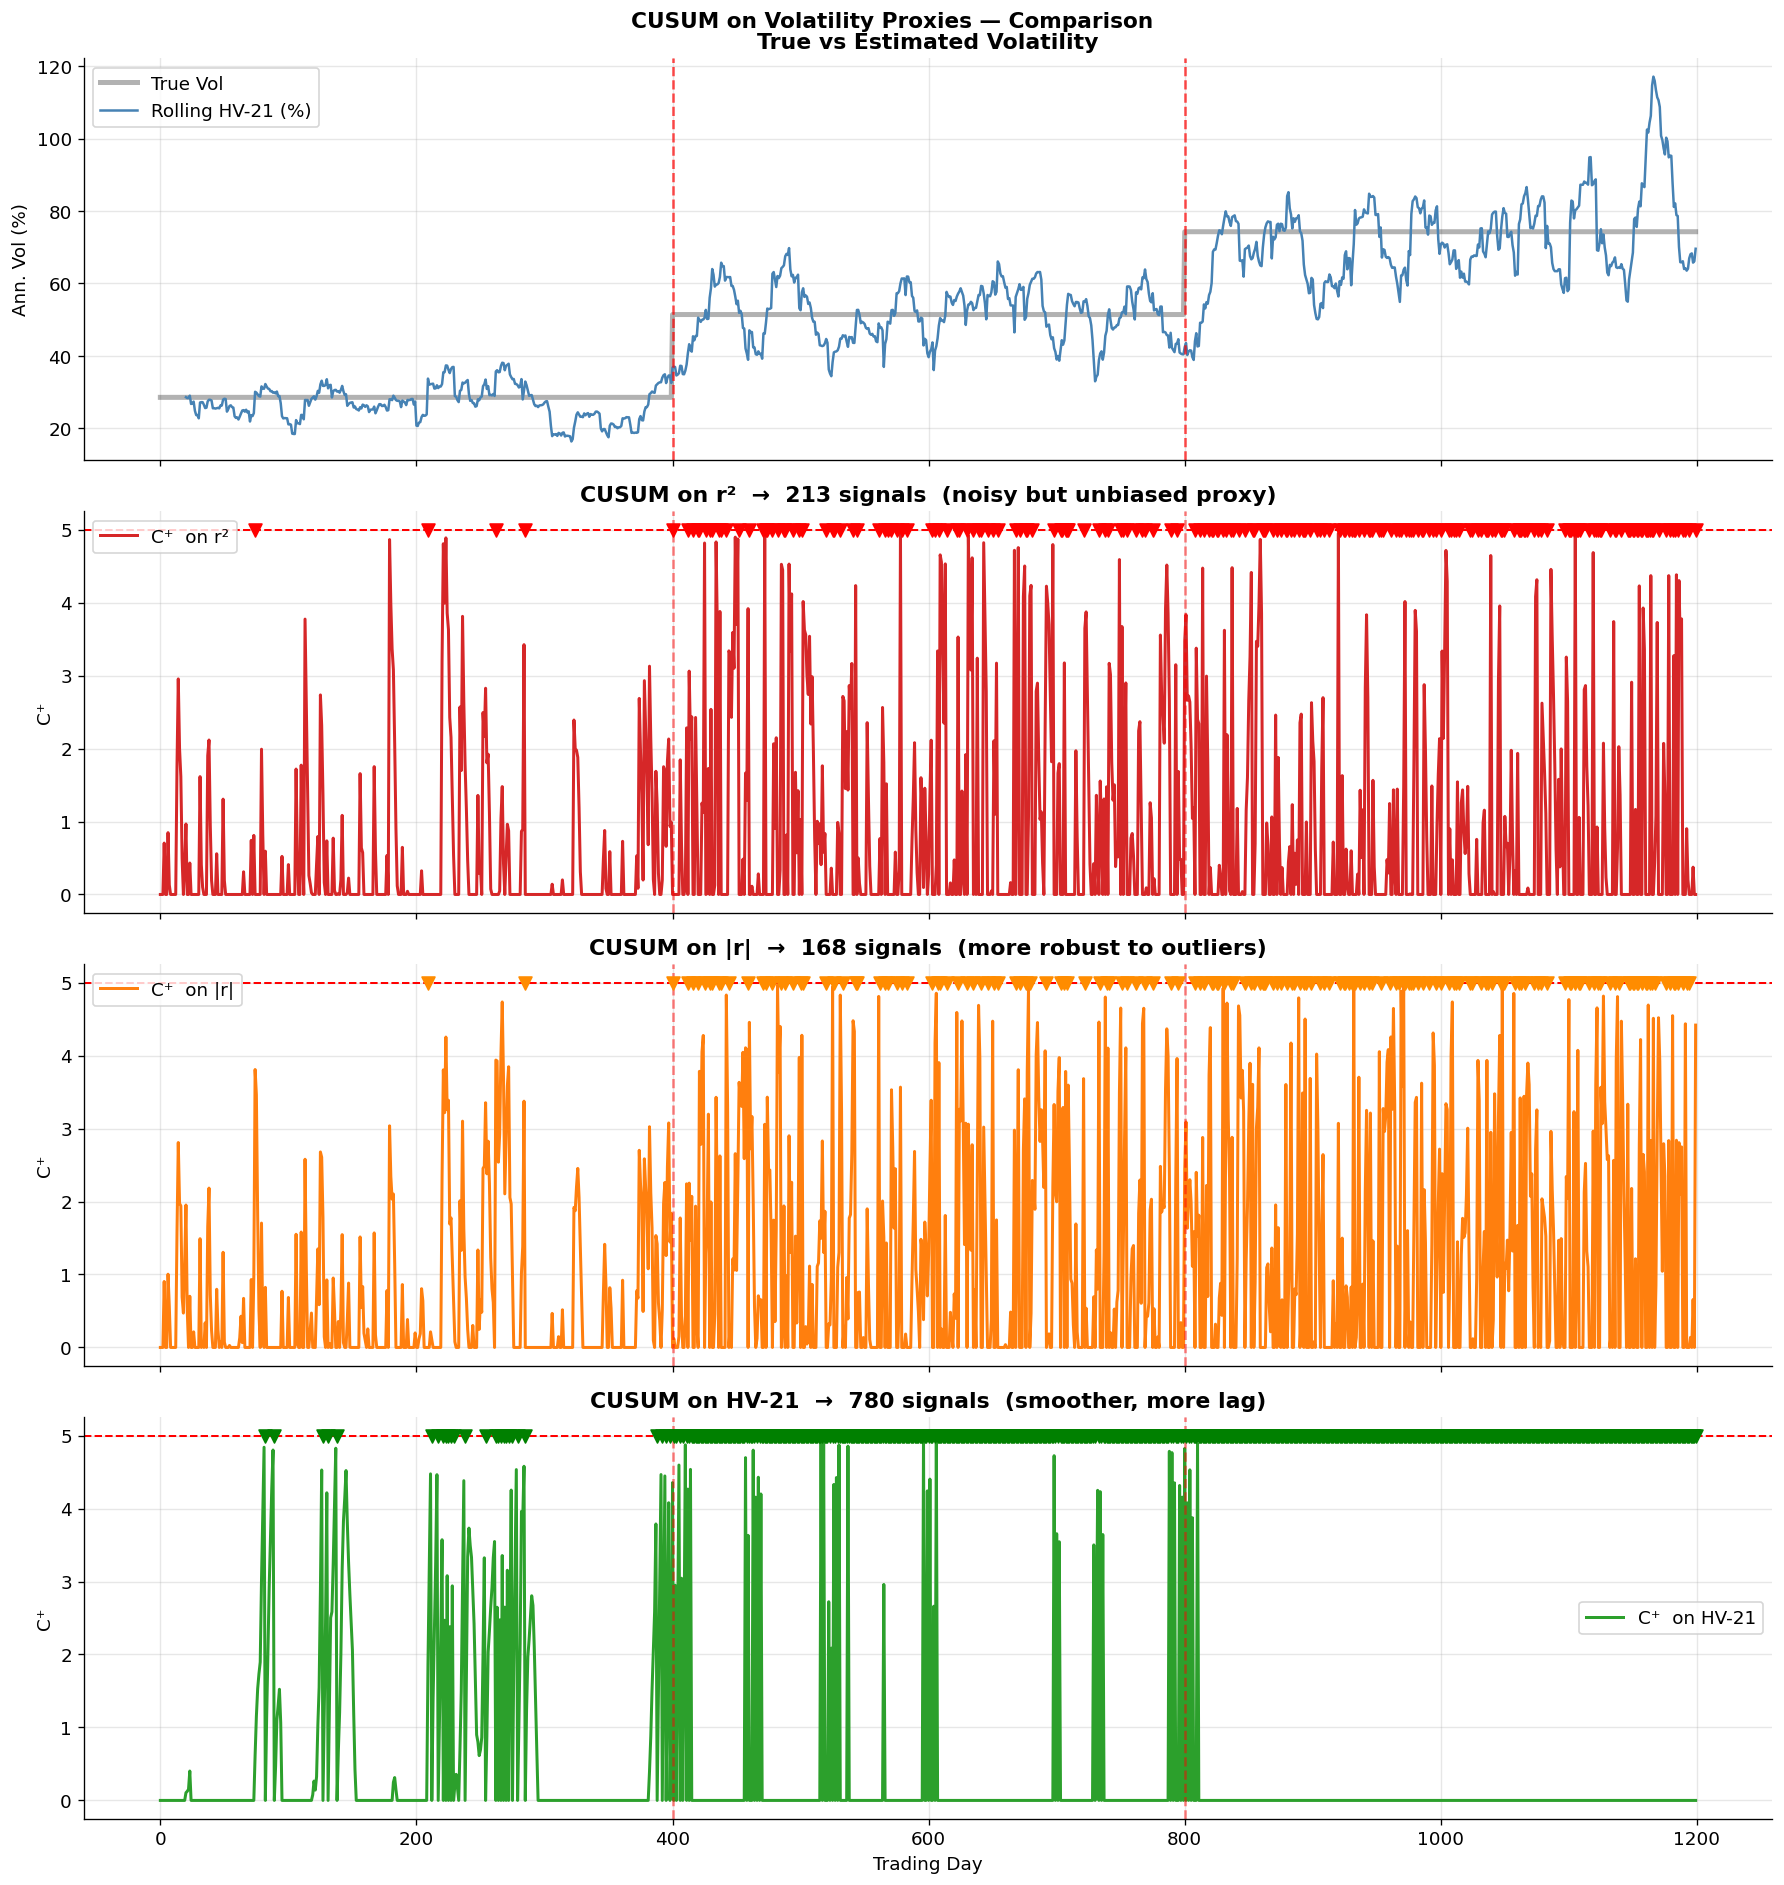

  Regime change at days: [400, 800]
  CUSUM on r²:   213 signals  | first signal at day 74
  CUSUM on |r|:  168 signals  | first signal at day 209
  CUSUM on HV21: 780 signals  | first signal at day 82


In [10]:

# ── 4.4 CUSUM on squared returns (variance proxy) ─────────────────────────────
sigma0_sq   = sigma0**2          # in-control variance
sq_rets     = log_rets**2        # r_t^2
abs_rets    = np.abs(log_rets)   # |r_t|

# Standardise squared returns: E[r²] = σ², Var[r²] = 2σ⁴  =>  std(r²) = √2·σ²
z_sq  = (sq_rets  - sigma0_sq)  / (np.sqrt(2) * sigma0_sq)

# Standardise absolute returns: E[|r|] = σ√(2/π), Var[|r|] = σ²(1 - 2/π)
mu_abs    = sigma0 * np.sqrt(2 / np.pi)
std_abs   = sigma0 * np.sqrt(1 - 2 / np.pi)
z_abs     = (abs_rets - mu_abs) / std_abs

k_vol, h_vol = 0.5, 5.0

Cu_sq,  sigs_sq  = cusum_one_sided(sq_rets,  k=k_vol, h=h_vol,
                                    mu0=sigma0_sq, sigma=np.sqrt(2)*sigma0_sq)
Cu_abs, sigs_abs = cusum_one_sided(abs_rets, k=k_vol, h=h_vol,
                                    mu0=mu_abs,    sigma=std_abs)

# Rolling HV (21-day) CUSUM
hv21 = pd.Series(log_rets).rolling(21).std().values * ANN * 100
hv21_mu  = np.nanmean(hv21[:burn])
hv21_sig = np.nanstd(hv21[:burn], ddof=1)
Cu_hv, sigs_hv = cusum_one_sided(hv21, k=k_vol, h=h_vol,
                                   mu0=hv21_mu, sigma=hv21_sig)

fig, axes = plt.subplots(4, 1, figsize=(15, 16), sharex=True)

# Panel 1: true vol + rolling HV
axes[0].plot(t, true_ann, 'k-', linewidth=3, alpha=0.3, label='True Vol')
axes[0].plot(t, hv21, color='steelblue', linewidth=1.5, label='Rolling HV-21 (%)')
for cp in chg_pts:
    axes[0].axvline(cp, color='red', linestyle='--', alpha=0.7)
axes[0].set_title('True vs Estimated Volatility', fontweight='bold')
axes[0].set_ylabel('Ann. Vol (%)')
axes[0].legend()

# Panel 2: CUSUM on squared returns
axes[1].plot(t, Cu_sq, color='#d62728', linewidth=1.8, label='C⁺  on r²')
axes[1].axhline(h_vol, color='red', linestyle='--', linewidth=1.2)
for cp in chg_pts:
    axes[1].axvline(cp, color='red', linestyle='--', alpha=0.5)
if len(sigs_sq):
    axes[1].scatter(sigs_sq, np.full(len(sigs_sq), h_vol),
                    marker='v', color='red', s=60, zorder=5)
axes[1].set_title(f'CUSUM on r²  →  {len(sigs_sq)} signals  (noisy but unbiased proxy)',
                  fontweight='bold')
axes[1].set_ylabel('C⁺')
axes[1].legend()

# Panel 3: CUSUM on |r|
axes[2].plot(t, Cu_abs, color='#ff7f0e', linewidth=1.8, label='C⁺  on |r|')
axes[2].axhline(h_vol, color='red', linestyle='--', linewidth=1.2)
for cp in chg_pts:
    axes[2].axvline(cp, color='red', linestyle='--', alpha=0.5)
if len(sigs_abs):
    axes[2].scatter(sigs_abs, np.full(len(sigs_abs), h_vol),
                    marker='v', color='darkorange', s=60, zorder=5)
axes[2].set_title(f'CUSUM on |r|  →  {len(sigs_abs)} signals  (more robust to outliers)',
                  fontweight='bold')
axes[2].set_ylabel('C⁺')
axes[2].legend()

# Panel 4: CUSUM on rolling HV
axes[3].plot(t, Cu_hv, color='#2ca02c', linewidth=1.8, label='C⁺  on HV-21')
axes[3].axhline(h_vol, color='red', linestyle='--', linewidth=1.2)
for cp in chg_pts:
    axes[3].axvline(cp, color='red', linestyle='--', alpha=0.5)
if len(sigs_hv):
    axes[3].scatter(sigs_hv, np.full(len(sigs_hv), h_vol),
                    marker='v', color='green', s=60, zorder=5)
axes[3].set_title(f'CUSUM on HV-21  →  {len(sigs_hv)} signals  (smoother, more lag)',
                  fontweight='bold')
axes[3].set_ylabel('C⁺')
axes[3].set_xlabel('Trading Day')
axes[3].legend()

plt.suptitle('CUSUM on Volatility Proxies — Comparison', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

print(f'  Regime change at days: {chg_pts}')
print(f'  CUSUM on r²:   {len(sigs_sq):3d} signals  | first signal at day {sigs_sq[0] if len(sigs_sq) else "none"}')
print(f'  CUSUM on |r|:  {len(sigs_abs):3d} signals  | first signal at day {sigs_abs[0] if len(sigs_abs) else "none"}')
print(f'  CUSUM on HV21: {len(sigs_hv):3d} signals  | first signal at day {sigs_hv[0] if len(sigs_hv) else "none"}')

### 4.5 Two-Sided CUSUM on Volatility

A two-sided CUSUM on squared returns detects both volatility **spikes** ($C^+$ fires) and **drops** ($C^-$ fires). This is useful for risk management: a spike triggers position reduction, while a drop may permit re-leveraging.

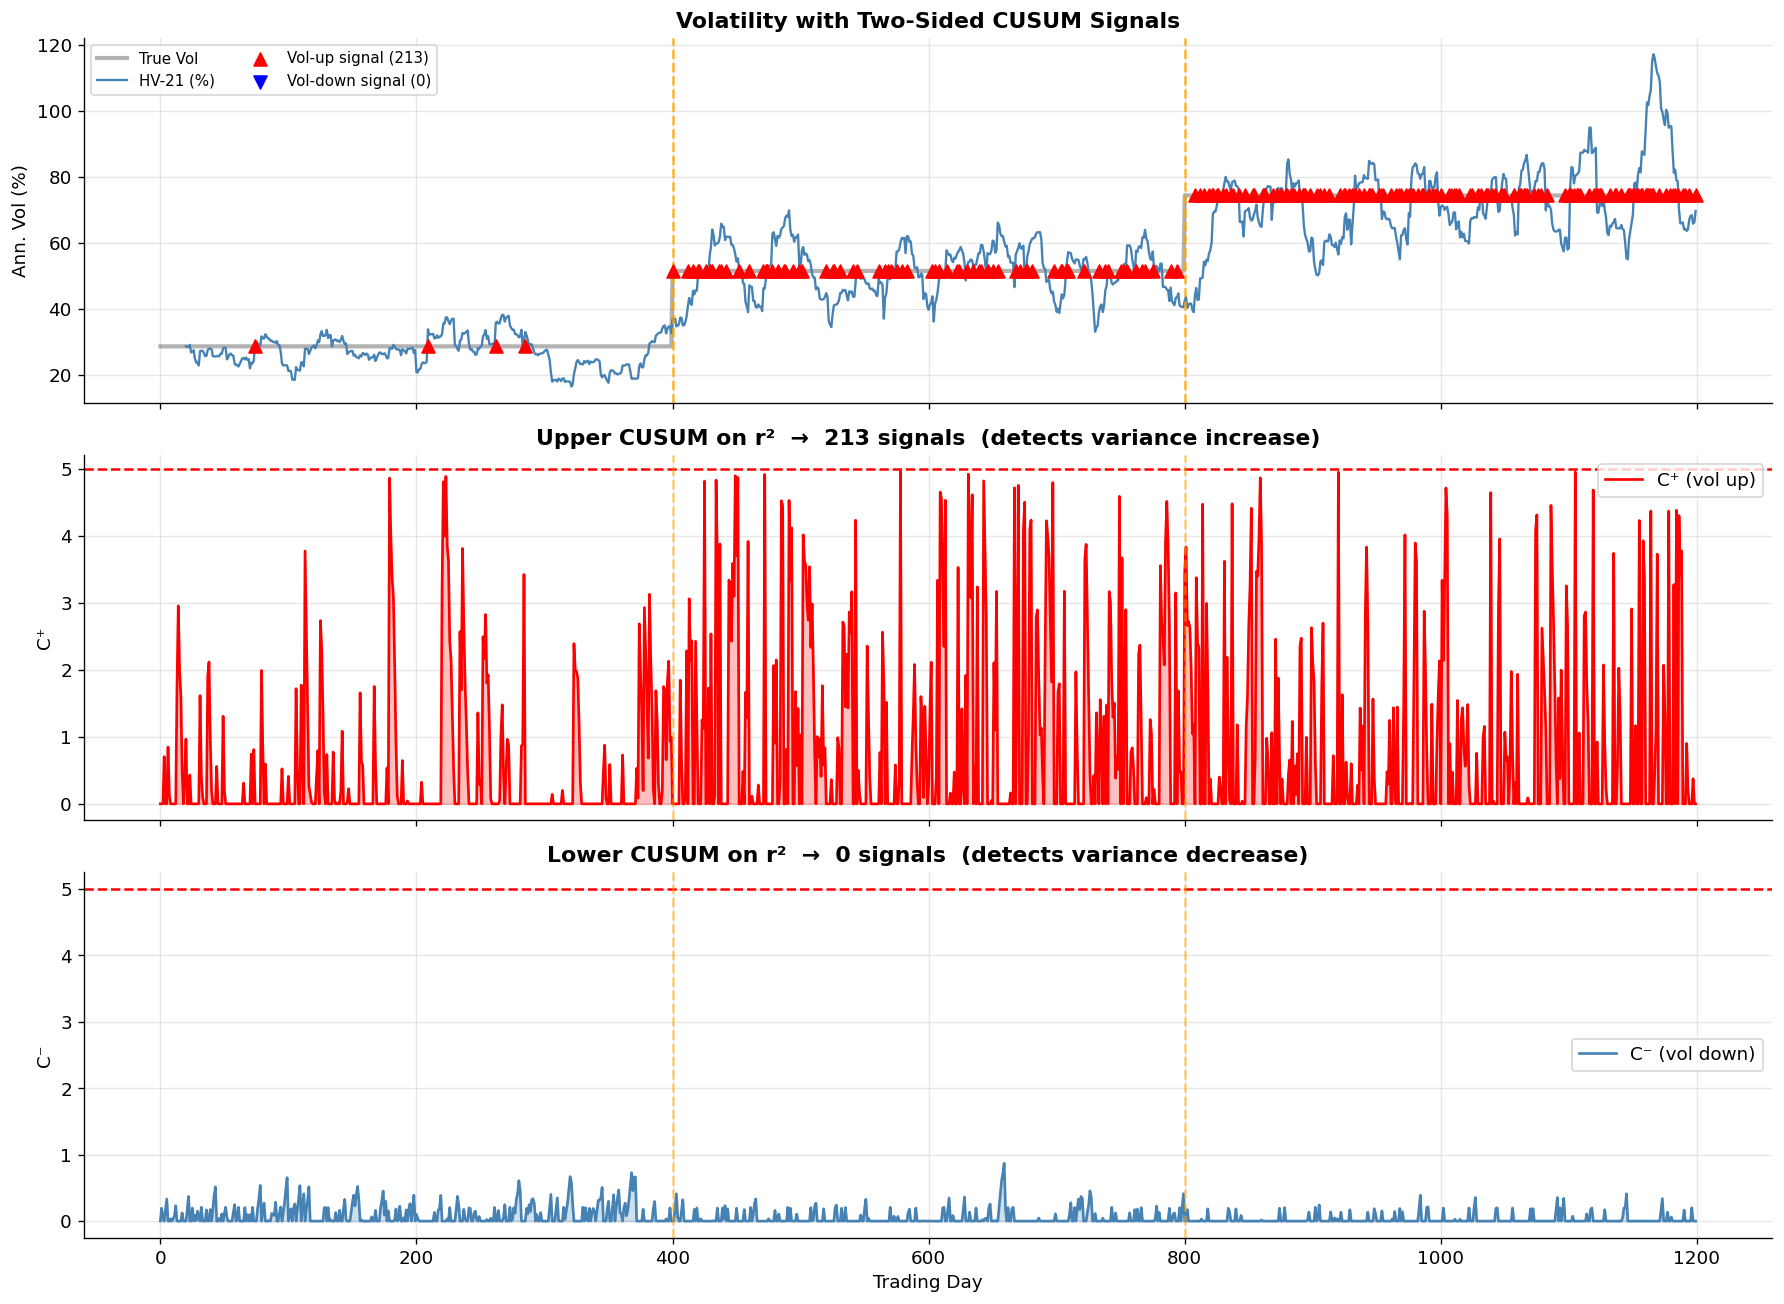

In [11]:

# ── 4.5 Two-sided CUSUM on volatility — detect both spikes AND drops ──────────
Cu_vol2, Cl_vol2, up_vol, dn_vol = cusum_two_sided(
    sq_rets, k=k_vol, h=h_vol,
    mu0=sigma0_sq, sigma=np.sqrt(2)*sigma0_sq, reset=True
)

fig, axes = plt.subplots(3, 1, figsize=(15, 11), sharex=True)

axes[0].plot(t, true_ann, 'k-', linewidth=2.5, alpha=0.3, label='True Vol')
axes[0].plot(t, hv21, color='steelblue', linewidth=1.4, label='HV-21 (%)')
axes[0].scatter(up_vol, true_ann[up_vol], marker='^', color='red', s=60,
                zorder=6, label=f'Vol-up signal ({len(up_vol)})')
axes[0].scatter(dn_vol, true_ann[dn_vol], marker='v', color='blue', s=60,
                zorder=6, label=f'Vol-down signal ({len(dn_vol)})')
for cp in chg_pts:
    axes[0].axvline(cp, color='orange', linestyle='--', alpha=0.8)
axes[0].set_title('Volatility with Two-Sided CUSUM Signals', fontweight='bold')
axes[0].set_ylabel('Ann. Vol (%)')
axes[0].legend(ncol=2, fontsize=9)

axes[1].fill_between(t, Cu_vol2, alpha=0.25, color='red')
axes[1].plot(t, Cu_vol2, color='red', linewidth=1.6, label='C⁺ (vol up)')
axes[1].axhline(h_vol, color='red', linestyle='--')
for cp in chg_pts:
    axes[1].axvline(cp, color='orange', linestyle='--', alpha=0.5)
axes[1].set_title(f'Upper CUSUM on r²  →  {len(up_vol)} signals  (detects variance increase)',
                  fontweight='bold')
axes[1].set_ylabel('C⁺')
axes[1].legend()

axes[2].fill_between(t, Cl_vol2, alpha=0.25, color='steelblue')
axes[2].plot(t, Cl_vol2, color='steelblue', linewidth=1.6, label='C⁻ (vol down)')
axes[2].axhline(h_vol, color='red', linestyle='--')
for cp in chg_pts:
    axes[2].axvline(cp, color='orange', linestyle='--', alpha=0.5)
axes[2].set_title(f'Lower CUSUM on r²  →  {len(dn_vol)} signals  (detects variance decrease)',
                  fontweight='bold')
axes[2].set_ylabel('C⁻')
axes[2].set_xlabel('Trading Day')
axes[2].legend()

plt.tight_layout()
plt.show()

### 4.6 Interactive 3D — Volatility Proxy Comparison

A Plotly surface comparing CUSUM paths (no reset) for all three volatility proxies side by side. The surface height shows accumulated evidence; the ridge timing reveals the detection speed trade-off between noise and lag.

In [12]:

# ── 4.6 Plotly 3D: CUSUM on three vol proxies — comparison surface ────────────
# Side-by-side CUSUM paths for r², |r|, and HV-21 as volatility proxies

# Re-run CUSUM for all three proxies (no reset, for smooth surface)
# Squared returns
z_sq_nr = (sq_rets - sigma0_sq) / (np.sqrt(2) * sigma0_sq)
Cu_sq, _ = cusum_one_sided(sq_rets, k=k_vol, h=999,
                            mu0=sigma0_sq, sigma=np.sqrt(2)*sigma0_sq, reset=False)
# Absolute returns
mu_abs_v    = sigma0 * np.sqrt(2 / np.pi)
std_abs_v   = sigma0 * np.sqrt(1 - 2 / np.pi)
Cu_abs, _ = cusum_one_sided(abs_rets, k=k_vol, h=999,
                              mu0=mu_abs_v, sigma=std_abs_v, reset=False)
# HV-21 (annualised %)
hv21_series = pd.Series(log_rets).rolling(21).std().values * np.sqrt(252) * 100
hv21_valid  = np.nan_to_num(hv21_series, nan=0.0)
hv21_mu_v   = np.nanmean(hv21_valid[:burn])
hv21_sig_v  = np.nanstd(hv21_valid[:burn])
Cu_hv, _  = cusum_one_sided(hv21_valid, k=0.5, h=999,
                              mu0=hv21_mu_v, sigma=hv21_sig_v, reset=False)

n_show_v = min(800, n_days)
proxy_names = ['Squared Returns (r²)', 'Absolute Returns (|r|)', 'Rolling HV-21']
cusum_paths = [Cu_sq[:n_show_v], Cu_abs[:n_show_v], Cu_hv[:n_show_v]]
colors_proxy = ['#e41a1c', '#ff7f00', '#377eb8']

fig = go.Figure()
for idx, (path, name, col) in enumerate(zip(cusum_paths, proxy_names, colors_proxy)):
    # Normalise each path to [0,1] for comparison
    pmax = np.max(path) if np.max(path) > 0 else 1
    fig.add_trace(go.Scatter3d(
        x=np.arange(n_show_v),
        y=np.full(n_show_v, idx),
        z=path / pmax,
        mode='lines',
        line=dict(color=col, width=5),
        name=name,
    ))

for cp in chg_pts:
    if cp < n_show_v:
        fig.add_trace(go.Scatter3d(
            x=[cp, cp, cp], y=[0, 1, 2],
            z=[cusum_paths[j][cp] / np.max(cusum_paths[j]) for j in range(3)],
            mode='lines+markers',
            line=dict(color='red', width=3),
            marker=dict(size=5, color='red'),
            name=f'Change pt {cp}', showlegend=(cp == chg_pts[0]),
        ))

fig.update_layout(
    title='3D: CUSUM on Three Volatility Proxies — Normalised Comparison<br>'
          '<sup>Each proxy normalised to [0,1]. r² reacts fastest but noisiest; '
          'HV-21 is smoothest but most lagged</sup>',
    scene=dict(
        xaxis_title='Trading Day',
        yaxis=dict(title='Proxy', tickvals=[0,1,2],
                   ticktext=['r²', '|r|', 'HV-21']),
        zaxis_title='Normalised C⁺',
        camera=dict(eye=dict(x=1.6, y=-1.6, z=1.0)),
    ),
    height=650, width=1050, margin=dict(l=0, r=0, t=80, b=0),
)
fig.show()


---

# Part V — CUSUM on GARCH Residuals

## 5.1 Motivation: Filtering Out the Known Variance

If we already have a GARCH(1,1) model fitted on the in-control data, we can extract **standardised residuals**:

$$\varepsilon_t = \frac{r_t}{\hat{\sigma}_t^{\text{GARCH}}}$$

Under the null hypothesis (model correctly specified, regime unchanged):
$$\varepsilon_t \stackrel{iid}{\sim} \mathcal{N}(0, 1)$$

Applying CUSUM to $\varepsilon_t^2$ tests whether the **conditional variance model has broken down** — i.e., the GARCH is no longer capturing the dynamics. This is much more powerful than CUSUM on raw squared returns because we have removed the predictable component.

## 5.2 Two Tests on GARCH Residuals

| Test series | Null | Alternative |
|-------------|------|-------------|
| $\varepsilon_t$ | mean = 0 | Drift in returns not explained by GARCH |
| $\varepsilon_t^2 - 1$ | variance = 1 | Vol regime change not captured by GARCH |

## 5.3 GARCH(1,1) Recap

$$\sigma_t^2 = \omega + \alpha\, r_{t-1}^2 + \beta\, \sigma_{t-1}^2$$

We fit on the **first regime only** (burn-in), then apply the fitted model forward and monitor residuals.

### 5.4 Fitting GARCH(1,1) on the Burn-In

We fit a GARCH(1,1) model on the in-control (Regime 1) data only. The model's conditional variance $\hat\sigma_t^2$ is then extended over the full sample. Standardised residuals $\varepsilon_t = r_t / \hat\sigma_t$ should be i.i.d. $\mathcal{N}(0,1)$ if the model remains valid. Applying CUSUM to $\varepsilon_t^2$ tests whether the variance model has broken down — i.e., whether a regime change has occurred that GARCH cannot absorb.

GARCH fit (burn-in):  ω=5.00e-05  α=0.0000  β=0.8225  α+β=0.8225


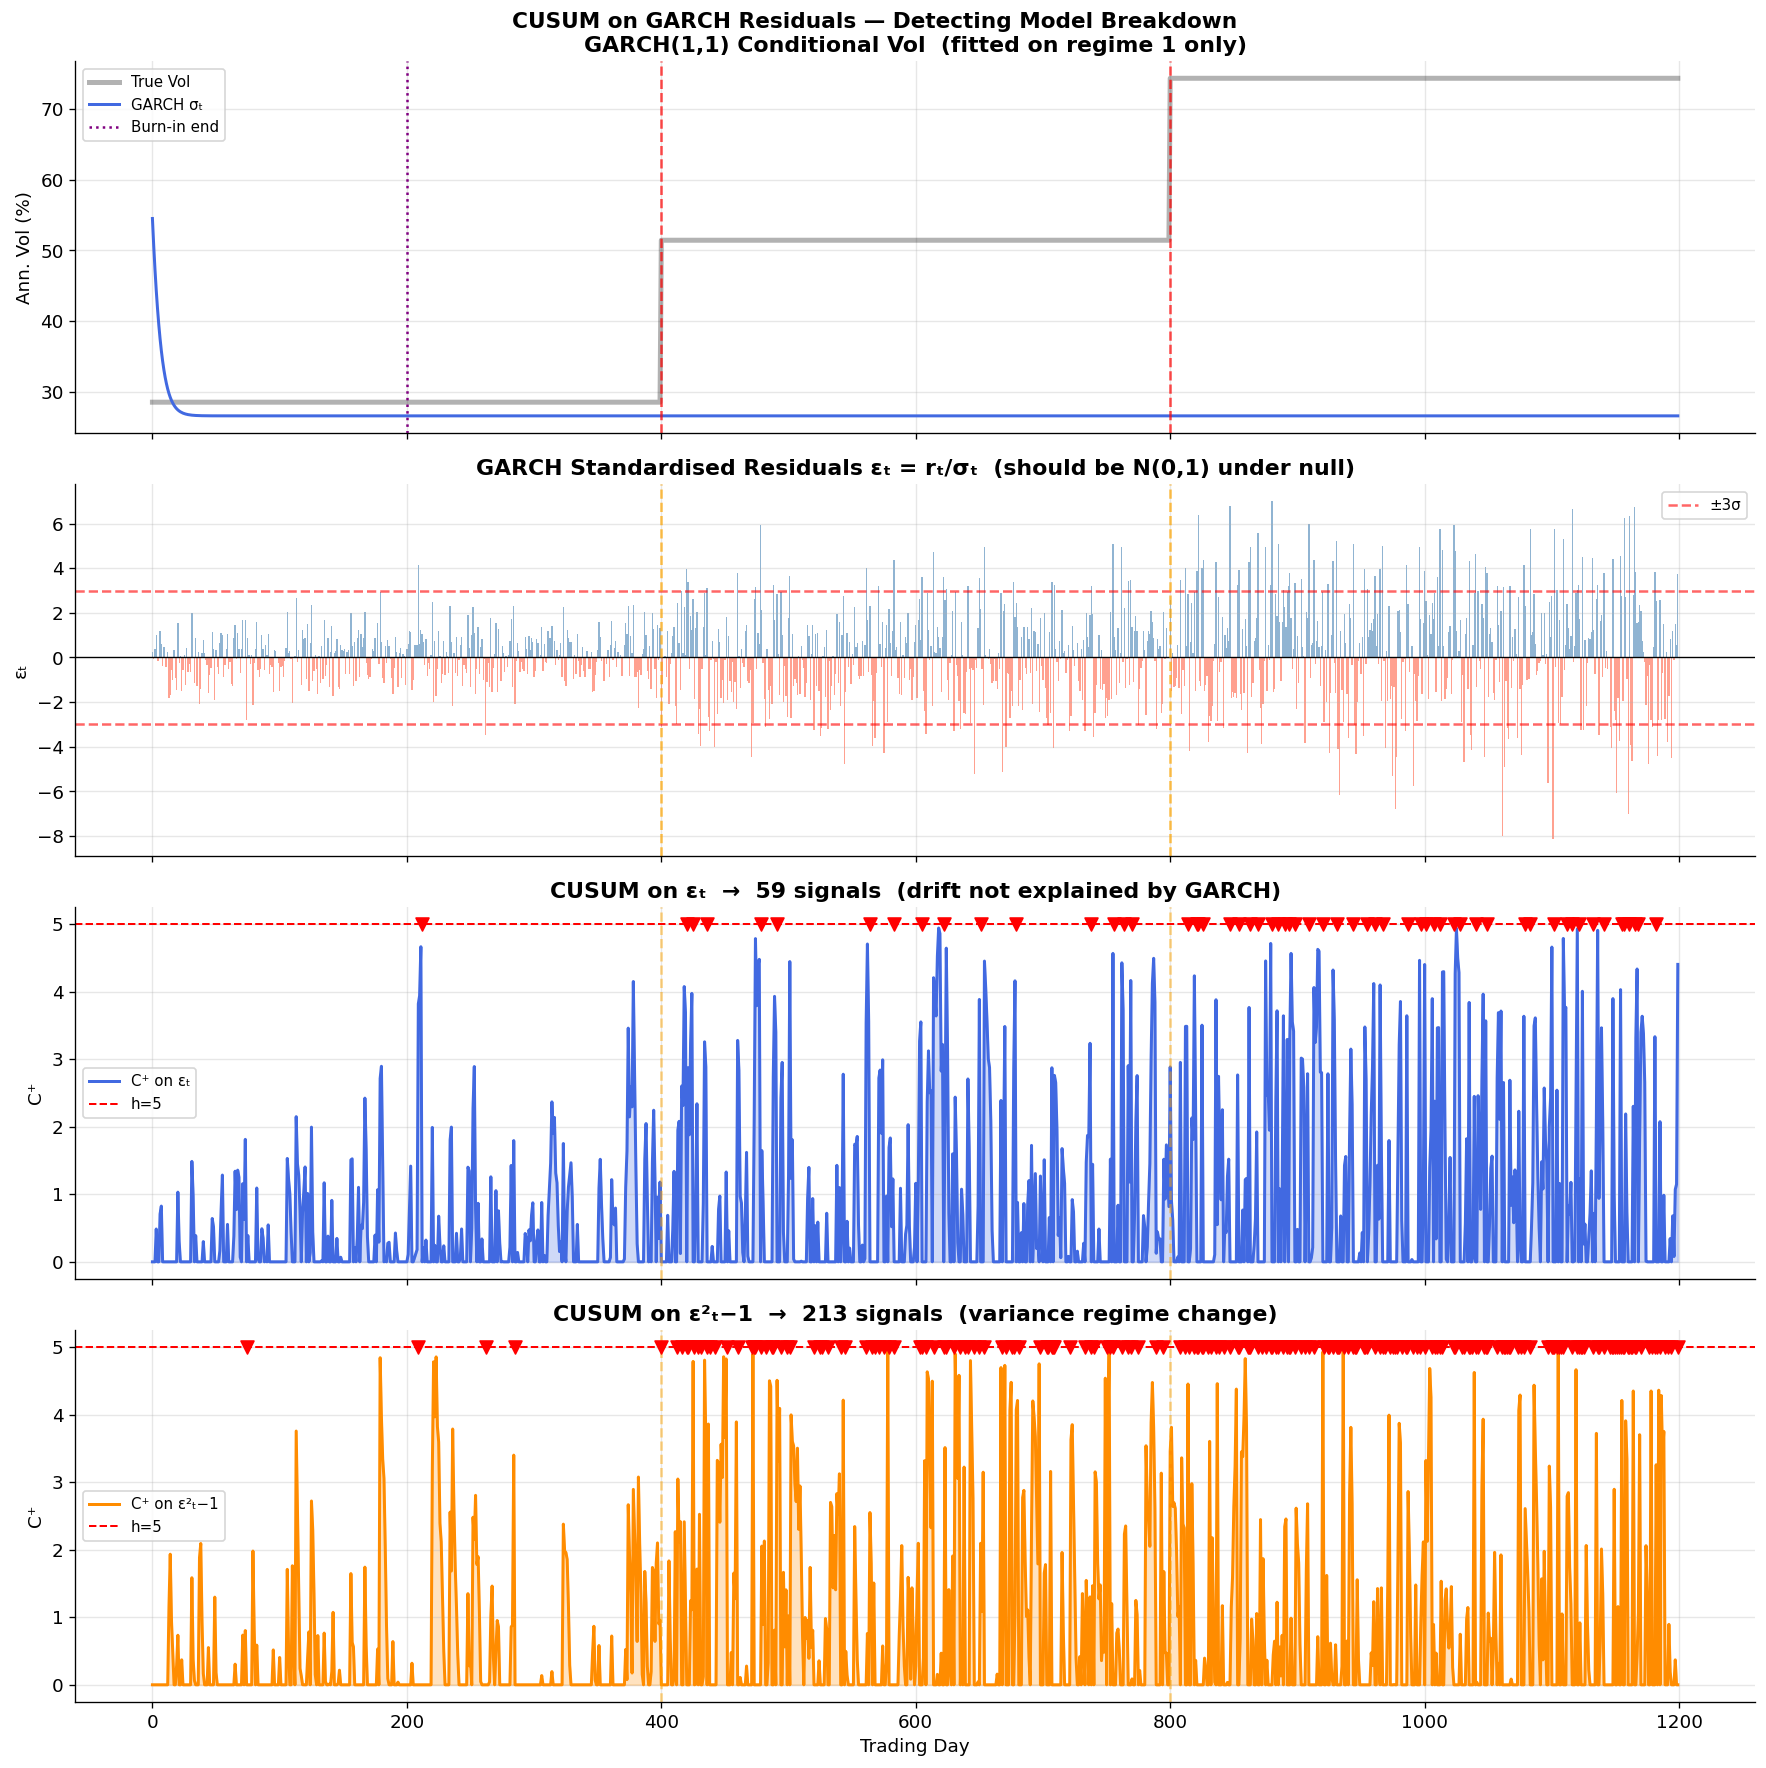


Residual diagnostics (full series):
  mean(ε):    0.0867   (expect ≈ 0)
  std(ε):     2.0442   (expect ≈ 1)
  mean(ε²):   4.1861  (expect ≈ 1)
  Regime 1 mean(ε²): 1.0422  (should be ≈ 1)
  Regime 2 mean(ε²): 3.7749  (will be > 1 — GARCH underestimates)
  Regime 3 mean(ε²): 7.7412


In [13]:

from scipy.optimize import minimize

# ── 5.4 Fit GARCH(1,1) on burn-in (regime 1 only) ───────────────────────────
def garch_variance_path(rets, omega, alpha, beta):
    n = len(rets); s2 = np.zeros(n)
    s2[0] = np.var(rets)
    for i in range(1, n):
        s2[i] = omega + alpha * rets[i-1]**2 + beta * s2[i-1]
    return s2

def garch_nll(params, rets):
    o, a, b = params
    if o <= 0 or a < 0 or b < 0 or a + b >= 0.9999: return 1e10
    s2 = garch_variance_path(rets, o, a, b)
    if np.any(s2 <= 0): return 1e10
    return 0.5 * np.sum(np.log(2*np.pi*s2) + rets**2/s2)

def fit_garch(rets):
    var0 = np.var(rets)
    bounds = [(1e-8, None), (1e-6, 0.40), (1e-6, 0.97)]
    best, best_ll = None, np.inf
    for a0, b0 in [(0.06, 0.92), (0.10, 0.85), (0.15, 0.80)]:
        x0 = [var0*(1-a0-b0), a0, b0]
        r  = minimize(garch_nll, x0, args=(rets,), method='L-BFGS-B', bounds=bounds,
                      options={'maxiter': 10000, 'ftol': 1e-14})
        if r.fun < best_ll:
            best_ll = r.fun; best = r
    return best.x

# Fit on burn-in returns (regime 1)
rets_burn = log_rets[:burn]
omega_hat, alpha_hat, beta_hat = fit_garch(rets_burn)
print(f'GARCH fit (burn-in):  ω={omega_hat:.2e}  α={alpha_hat:.4f}  β={beta_hat:.4f}  α+β={alpha_hat+beta_hat:.4f}')

# Apply forward to full series (propagate variance path)
s2_full = garch_variance_path(log_rets, omega_hat, alpha_hat, beta_hat)
eps     = log_rets / np.sqrt(s2_full)           # standardised residuals
eps_sq  = eps**2                                  # should be ~χ²(1) under null

# ── 5.5 CUSUM on GARCH residuals ─────────────────────────────────────────────
# Test 1: CUSUM on ε_t (tests for unexplained drift in returns)
Cu_eps, sigs_eps = cusum_one_sided(eps, k=0.5, h=5.0, mu0=0.0, sigma=1.0)

# Test 2: CUSUM on ε²_t - 1 (tests for unexplained variance jump)
# Under null: E[ε²] = 1, Var[ε²] = 2  =>  std(ε²-1) = √2
Cu_eps2, sigs_eps2 = cusum_one_sided(eps_sq - 1, k=0.5, h=5.0, mu0=0.0, sigma=np.sqrt(2))

fig, axes = plt.subplots(4, 1, figsize=(15, 15), sharex=True)

# Panel 1: GARCH conditional vol overlaid on true vol
sigma_garch_ann = np.sqrt(s2_full) * ANN * 100
axes[0].plot(t, true_ann, 'k-', linewidth=3, alpha=0.3, label='True Vol')
axes[0].plot(t, sigma_garch_ann, color='royalblue', linewidth=1.8, label='GARCH σₜ')
for cp in chg_pts:
    axes[0].axvline(cp, color='red', linestyle='--', alpha=0.7)
axes[0].axvline(burn, color='purple', linestyle=':', linewidth=1.5, label='Burn-in end')
axes[0].set_title('GARCH(1,1) Conditional Vol  (fitted on regime 1 only)', fontweight='bold')
axes[0].set_ylabel('Ann. Vol (%)')
axes[0].legend(fontsize=9)

# Panel 2: standardised residuals
axes[1].bar(t, eps, color=np.where(eps > 0, 'steelblue', 'tomato'), alpha=0.6, width=1)
axes[1].axhline(0, color='k', linewidth=0.8)
axes[1].axhline(3, color='red', linestyle='--', alpha=0.6, label='±3σ')
axes[1].axhline(-3, color='red', linestyle='--', alpha=0.6)
for cp in chg_pts:
    axes[1].axvline(cp, color='orange', linestyle='--', alpha=0.7)
axes[1].set_title('GARCH Standardised Residuals εₜ = rₜ/σₜ  (should be N(0,1) under null)',
                  fontweight='bold')
axes[1].set_ylabel('εₜ')
axes[1].legend(fontsize=9)

# Panel 3: CUSUM on ε
axes[2].fill_between(t, Cu_eps, alpha=0.25, color='royalblue')
axes[2].plot(t, Cu_eps, color='royalblue', linewidth=1.8, label='C⁺ on εₜ')
axes[2].axhline(5.0, color='red', linestyle='--', linewidth=1.2, label='h=5')
for cp in chg_pts:
    axes[2].axvline(cp, color='orange', linestyle='--', alpha=0.5)
if len(sigs_eps):
    axes[2].scatter(sigs_eps, np.full(len(sigs_eps), 5.0),
                    marker='v', color='red', s=60, zorder=5)
axes[2].set_title(f'CUSUM on εₜ  →  {len(sigs_eps)} signals  (drift not explained by GARCH)',
                  fontweight='bold')
axes[2].set_ylabel('C⁺')
axes[2].legend(fontsize=9)

# Panel 4: CUSUM on ε²-1
axes[3].fill_between(t, Cu_eps2, alpha=0.25, color='darkorange')
axes[3].plot(t, Cu_eps2, color='darkorange', linewidth=1.8, label='C⁺ on ε²ₜ−1')
axes[3].axhline(5.0, color='red', linestyle='--', linewidth=1.2, label='h=5')
for cp in chg_pts:
    axes[3].axvline(cp, color='orange', linestyle='--', alpha=0.5)
if len(sigs_eps2):
    axes[3].scatter(sigs_eps2, np.full(len(sigs_eps2), 5.0),
                    marker='v', color='red', s=60, zorder=5)
axes[3].set_title(f'CUSUM on ε²ₜ−1  →  {len(sigs_eps2)} signals  (variance regime change)',
                  fontweight='bold')
axes[3].set_ylabel('C⁺')
axes[3].set_xlabel('Trading Day')
axes[3].legend(fontsize=9)

plt.suptitle('CUSUM on GARCH Residuals — Detecting Model Breakdown', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

# Residual diagnostics
print(f'\nResidual diagnostics (full series):')
print(f'  mean(ε):    {eps.mean():.4f}   (expect ≈ 0)')
print(f'  std(ε):     {eps.std():.4f}   (expect ≈ 1)')
print(f'  mean(ε²):   {eps_sq.mean():.4f}  (expect ≈ 1)')
print(f'  Regime 1 mean(ε²): {eps_sq[:chg_pts[0]].mean():.4f}  (should be ≈ 1)')
print(f'  Regime 2 mean(ε²): {eps_sq[chg_pts[0]:chg_pts[1]].mean():.4f}  (will be > 1 — GARCH underestimates)')
print(f'  Regime 3 mean(ε²): {eps_sq[chg_pts[1]:].mean():.4f}')

### 5.6 Residual QQ-Plots by Regime

QQ-plots of the GARCH residuals split by regime. In-control residuals should lie on the diagonal; deviations indicate the GARCH model is mis-specified for that regime — exactly what the CUSUM on $\varepsilon_t^2$ will detect.

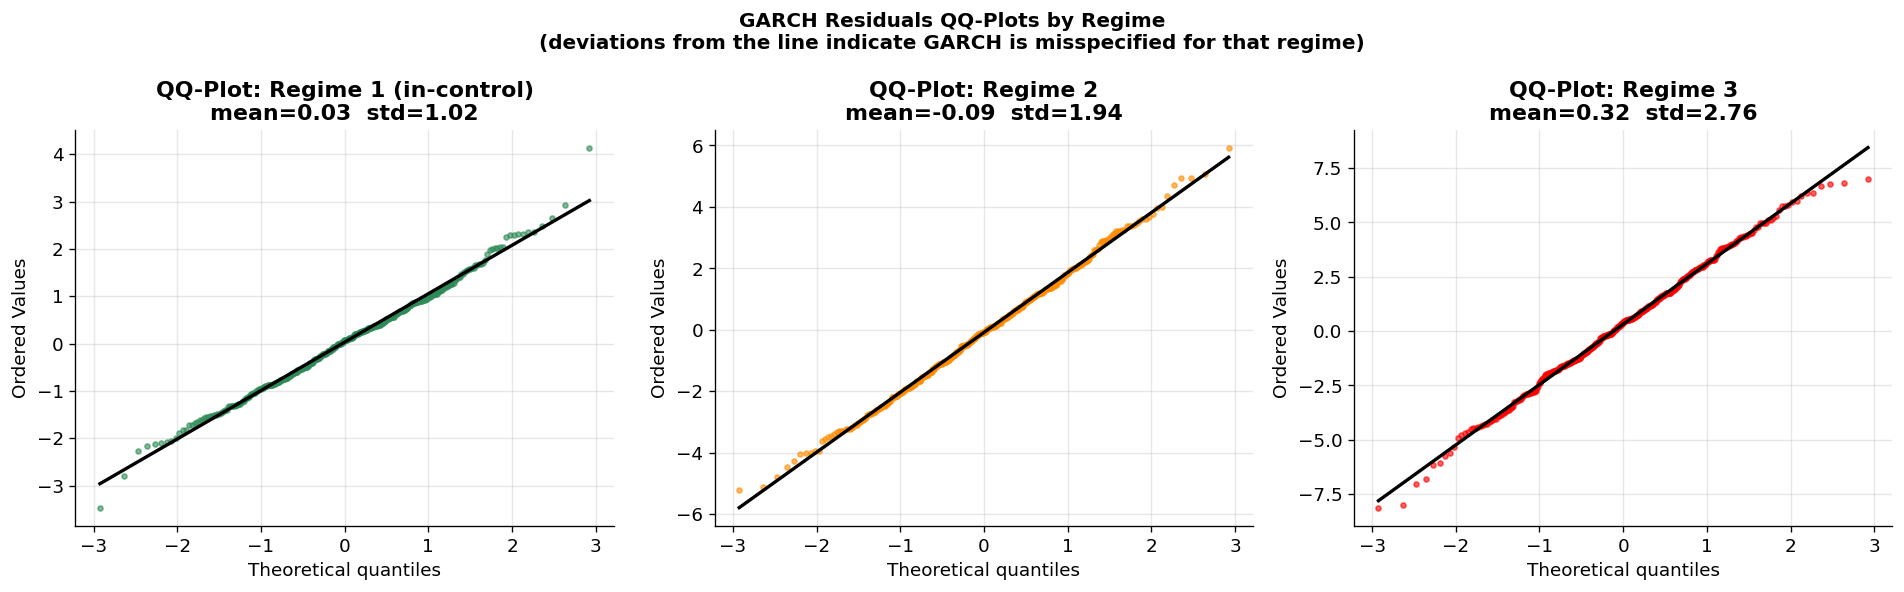

In [14]:

# ── 5.6 Residual QQ-plot — before and after regime change ────────────────────
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

segments = [
    (slice(0, chg_pts[0]),          'Regime 1 (in-control)', 'seagreen'),
    (slice(chg_pts[0], chg_pts[1]), 'Regime 2',              'darkorange'),
    (slice(chg_pts[1], None),       'Regime 3',              'red'),
]
for ax, (sl, lbl, col) in zip(axes, segments):
    e_seg = eps[sl]
    stats.probplot(e_seg, dist='norm', plot=ax)
    ax.get_lines()[0].set(color=col, alpha=0.6, markersize=3)
    ax.get_lines()[1].set(color='k', linewidth=2)
    ax.set_title(f'QQ-Plot: {lbl}\nmean={e_seg.mean():.2f}  std={e_seg.std():.2f}', fontweight='bold')

plt.suptitle('GARCH Residuals QQ-Plots by Regime\n'
             '(deviations from the line indicate GARCH is misspecified for that regime)',
             fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

### 5.7 Interactive 3D — GARCH Residual CUSUM over Threshold $h$

A Plotly surface sweeping the decision threshold $h$ from 2 to 10 over time. At low $h$, the detector fires early but with many resets; at high $h$, only the strongest regime break triggers a signal. The surface makes the speed-vs-reliability trade-off tangible.

In [15]:

# ── 5.7 Plotly 3D: GARCH residual CUSUM surface over (time, threshold h) ─────
# Shows how the GARCH residual CUSUM detector fires at different thresholds

h_sweep_garch = np.arange(2.0, 10.1, 0.5)
n_show_g = min(800, n_days)

C_garch_surface = np.zeros((len(h_sweep_garch), n_show_g))
signal_density  = np.zeros((len(h_sweep_garch), n_show_g))

for i, hh in enumerate(h_sweep_garch):
    Cu_g, sigs_g = cusum_one_sided(eps[:n_show_g]**2, k=0.5, h=hh,
                                     mu0=1.0, sigma=np.sqrt(2.0), reset=True)
    C_garch_surface[i] = Cu_g
    for s in sigs_g:
        if s < n_show_g:
            signal_density[i, max(0, s-5):min(n_show_g, s+5)] = 1

T_g2, H_g2 = np.meshgrid(np.arange(n_show_g), h_sweep_garch)

fig = go.Figure(go.Surface(
    x=T_g2, y=H_g2, z=C_garch_surface,
    colorscale='Inferno',
    colorbar=dict(title='C⁺ on ε²', len=0.65),
    hovertemplate='Day=%{x}<br>h=%{y:.1f}<br>C⁺=%{z:.2f}<extra></extra>',
    opacity=0.9,
))
for cp in chg_pts:
    if cp < n_show_g:
        fig.add_trace(go.Scatter3d(
            x=[cp]*len(h_sweep_garch), y=h_sweep_garch,
            z=C_garch_surface[:, cp],
            mode='lines', line=dict(color='cyan', width=5),
            name=f'Regime change {cp}',
        ))
fig.update_layout(
    title='3D: GARCH Residual CUSUM — Threshold Sensitivity Surface<br>'
          '<sup>Low h (front) = many resets/signals; High h (back) = fewer but more certain. '
          'Cyan = true change points</sup>',
    scene=dict(
        xaxis_title='Trading Day',
        yaxis_title='Threshold h',
        zaxis_title='C⁺ on ε²',
        camera=dict(eye=dict(x=1.5, y=-1.7, z=1.0)),
    ),
    height=650, width=1050, margin=dict(l=0, r=0, t=80, b=0),
)
fig.show()


---

# Part VI — Average Run Length (ARL) Analysis

## 6.1 What is ARL?

**Average Run Length (ARL)** is the expected number of observations until the CUSUM fires a signal.

- **ARL₀** — when the process is *in control* (no shift): want this **large** to avoid false alarms
- **ARL₁(δ)** — when the process has shifted by δσ: want this **small** for fast detection

The fundamental trade-off: any attempt to reduce ARL₁ (faster detection) also reduces ARL₀ (more false alarms). The pair $(k, h)$ controls exactly this trade-off.

## 6.2 Analytical ARL for the Normal CUSUM

For the one-sided normal CUSUM with standardised observations, the Siegmund (1985) approximation gives:

$$\text{ARL}_0 \approx \frac{e^{2\Delta(h + 1.166)} - 2\Delta(h + 1.166) - 1}{2\Delta^2}, \quad \Delta = k$$

For the out-of-control ARL with shift $\delta$ (in σ units):

$$\text{ARL}_1(\delta) \approx \frac{e^{-2(\delta - k)(h - 0.583/(\delta-k))} - 1}{-2(\delta-k)(\delta - 2k)} \quad \text{for } \delta > k$$

In practice we use **Monte Carlo simulation** which is exact and works for any input distribution.

## 6.3 Monte Carlo ARL Estimation

Simulate many i.i.d. series under a given shift $\delta$, run CUSUM, record the run length each time, and average.

### 6.4 Monte Carlo ARL Estimation

We define a Monte Carlo function that simulates $N(\delta, 1)$ observations into a one-sided CUSUM and records the run length until the first signal. With $\delta = 0$ this gives **ARL₀** (in-control); with $\delta > 0$ it gives **ARL₁** (out-of-control). We then sweep over $h$ to show how the threshold controls the ARL trade-off.

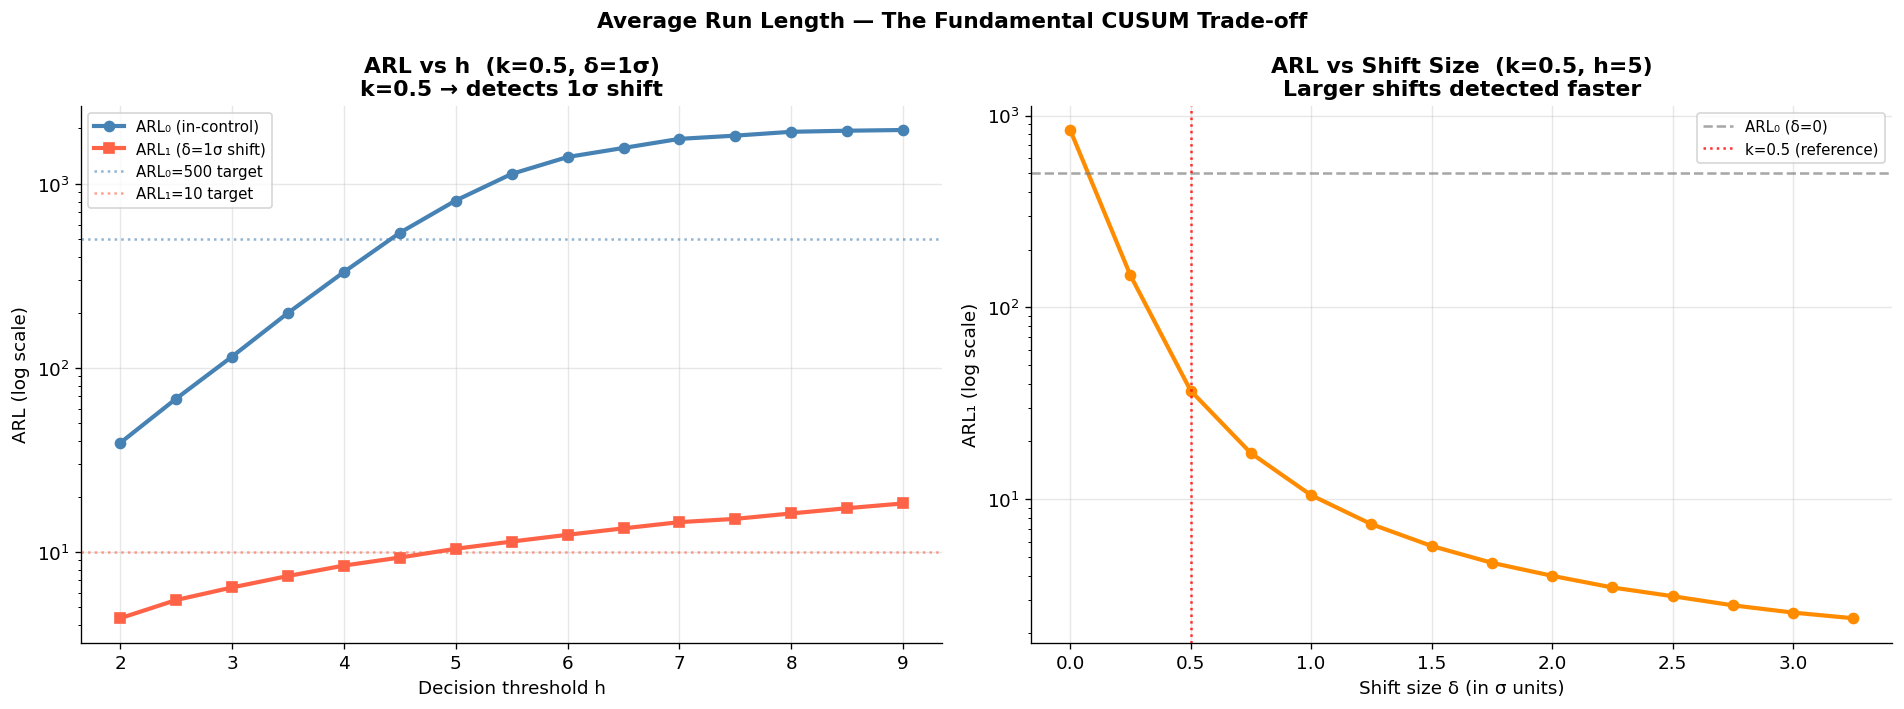

ARL₀ targets for k=0.5:
  h=2.0: ARL₀=    39  ARL₁(1σ)=  4.4
  h=2.5: ARL₀=    68  ARL₁(1σ)=  5.5
  h=3.0: ARL₀=   115  ARL₁(1σ)=  6.4
  h=3.5: ARL₀=   199  ARL₁(1σ)=  7.4
  h=4.0: ARL₀=   332  ARL₁(1σ)=  8.4
  h=4.5: ARL₀=   542  ARL₁(1σ)=  9.3
  h=5.0: ARL₀=   812  ARL₁(1σ)= 10.4
  h=5.5: ARL₀=  1132  ARL₁(1σ)= 11.4
  h=6.0: ARL₀=  1399  ARL₁(1σ)= 12.4
  h=6.5: ARL₀=  1568  ARL₁(1σ)= 13.4
  h=7.0: ARL₀=  1756  ARL₁(1σ)= 14.5
  h=7.5: ARL₀=  1829  ARL₁(1σ)= 15.1
  h=8.0: ARL₀=  1919  ARL₁(1σ)= 16.2
  h=8.5: ARL₀=  1945  ARL₁(1σ)= 17.3
  h=9.0: ARL₀=  1962  ARL₁(1σ)= 18.4


In [16]:

# ── 6.4 Monte Carlo ARL ────────────────────────────────────────────────────────
def mc_arl(k, h, delta=0.0, n_sim=3000, max_run=2000):
    """
    Monte Carlo ARL for one-sided upper CUSUM on N(delta,1) observations.
    delta=0 -> ARL0, delta>0 -> ARL1.
    """
    rls = np.empty(n_sim)
    for i in range(n_sim):
        C = 0.0
        for j in range(1, max_run + 1):
            x = np.random.normal(delta, 1.0)
            C = max(0.0, C + x - k)
            if C > h:
                rls[i] = j
                break
        else:
            rls[i] = max_run
    return rls.mean(), rls.std()

# ARL curves: fix k=0.5, vary h — compute ARL0 and ARL1(delta=1)
np.random.seed(0)
h_grid    = np.arange(2.0, 9.5, 0.5)
arl0_vals = []
arl1_vals = []

for hh in h_grid:
    a0, _ = mc_arl(k=0.5, h=hh, delta=0.0, n_sim=2000)
    a1, _ = mc_arl(k=0.5, h=hh, delta=1.0, n_sim=2000)
    arl0_vals.append(a0)
    arl1_vals.append(a1)

arl0_vals = np.array(arl0_vals)
arl1_vals = np.array(arl1_vals)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

ax = axes[0]
ax.semilogy(h_grid, arl0_vals, 'steelblue', linewidth=2.5, marker='o', label='ARL₀ (in-control)')
ax.semilogy(h_grid, arl1_vals, 'tomato',    linewidth=2.5, marker='s', label='ARL₁ (δ=1σ shift)')
ax.axhline(500, color='steelblue', linestyle=':', alpha=0.6, label='ARL₀=500 target')
ax.axhline(10,  color='tomato',    linestyle=':', alpha=0.6, label='ARL₁=10 target')
ax.set_xlabel('Decision threshold h')
ax.set_ylabel('ARL (log scale)')
ax.set_title('ARL vs h  (k=0.5, δ=1σ)\nk=0.5 → detects 1σ shift', fontweight='bold')
ax.legend(fontsize=9)

# ARL vs shift size: fix (k=0.5, h=5), vary delta
delta_grid = np.arange(0.0, 3.5, 0.25)
arl_by_shift = []
for d in delta_grid:
    a, _ = mc_arl(k=0.5, h=5.0, delta=d, n_sim=2000)
    arl_by_shift.append(a)
arl_by_shift = np.array(arl_by_shift)

ax2 = axes[1]
ax2.semilogy(delta_grid, arl_by_shift, 'darkorange', linewidth=2.5, marker='o')
ax2.axhline(500, color='gray', linestyle='--', alpha=0.7, label='ARL₀ (δ=0)')
ax2.axvline(0.5, color='red',  linestyle=':', alpha=0.8, label='k=0.5 (reference)')
ax2.set_xlabel('Shift size δ (in σ units)')
ax2.set_ylabel('ARL₁ (log scale)')
ax2.set_title('ARL vs Shift Size  (k=0.5, h=5)\nLarger shifts detected faster', fontweight='bold')
ax2.legend(fontsize=9)

plt.suptitle('Average Run Length — The Fundamental CUSUM Trade-off', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

# Print key design points
print('ARL₀ targets for k=0.5:')
for hh, a0, a1 in zip(h_grid, arl0_vals, arl1_vals):
    print(f'  h={hh:.1f}: ARL₀={a0:6.0f}  ARL₁(1σ)={a1:5.1f}')

### 6.5 Run-Length Distributions

Histograms of 2,000 simulated run lengths at four shift sizes ($\delta = 0, 0.5, 1, 2\sigma$). The distribution is highly right-skewed at $\delta = 0$ (geometric-like) and concentrates sharply as $\delta$ increases — demonstrating CUSUM's power against sustained shifts.

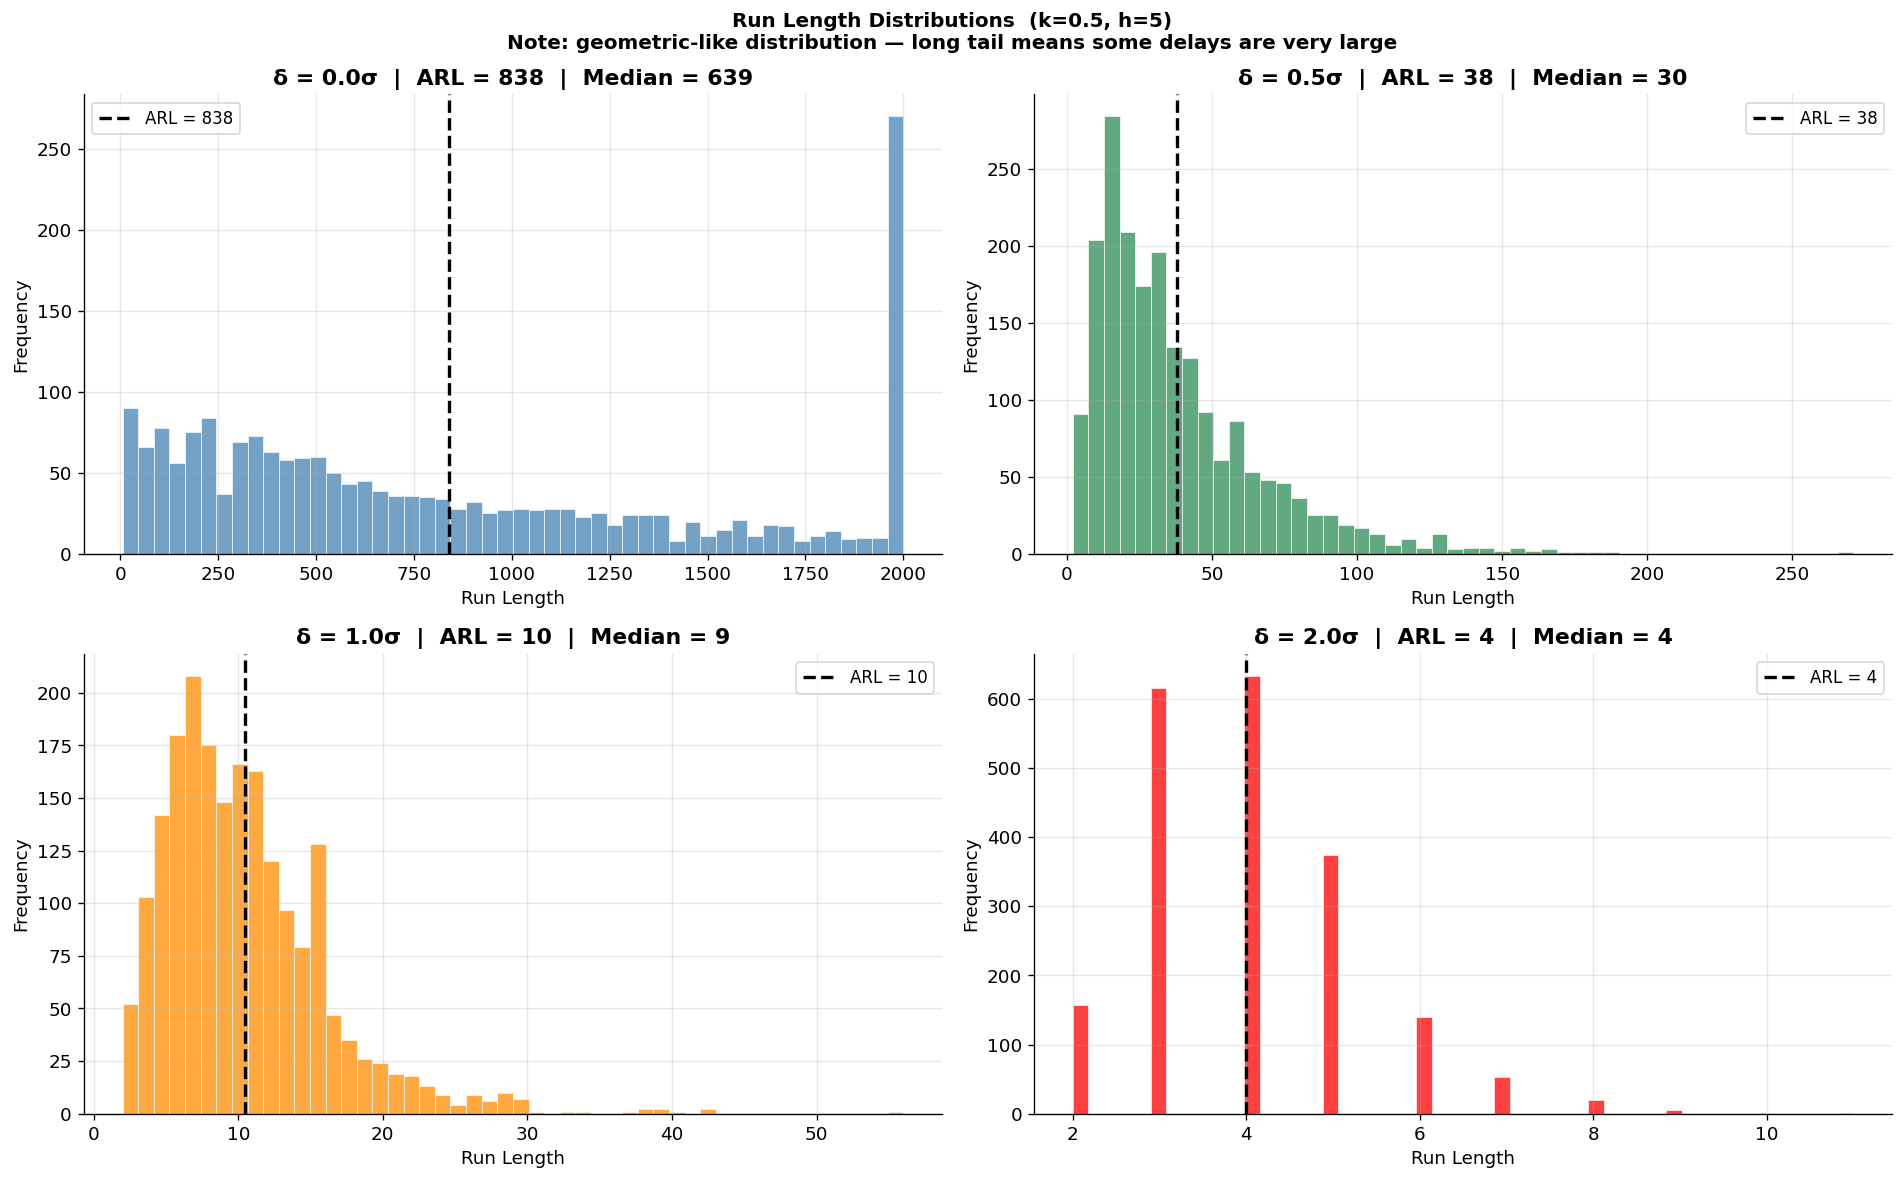

In [17]:

# ── 6.5 Run length distribution — histograms at different shifts ──────────────
np.random.seed(1)
shifts = [0.0, 0.5, 1.0, 2.0]
colors = ['steelblue', 'seagreen', 'darkorange', 'red']

fig, axes = plt.subplots(2, 2, figsize=(16, 10))
for ax, d, col in zip(axes.flat, shifts, colors):
    rls = np.array([mc_arl(k=0.5, h=5.0, delta=d, n_sim=1)[0] for _ in range(2000)])
    ax.hist(rls, bins=50, color=col, alpha=0.75, edgecolor='white', linewidth=0.5)
    ax.axvline(rls.mean(), color='k', linestyle='--', linewidth=2,
               label=f'ARL = {rls.mean():.0f}')
    ax.set_xlabel('Run Length')
    ax.set_ylabel('Frequency')
    ax.set_title(f'δ = {d}σ  |  ARL = {rls.mean():.0f}  |  Median = {np.median(rls):.0f}',
                 fontweight='bold')
    ax.legend(fontsize=10)

plt.suptitle('Run Length Distributions  (k=0.5, h=5)\n'
             'Note: geometric-like distribution — long tail means some delays are very large',
             fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

---

# Part VII — Multiple Change Points: Binary Segmentation

## 7.1 Motivation

Our data has **three** volatility regimes — two change points. The standard CUSUM fires a signal at the *first* change point then resets. **Binary Segmentation (BS)** is a recursive divide-and-conquer algorithm that finds all change points:

1. Apply CUSUM (or any statistic) to the full series → find the strongest change point $\hat\tau$
2. Split the series at $\hat\tau$ → recurse on each half
3. Stop when no more significant change points are found

## 7.2 The CUSUM Statistic for Binary Segmentation

Rather than the running maximum-of-zero recursion, we use the **CUSUM test statistic**:

$$S_n = \max_{1 \le t \le n} \left| \sum_{i=1}^{t} (x_i - \bar{x}_n) \right|$$

The change-point estimate is $\hat\tau = \text{argmax}_t |\ldots|$, and the test is significant if $S_n > \lambda \sqrt{n}$ (where $\lambda$ is a critical value chosen by the desired ARL).

## 7.3 Log-Likelihood Ratio for Variance Changes

For detecting **variance** changes (rather than mean changes) we use the likelihood-ratio statistic:

$$\text{LR}(t) = -\frac{n}{2}\ln\hat\sigma^2 + \frac{t}{2}\ln\hat\sigma_L^2(t) + \frac{n-t}{2}\ln\hat\sigma_R^2(t)$$

where $\hat\sigma_L^2(t)$ and $\hat\sigma_R^2(t)$ are the sample variances of the left and right segments. The maximum over $t$ gives the estimated change point.

### 7.4 Test Statistics for Change-Point Detection

Two offline test statistics:
- **CUSUM statistic** — $\max_\tau |S_\tau|$ where $S_\tau = \sum_{i=1}^{\tau}(x_i - \bar x)$; detects a **mean** change point
- **Likelihood-ratio statistic** — compares the variance on each side of a candidate split $\tau$; detects a **variance** change point

These are wrapped in a `binary_segmentation` function that recursively splits the series until no statistically significant change point remains.

In [18]:

# ── 7.4 CUSUM statistic (mean-change) and LR statistic (variance-change) ───────

def cusum_stat(x):
    """Offline CUSUM test statistic and estimated change point for mean shift."""
    x   = np.asarray(x, float)
    n   = len(x)
    xbar = x.mean()
    cs  = np.cumsum(x - xbar)
    idx = np.argmax(np.abs(cs))
    return np.abs(cs[idx]), idx

def lr_var_stat(x):
    """Log-likelihood ratio statistic for a single variance change point."""
    x   = np.asarray(x, float)
    n   = len(x)
    sig2_full = np.var(x, ddof=0) + 1e-12
    lr  = np.full(n, -np.inf)
    for t in range(2, n - 2):
        s2L = np.var(x[:t],  ddof=0) + 1e-12
        s2R = np.var(x[t:],  ddof=0) + 1e-12
        lr[t] = (- (n/2)*np.log(sig2_full)
                 + (t/2)*np.log(s2L)
                 + ((n-t)/2)*np.log(s2R))
    best = np.argmax(lr)
    return lr[best], best


def binary_segmentation(x, min_seg=30, threshold_cusum=None, threshold_lr=None,
                         mode='variance', depth=0, max_depth=5):
    """
    Recursive Binary Segmentation.
    mode='mean'     : uses CUSUM statistic
    mode='variance' : uses LR variance statistic
    Returns sorted list of estimated change-point indices (absolute).
    """
    x   = np.asarray(x, float)
    n   = len(x)
    if n < 2 * min_seg or depth >= max_depth:
        return []

    if mode == 'mean':
        stat, cp = cusum_stat(x)
        threshold = threshold_cusum if threshold_cusum else 1.36 * np.sqrt(n)  # 5% critical value
        significant = stat > threshold
    else:
        stat, cp = lr_var_stat(x)
        # Critical value via permutation would be ideal; we use a fixed threshold of 4.0
        threshold = threshold_lr if threshold_lr else 4.0
        significant = stat > threshold

    if not significant:
        return []

    left  = binary_segmentation(x[:cp],  min_seg, threshold_cusum, threshold_lr,
                                 mode, depth+1, max_depth)
    right = binary_segmentation(x[cp:],  min_seg, threshold_cusum, threshold_lr,
                                 mode, depth+1, max_depth)
    right = [r + cp for r in right]      # shift right-segment indices back
    return sorted(left + [cp] + right)

print('Binary segmentation functions defined.')

Binary segmentation functions defined.


### 7.5 Binary Segmentation on Simulated Data

We apply both the mean-based CUSUM and variance-based LR segmentation to our three-regime data. The true change points are at days 400 and 800. The visualisation shows detected change points (dashed lines) overlaid on returns, squared returns, and a CUSUM statistic heatmap across the full series.

True change points     : [400, 800]
BS (mean-based CUSUM)  : []
BS (variance LR)       : []


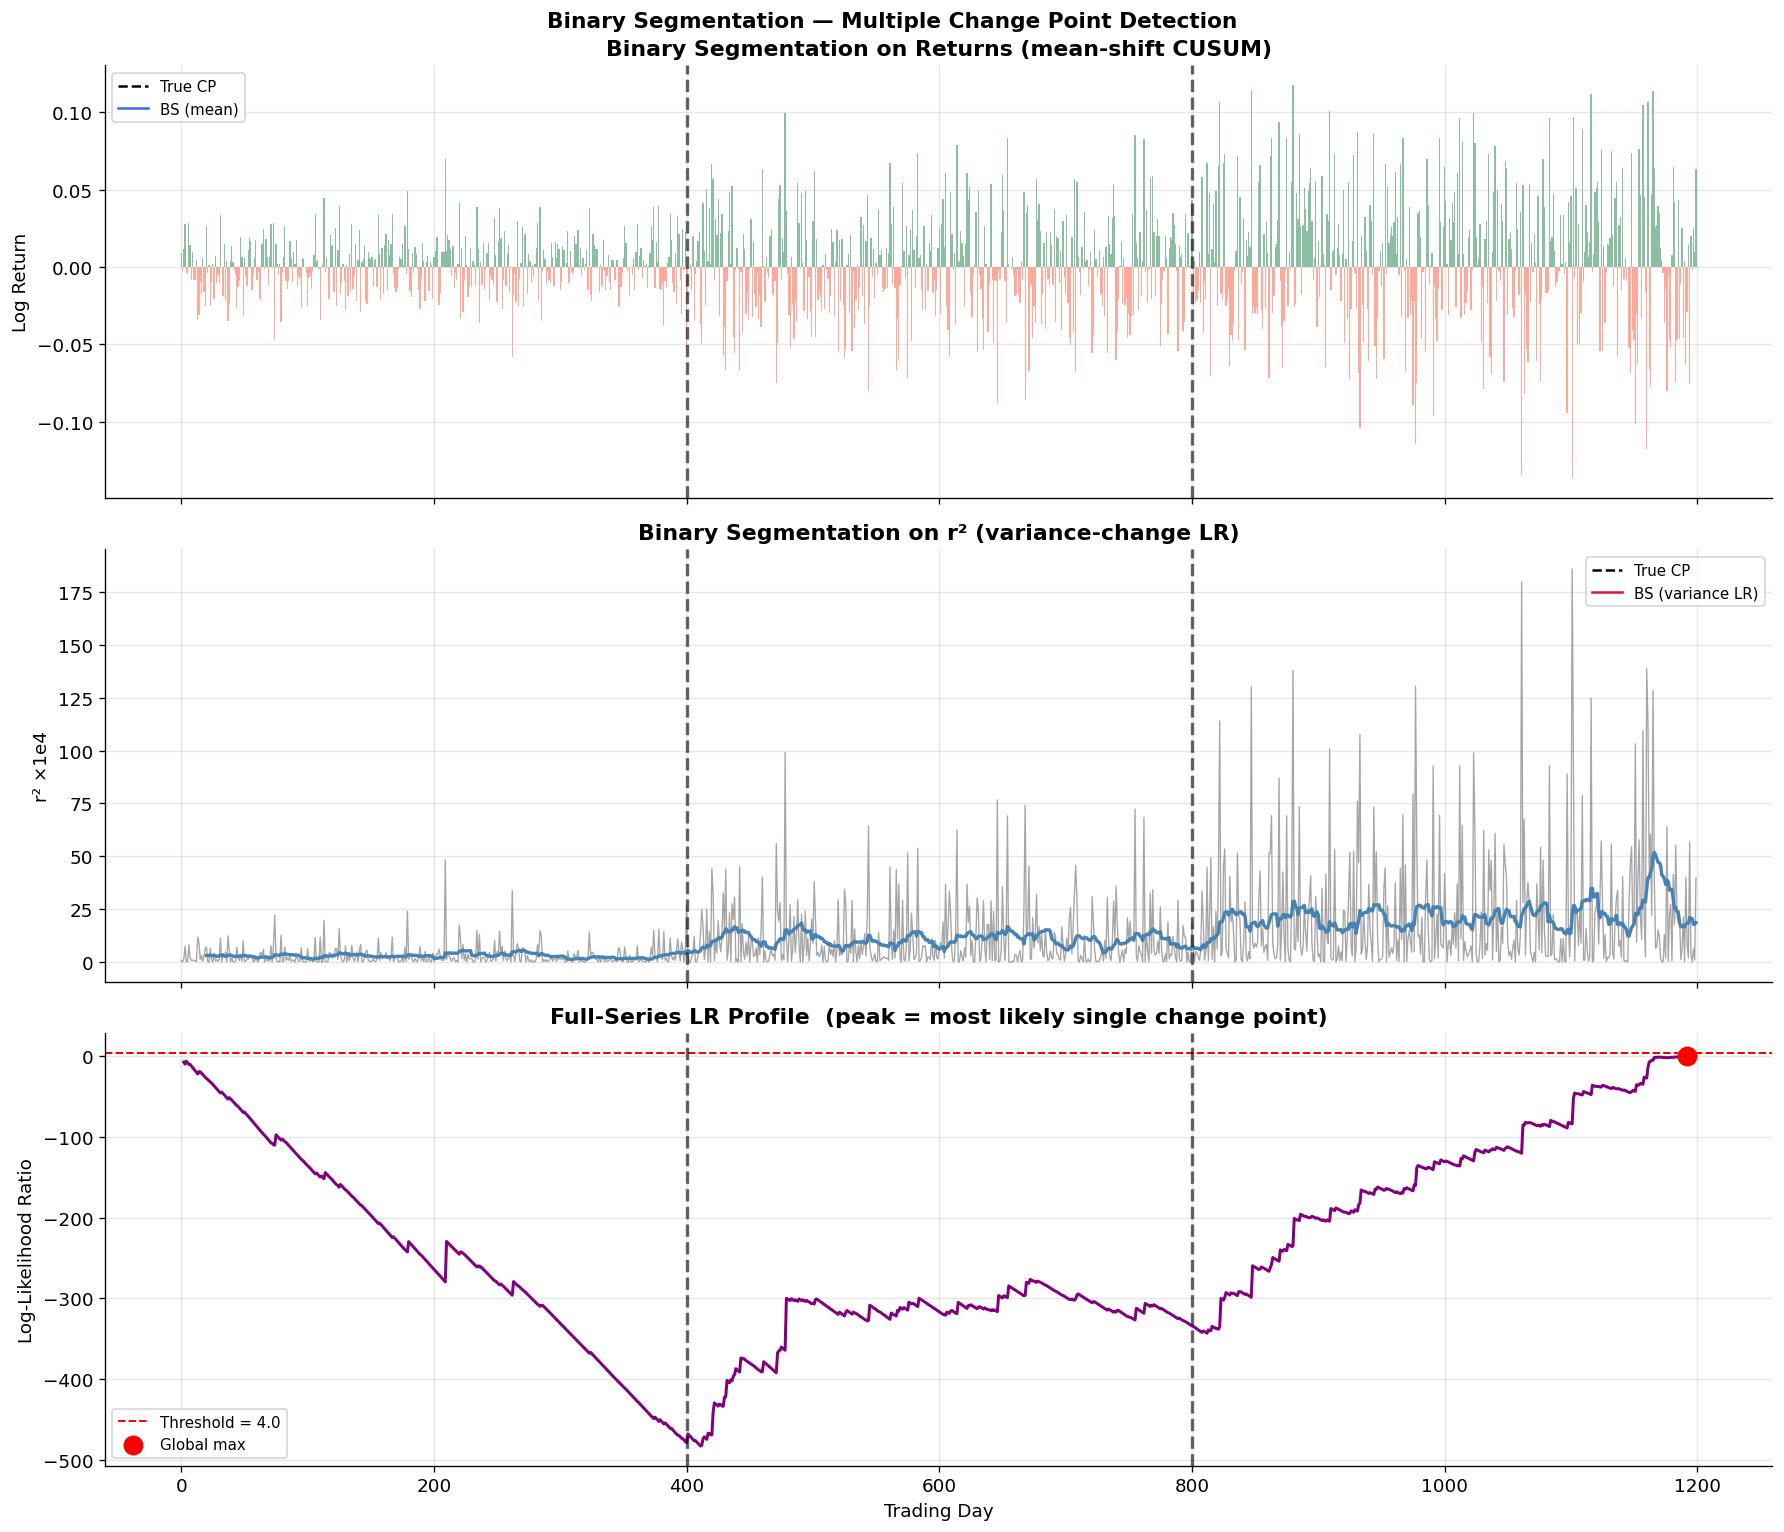


Detection error (days from true change point):
  BS mean: [] days off
  BS variance: [] days off


In [19]:

# ── 7.5 Apply binary segmentation to our simulated data ──────────────────────
# Use squared returns as the series (proxy for variance)
sq_rets_bs = log_rets**2

cp_mean = binary_segmentation(log_rets, min_seg=40, mode='mean')
cp_var  = binary_segmentation(sq_rets_bs, min_seg=40, mode='variance')

print(f'True change points     : {chg_pts}')
print(f'BS (mean-based CUSUM)  : {cp_mean}')
print(f'BS (variance LR)       : {cp_var}')

# ── Visualise ─────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(3, 1, figsize=(15, 13), sharex=True)

# Panel 1: returns + mean-based detections
ax = axes[0]
ax.bar(t, log_rets, color=np.where(log_rets >= 0, 'seagreen', 'tomato'), alpha=0.55, width=1)
for cp in chg_pts:
    ax.axvline(cp, color='black', linestyle='--', linewidth=2, alpha=0.6, label='True CP')
for cp in cp_mean:
    ax.axvline(cp, color='royalblue', linestyle='-', linewidth=2, alpha=0.8, label='BS detected')
handles = [plt.Line2D([0],[0], color='black', linestyle='--', label='True CP'),
           plt.Line2D([0],[0], color='royalblue', linestyle='-', label='BS (mean)')]
ax.legend(handles=handles, fontsize=9)
ax.set_title('Binary Segmentation on Returns (mean-shift CUSUM)', fontweight='bold')
ax.set_ylabel('Log Return')

# Panel 2: squared returns + variance-based detections
ax2 = axes[1]
ax2.plot(t, sq_rets_bs * 1e4, color='gray', linewidth=0.8, alpha=0.7)
roll_var = pd.Series(sq_rets_bs).rolling(21).mean() * 1e4
ax2.plot(t, roll_var, color='steelblue', linewidth=2, label='Rolling mean(r²) ×1e4')
for cp in chg_pts:
    ax2.axvline(cp, color='black', linestyle='--', linewidth=2, alpha=0.6)
for cp in cp_var:
    ax2.axvline(cp, color='crimson', linestyle='-', linewidth=2, alpha=0.8)
handles2 = [plt.Line2D([0],[0], color='black', linestyle='--', label='True CP'),
            plt.Line2D([0],[0], color='crimson', linestyle='-', label='BS (variance LR)')]
ax2.legend(handles=handles2, fontsize=9)
ax2.set_title('Binary Segmentation on r² (variance-change LR)', fontweight='bold')
ax2.set_ylabel('r² ×1e4')

# Panel 3: LR profile across the full series
lr_profile = np.full(n_days, np.nan)
for i in range(2, n_days - 2):
    s2L = np.var(sq_rets_bs[:i], ddof=0) + 1e-12
    s2R = np.var(sq_rets_bs[i:], ddof=0) + 1e-12
    s2F = np.var(sq_rets_bs, ddof=0) + 1e-12
    lr_profile[i] = (-(n_days/2)*np.log(s2F)
                     + (i/2)*np.log(s2L)
                     + ((n_days-i)/2)*np.log(s2R))

ax3 = axes[2]
ax3.plot(t, lr_profile, color='purple', linewidth=1.8)
ax3.axhline(4.0, color='red', linestyle='--', linewidth=1.2, label='Threshold = 4.0')
for cp in chg_pts:
    ax3.axvline(cp, color='black', linestyle='--', linewidth=2, alpha=0.6)
ax3.scatter(np.argmax(np.nan_to_num(lr_profile, nan=-np.inf)),
            np.nanmax(lr_profile), color='red', s=120, zorder=6, label='Global max')
ax3.set_title('Full-Series LR Profile  (peak = most likely single change point)', fontweight='bold')
ax3.set_ylabel('Log-Likelihood Ratio')
ax3.set_xlabel('Trading Day')
ax3.legend(fontsize=9)

plt.suptitle('Binary Segmentation — Multiple Change Point Detection', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

# Error analysis
print('\nDetection error (days from true change point):')
for name, cps in [('BS mean', cp_mean), ('BS variance', cp_var)]:
    errs = []
    for tcp in chg_pts:
        if cps:
            nearest = min(cps, key=lambda c: abs(c - tcp))
            errs.append(abs(nearest - tcp))
    print(f'  {name}: {errs} days off')

### 7.6 Interactive 3D — Change-Point Detection Strength

For each candidate split point $\tau$ and window size, we compute the offline CUSUM statistic. The resulting surface peaks sharply at the true change points, showing where the data "wants" to split most strongly.

In [20]:

# ── 7.6 Plotly 3D: Change-point detection strength across the series ──────────
# For each candidate split point τ, compute CUSUM statistic on the sub-series
# Shows where the data "wants" to split most strongly

n_bs = len(log_rets)
sq_rets_full = log_rets**2

# Scan: for window sizes from 50 to full series, find CUSUM stat at each τ
win_sizes = np.arange(50, min(n_bs, 600), 25)
stat_surface = np.zeros((len(win_sizes), n_bs))

for i, ws in enumerate(win_sizes):
    for start in range(0, n_bs - ws, 20):
        segment = sq_rets_full[start:start + ws]
        stat_val, cp_idx = cusum_stat(segment)
        global_cp = start + cp_idx
        if global_cp < n_bs:
            stat_surface[i, global_cp] = max(stat_surface[i, global_cp], stat_val)

# Smooth for visualisation
from scipy.ndimage import gaussian_filter
stat_smooth = gaussian_filter(stat_surface, sigma=[1, 3])

T_bs, W_bs = np.meshgrid(np.arange(n_bs), win_sizes)

fig = go.Figure(go.Surface(
    x=T_bs, y=W_bs, z=stat_smooth,
    colorscale='Hot',
    colorbar=dict(title='CUSUM Stat', len=0.65),
    hovertemplate='Day=%{x}<br>Window=%{y}<br>Stat=%{z:.2f}<extra></extra>',
    opacity=0.9,
))
for cp in chg_pts:
    fig.add_trace(go.Scatter3d(
        x=[cp]*len(win_sizes), y=win_sizes,
        z=stat_smooth[:, cp],
        mode='lines', line=dict(color='cyan', width=5),
        name=f'True CP {cp}',
    ))
fig.update_layout(
    title='3D: Change-Point Detection Strength Surface<br>'
          '<sup>Hot spots = where the CUSUM statistic peaks across different window sizes. '
          'True change points should appear as ridges</sup>',
    scene=dict(
        xaxis_title='Trading Day (candidate τ)',
        yaxis_title='Scan Window Size',
        zaxis_title='CUSUM Statistic',
        camera=dict(eye=dict(x=1.5, y=-1.6, z=1.0)),
    ),
    height=650, width=1050, margin=dict(l=0, r=0, t=80, b=0),
)
fig.show()


---

# Part VIII — CUSUM vs EWMA vs Shewhart

## 8.1 Three Philosophies

| Chart | Core idea | Memory | Optimal for |
|-------|-----------|--------|------------|
| **Shewhart** | Flag if current obs > $\mu_0 \pm L\sigma$ | None (memoryless) | Large sudden shifts ≥ 3σ |
| **EWMA** | Exponentially weighted moving average; flag if $Z_t$ crosses limits | Exponential decay | Medium shifts 1–2σ |
| **CUSUM** | Accumulate evidence since last reset | Since last reset | Small persistent shifts < 1σ |

The **combined Shewhart–CUSUM** chart uses both simultaneously: Shewhart catches the large one-off spikes, CUSUM catches the gradual drift.

## 8.2 EWMA Control Chart

$$Z_t = \lambda\, x_t + (1-\lambda)\, Z_{t-1}$$

Control limits: $\mu_0 \pm L \sigma \sqrt{\frac{\lambda}{2-\lambda}}$  (steady-state)

A signal fires when $Z_t$ falls outside the limits.

## 8.3 Shewhart 3-Sigma Chart

Signal if $x_t > \mu_0 + 3\sigma$ or $x_t < \mu_0 - 3\sigma$.

### 8.4 Side-by-Side Implementation

We apply all three control charts to the same standardised returns:
- **CUSUM** ($k = 0.5$, $h = 5$) — accumulates deviations since last reset
- **EWMA** ($\lambda = 0.2$, $L = 3$) — exponentially weighted moving average with fixed control limits
- **Shewhart** ($L = 3\sigma$) — flags any individual observation beyond 3 standard deviations

The plot compares their signal timing relative to the true regime boundaries.

Signals: CUSUM=60, EWMA=194, Shewhart=171


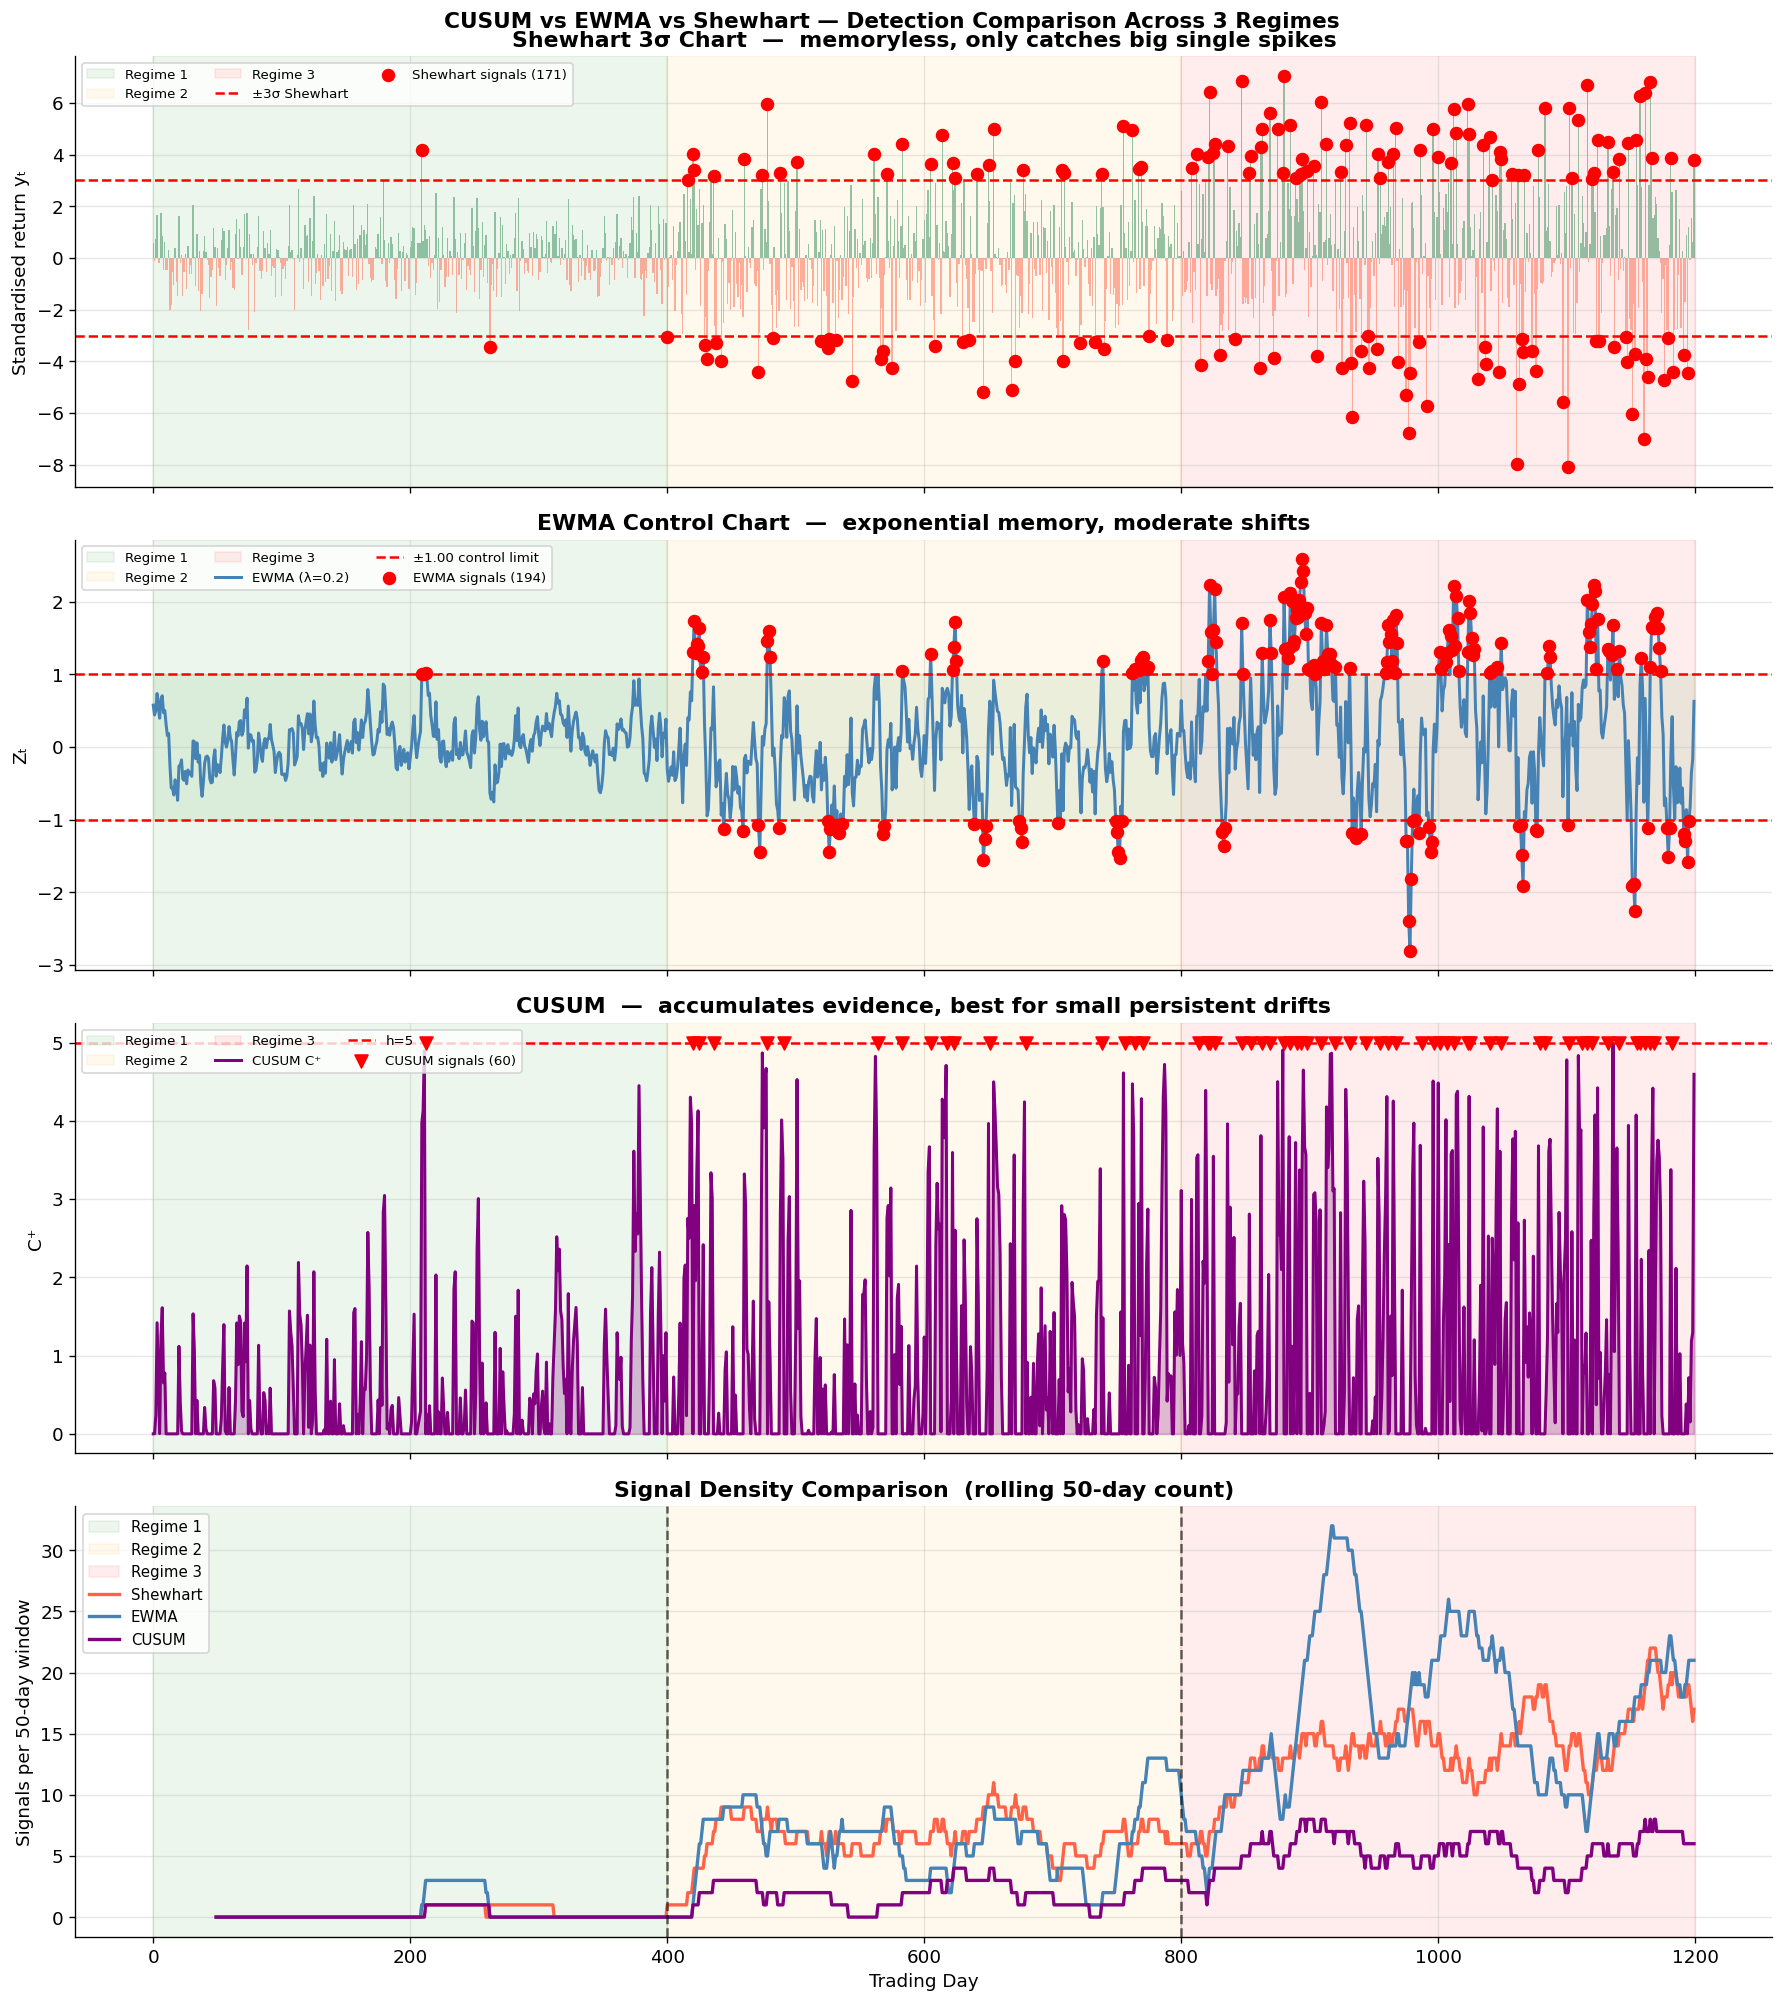

In [21]:

# ── 8.4 Implement all three on standardised returns ───────────────────────────
y_std = (log_rets - mu0) / sigma0   # standardised

# CUSUM (k=0.5, h=5)
Cu_cmp, sigs_cusum = cusum_one_sided(log_rets, k=0.5, h=5.0, mu0=mu0, sigma=sigma0)

# EWMA control chart (lambda=0.2, L=3)
lam_ewma = 0.20
L_ewma   = 3.0
cl_ewma  = L_ewma * np.sqrt(lam_ewma / (2 - lam_ewma))   # control limit in σ units
Z_ewma   = np.zeros(n_days)
Z_ewma[0] = y_std[0]
for i in range(1, n_days):
    Z_ewma[i] = lam_ewma * y_std[i] + (1 - lam_ewma) * Z_ewma[i-1]
sigs_ewma = np.where(np.abs(Z_ewma) > cl_ewma)[0]

# Shewhart 3-sigma (on standardised series)
shewhart_limit = 3.0
sigs_shewhart  = np.where(np.abs(y_std) > shewhart_limit)[0]

print(f'Signals: CUSUM={len(sigs_cusum)}, EWMA={len(sigs_ewma)}, Shewhart={len(sigs_shewhart)}')

# ── Side-by-side visualisation ────────────────────────────────────────────────
fig, axes = plt.subplots(4, 1, figsize=(15, 17), sharex=True)

# Common background shading by regime
for ax in axes:
    ax.axvspan(0,          chg_pts[0], alpha=0.07, color='green',  label='Regime 1')
    ax.axvspan(chg_pts[0], chg_pts[1], alpha=0.07, color='orange', label='Regime 2')
    ax.axvspan(chg_pts[1], n_days,     alpha=0.07, color='red',    label='Regime 3')

# Panel 0: standardised returns + Shewhart signals
ax = axes[0]
ax.bar(t, y_std, color=np.where(y_std >= 0, 'seagreen', 'tomato'), alpha=0.5, width=1)
ax.axhline( shewhart_limit, color='red', linestyle='--', linewidth=1.5, label='±3σ Shewhart')
ax.axhline(-shewhart_limit, color='red', linestyle='--', linewidth=1.5)
if len(sigs_shewhart):
    ax.scatter(sigs_shewhart, y_std[sigs_shewhart], color='red', s=50, zorder=6,
               label=f'Shewhart signals ({len(sigs_shewhart)})')
ax.set_ylabel('Standardised return yₜ')
ax.set_title('Shewhart 3σ Chart  —  memoryless, only catches big single spikes', fontweight='bold')
ax.legend(fontsize=8, ncol=3)

# Panel 1: EWMA chart
ax2 = axes[1]
ax2.plot(t, Z_ewma, color='steelblue', linewidth=1.8, label=f'EWMA (λ={lam_ewma})')
ax2.axhline( cl_ewma, color='red', linestyle='--', linewidth=1.5, label=f'±{cl_ewma:.2f} control limit')
ax2.axhline(-cl_ewma, color='red', linestyle='--', linewidth=1.5)
ax2.fill_between(t, -cl_ewma, cl_ewma, alpha=0.08, color='green')
if len(sigs_ewma):
    ax2.scatter(sigs_ewma, Z_ewma[sigs_ewma], color='red', s=50, zorder=6,
                label=f'EWMA signals ({len(sigs_ewma)})')
ax2.set_ylabel('Zₜ')
ax2.set_title('EWMA Control Chart  —  exponential memory, moderate shifts', fontweight='bold')
ax2.legend(fontsize=8, ncol=3)

# Panel 2: CUSUM
ax3 = axes[2]
ax3.fill_between(t, Cu_cmp, alpha=0.25, color='purple')
ax3.plot(t, Cu_cmp, color='purple', linewidth=1.8, label='CUSUM C⁺')
ax3.axhline(5.0, color='red', linestyle='--', linewidth=1.5, label='h=5')
if len(sigs_cusum):
    ax3.scatter(sigs_cusum, np.full(len(sigs_cusum), 5.0), color='red', s=60,
                marker='v', zorder=6, label=f'CUSUM signals ({len(sigs_cusum)})')
ax3.set_ylabel('C⁺')
ax3.set_title('CUSUM  —  accumulates evidence, best for small persistent drifts', fontweight='bold')
ax3.legend(fontsize=8, ncol=3)

# Panel 3: Signal density comparison (rolling count of signals per 50-day window)
ax4 = axes[3]
window_sig = 50
def sig_density(sigs, n, w):
    d = np.zeros(n)
    for s in sigs: d[s] = 1
    return pd.Series(d).rolling(w).sum().values

ax4.plot(t, sig_density(sigs_shewhart, n_days, window_sig), color='tomato',
         linewidth=2, label='Shewhart')
ax4.plot(t, sig_density(sigs_ewma, n_days, window_sig), color='steelblue',
         linewidth=2, label='EWMA')
ax4.plot(t, sig_density(sigs_cusum, n_days, window_sig), color='purple',
         linewidth=2, label='CUSUM')
for cp in chg_pts:
    ax4.axvline(cp, color='k', linestyle='--', alpha=0.6)
ax4.set_ylabel('Signals per 50-day window')
ax4.set_xlabel('Trading Day')
ax4.set_title('Signal Density Comparison  (rolling 50-day count)', fontweight='bold')
ax4.legend(fontsize=9)

plt.suptitle('CUSUM vs EWMA vs Shewhart — Detection Comparison Across 3 Regimes',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

### 8.5 ARL Comparison Across Methods

We sweep the shift size $\delta$ from 0 to 3$\sigma$ and estimate ARL for each method via Monte Carlo. CUSUM dominates for small persistent shifts ($\delta < 1\sigma$), EWMA is competitive in the mid-range, and Shewhart only excels for large sudden shifts ($\delta > 2\sigma$).

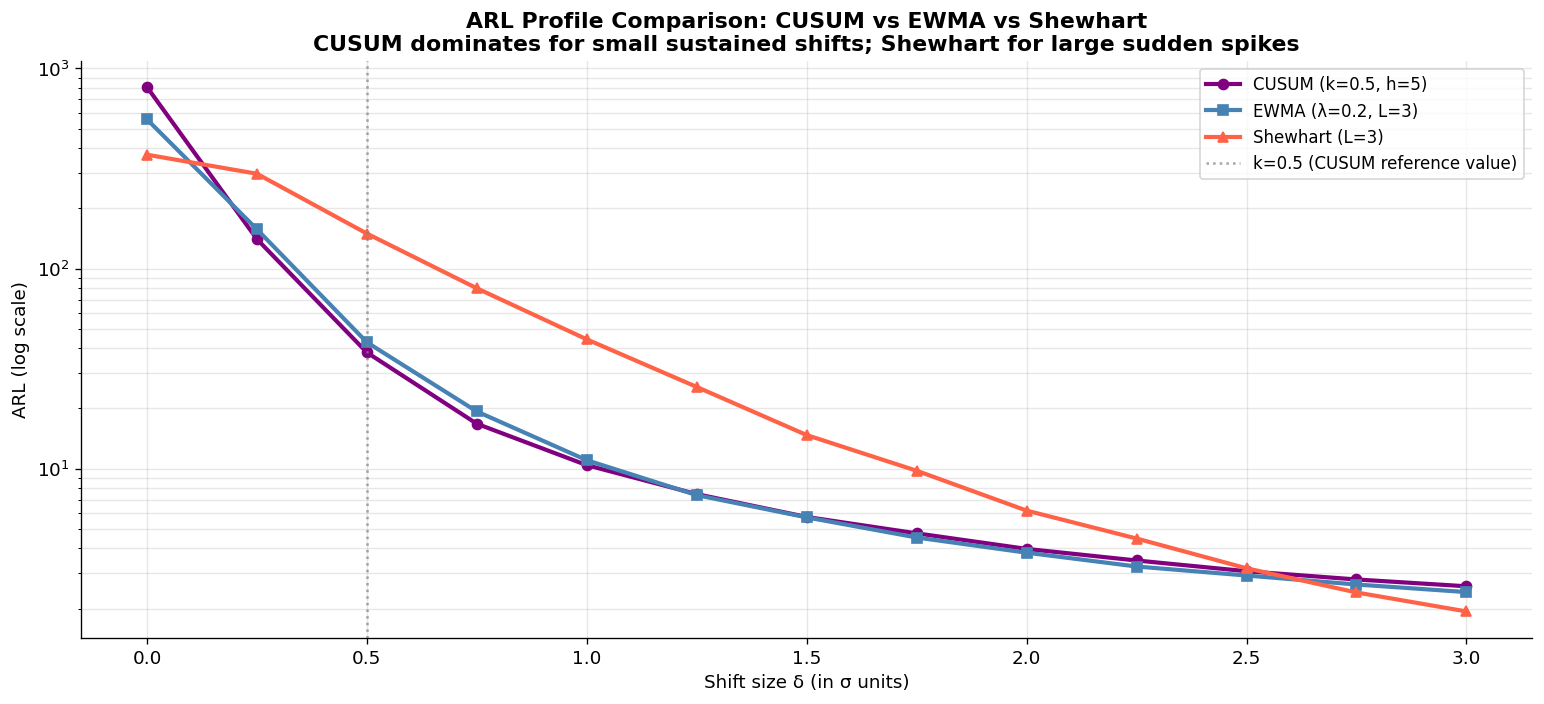


ARL comparison at key shift sizes:
    δ |    CUSUM |     EWMA |   Shewhart
--------------------------------------
 0.00 |      807 |      557 |        370  ← Shewhart
 0.25 |      140 |      157 |        298  ← CUSUM
 0.50 |       38 |       43 |        150  ← CUSUM
 0.75 |       17 |       19 |         80  ← CUSUM
 1.00 |       10 |       11 |         44  ← CUSUM
 1.25 |        7 |        7 |         26  ← EWMA
 1.50 |        6 |        6 |         15  ← EWMA
 1.75 |        5 |        5 |         10  ← EWMA
 2.00 |        4 |        4 |          6  ← EWMA
 2.25 |        3 |        3 |          4  ← EWMA
 2.50 |        3 |        3 |          3  ← EWMA
 2.75 |        3 |        3 |          2  ← Shewhart
 3.00 |        3 |        2 |          2  ← Shewhart


In [22]:

# ── 8.5 ARL comparison across all three methods ────────────────────────────────
np.random.seed(2)
delta_sweep = np.arange(0.0, 3.1, 0.25)
n_sim_cmp   = 1500

def arl_shewhart(delta, L=3.0, n_sim=1500, max_run=2000):
    rls = []
    for _ in range(n_sim):
        for j in range(1, max_run+1):
            if abs(np.random.normal(delta, 1.0)) > L:
                rls.append(j); break
        else:
            rls.append(max_run)
    return np.mean(rls)

def arl_ewma_chart(delta, lam=0.2, L=3.0, n_sim=1500, max_run=2000):
    cl = L * np.sqrt(lam / (2 - lam))
    rls = []
    for _ in range(n_sim):
        Z = 0.0
        for j in range(1, max_run+1):
            Z = lam * np.random.normal(delta, 1.0) + (1-lam)*Z
            if abs(Z) > cl:
                rls.append(j); break
        else:
            rls.append(max_run)
    return np.mean(rls)

arl_cusum_vals    = []
arl_ewma_vals     = []
arl_shewhart_vals = []

for d in delta_sweep:
    arl_cusum_vals.append(mc_arl(k=0.5, h=5.0, delta=d, n_sim=n_sim_cmp)[0])
    arl_ewma_vals.append(arl_ewma_chart(d, n_sim=n_sim_cmp))
    arl_shewhart_vals.append(arl_shewhart(d, n_sim=n_sim_cmp))

fig, ax = plt.subplots(figsize=(13, 6))
ax.semilogy(delta_sweep, arl_cusum_vals,    'purple',    linewidth=2.5, marker='o', label='CUSUM (k=0.5, h=5)')
ax.semilogy(delta_sweep, arl_ewma_vals,     'steelblue', linewidth=2.5, marker='s', label='EWMA (λ=0.2, L=3)')
ax.semilogy(delta_sweep, arl_shewhart_vals, 'tomato',    linewidth=2.5, marker='^', label='Shewhart (L=3)')
ax.axvline(0.5, color='gray', linestyle=':', alpha=0.7, label='k=0.5 (CUSUM reference value)')
ax.set_xlabel('Shift size δ (in σ units)')
ax.set_ylabel('ARL (log scale)')
ax.set_title('ARL Profile Comparison: CUSUM vs EWMA vs Shewhart\n'
             'CUSUM dominates for small sustained shifts; Shewhart for large sudden spikes',
             fontweight='bold')
ax.legend(fontsize=10)
ax.grid(True, which='both', alpha=0.3)
plt.tight_layout()
plt.show()

print('\nARL comparison at key shift sizes:')
print(f'{"δ":>5} | {"CUSUM":>8} | {"EWMA":>8} | {"Shewhart":>10}')
print('-' * 38)
for d, ac, ae, ash in zip(delta_sweep, arl_cusum_vals, arl_ewma_vals, arl_shewhart_vals):
    winner = min([('CUSUM',ac),('EWMA',ae),('Shewhart',ash)], key=lambda x:x[1])[0]
    print(f'{d:5.2f} | {ac:8.0f} | {ae:8.0f} | {ash:10.0f}  ← {winner}')

### 8.6 Interactive 3D — Detection Power Surfaces

Three Plotly surfaces showing ARL₁ as a function of (method parameter, shift $\delta$) for CUSUM, EWMA, and Shewhart. The surface shape reveals each method's sensitivity profile and how its tuning parameter trades off speed against false alarms.

In [23]:

# ── 8.6 Plotly 3D: Detection power — ARL₁ surface for all three methods ──────
# Compare CUSUM, EWMA, Shewhart across shift sizes and their key parameter

# Already have arl_cusum, arl_ewma, arl_shewhart from Cell 25 sweep
# Re-sweep over 2D: shift δ and method parameter

param_ranges = {
    'CUSUM (k)': np.arange(0.2, 1.3, 0.2),
    'EWMA (λ)': np.arange(0.05, 0.45, 0.08),
    'Shewhart (L)': np.arange(2.0, 4.1, 0.4),
}
delta_rng = np.arange(0.0, 3.1, 0.5)

fig = make_subplots(
    rows=1, cols=3,
    specs=[[{'type': 'surface'}, {'type': 'surface'}, {'type': 'surface'}]],
    subplot_titles=['CUSUM: ARL₁(k, δ)', 'EWMA: ARL₁(λ, δ)', 'Shewhart: ARL₁(L, δ)'],
)

np.random.seed(10)
for col_idx, (method, p_range) in enumerate(param_ranges.items()):
    P_g, D_g = np.meshgrid(p_range, delta_rng, indexing='ij')
    arl_grid = np.zeros_like(P_g)

    for i, pp in enumerate(p_range):
        for j, dd in enumerate(delta_rng):
            if 'CUSUM' in method:
                arl_grid[i, j], _ = mc_arl(k=pp, h=5.0, delta=dd, n_sim=400)
            elif 'EWMA' in method:
                arl_grid[i, j] = arl_ewma_chart(dd, lam=pp, n_sim=400)
            else:
                arl_grid[i, j] = arl_shewhart(dd, L=pp, n_sim=400)

    colorscales = ['YlGnBu', 'YlOrRd', 'PuBuGn']
    fig.add_trace(
        go.Surface(x=P_g, y=D_g, z=np.log10(arl_grid.clip(1)),
                   colorscale=colorscales[col_idx], showscale=False,
                   hovertemplate=f'{method.split("(")[0]}=%{{x:.2f}}<br>'
                                 f'δ=%{{y:.1f}}σ<br>ARL₁=%{{customdata:.0f}}<extra></extra>',
                   customdata=arl_grid),
        row=1, col=col_idx + 1,
    )

fig.update_layout(
    title='3D: Detection Power — ARL₁ Surfaces for CUSUM, EWMA, and Shewhart<br>'
          '<sup>Lower = faster detection. CUSUM dominates for small persistent shifts (δ < 1σ)</sup>',
    height=550, width=1200, margin=dict(l=0, r=0, t=80, b=0),
)
# Set axis titles for each subplot
for i, (method, _) in enumerate(param_ranges.items()):
    param_name = method.split('(')[1].rstrip(')')
    fig.update_scenes(
        dict(xaxis_title=param_name, yaxis_title='Shift δ (σ)',
             zaxis_title='log₁₀(ARL₁)',
             camera=dict(eye=dict(x=1.6, y=-1.6, z=1.0))),
        row=1, col=i + 1,
    )
fig.show()


---

# Part IX — 3D Surfaces (Plotly)

## 9.1 ARL₀ Surface over (k, h)

The in-control ARL is a function of both $k$ and $h$. Visualising the surface helps choose the right parameter pair for a target ARL₀.

## 9.2 ARL₁ Surface over (h, δ)

For a fixed $k=0.5$, ARL₁ is a function of the decision threshold $h$ and the shift size $δ$. The surface reveals the exact speed-vs-sensitivity trade-off.

## 9.3 CUSUM Path Surface over (k, time)

Running the same data through many values of $k$ simultaneously shows how the accumulated statistic evolves differently, helping practitioners pick the best $k$ for their data.

### 9.4 ARL₀ Surface over $(k, h)$

Monte Carlo estimation of in-control ARL across a grid of $(k, h)$ values. The surface and companion contour plot help identify the $(k, h)$ pair that achieves a target ARL₀ (e.g., ARL₀ ≈ 500 for a roughly 0.2% daily false-alarm rate).

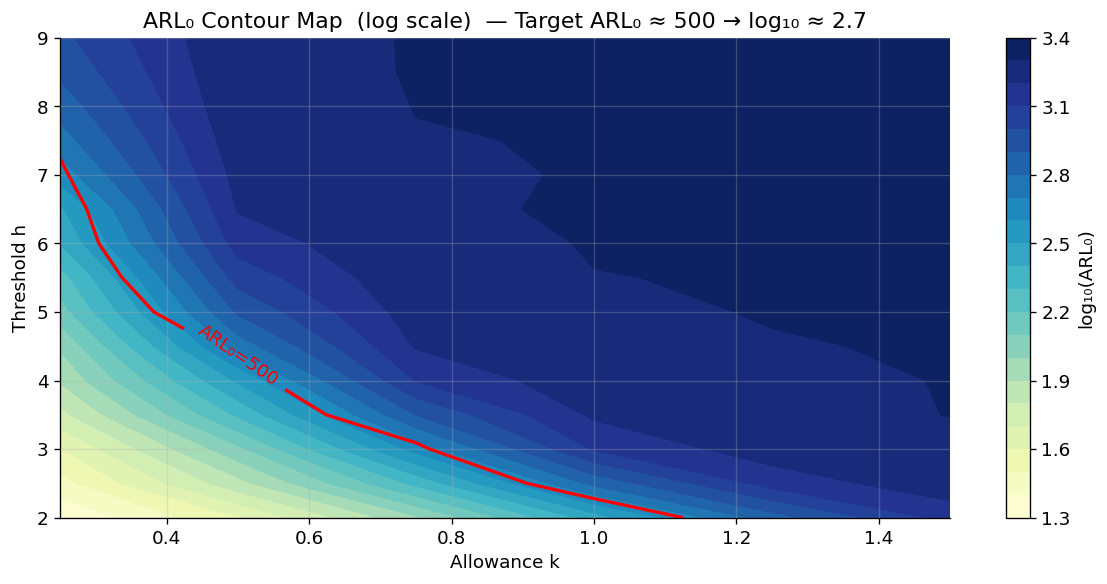

In [24]:

# ── 9.4 Plotly 3D: ARL₀ surface over (k, h) ──────────────────────────────────
np.random.seed(3)
k_range = np.arange(0.25, 1.51, 0.25)
h_range = np.arange(2.0,  9.1,  0.5)
K_grid, H_grid = np.meshgrid(k_range, h_range, indexing='ij')

arl0_surface = np.zeros_like(K_grid)
for i, kk in enumerate(k_range):
    for j, hh in enumerate(h_range):
        arl0_surface[i, j], _ = mc_arl(kk, hh, delta=0.0, n_sim=800)

# 2D companion: contour
fig2d, ax2d = plt.subplots(figsize=(10, 5))
cs = ax2d.contourf(K_grid, H_grid, np.log10(arl0_surface + 1), levels=20, cmap='YlGnBu')
plt.colorbar(cs, ax=ax2d, label='log₁₀(ARL₀)')
ax2d.set_xlabel('Allowance k'); ax2d.set_ylabel('Threshold h')
ax2d.set_title('ARL₀ Contour Map  (log scale)  — Target ARL₀ ≈ 500 → log₁₀ ≈ 2.7')
ct = ax2d.contour(K_grid, H_grid, arl0_surface, levels=[500], colors='red', linewidths=2)
ax2d.clabel(ct, fmt='ARL₀=500')
plt.tight_layout(); plt.show()

# 3D Plotly surface
fig3d = go.Figure(go.Surface(
    x=K_grid, y=H_grid, z=np.log10(arl0_surface + 1),
    colorscale='YlGnBu',
    colorbar=dict(title='log₁₀(ARL₀)', len=0.6),
    hovertemplate='k=%{x:.2f}<br>h=%{y:.1f}<br>ARL₀=%{customdata:.0f}<extra></extra>',
    customdata=arl0_surface,
))
fig3d.update_layout(
    title='3D: ARL₀ Surface over (k, h)<br>'
          '<sup>Red iso-line ≈ ARL₀=500 — standard design target</sup>',
    scene=dict(
        xaxis_title='Allowance k',
        yaxis_title='Threshold h',
        zaxis_title='log₁₀(ARL₀)',
        camera=dict(eye=dict(x=1.7, y=-1.7, z=1.0)),
    ),
    height=650, width=1050, margin=dict(l=0, r=0, t=70, b=0),
)
fig3d.show()

### 9.5 ARL₁ Surface over $(h, \delta)$ at Fixed $k = 0.5$

With the allowance fixed, this surface shows how detection speed depends jointly on the threshold $h$ and the true shift size $\delta$. The steep gradient along $\delta$ confirms CUSUM's rapid power gain once the shift exceeds the allowance.

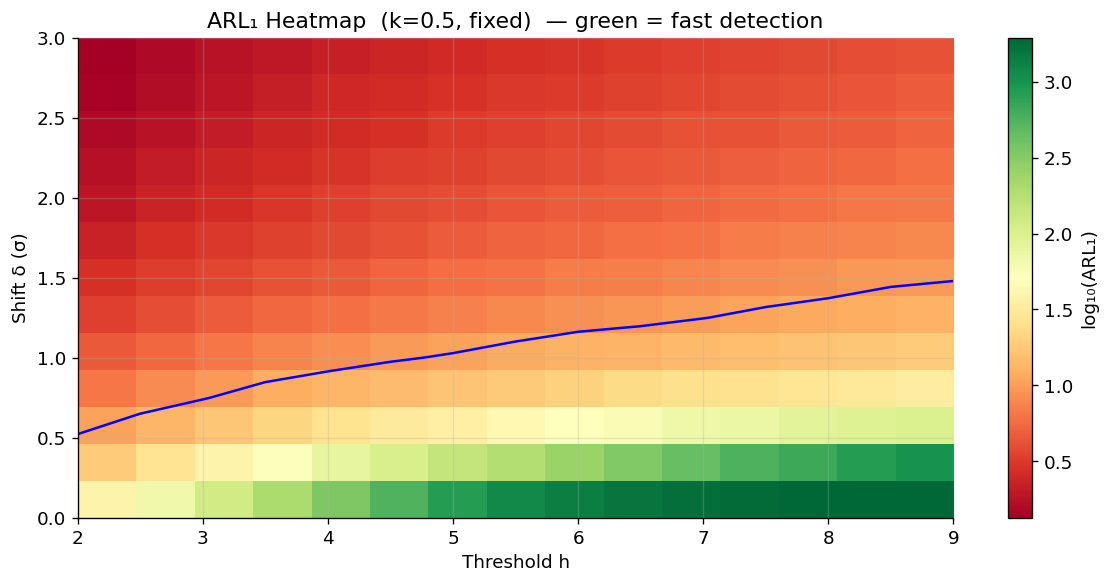

In [25]:

# ── 9.5 Plotly 3D: ARL₁ surface over (h, δ) at fixed k=0.5 ──────────────────
np.random.seed(4)
delta_range = np.arange(0.0, 3.1, 0.25)
h_range2    = np.arange(2.0, 9.1, 0.5)
D_grid, H2_grid = np.meshgrid(delta_range, h_range2, indexing='ij')

arl1_surface = np.zeros_like(D_grid)
for i, dd in enumerate(delta_range):
    for j, hh in enumerate(h_range2):
        arl1_surface[i, j], _ = mc_arl(k=0.5, h=hh, delta=dd, n_sim=800)

# Clip for log: replace very large values with max_run proxy
arl1_clipped = np.clip(arl1_surface, 1, 2000)

# 2D heatmap companion
fig2d, ax2d = plt.subplots(figsize=(10, 5))
im = ax2d.imshow(np.log10(arl1_clipped), aspect='auto', cmap='RdYlGn',
                 origin='lower',
                 extent=[h_range2[0], h_range2[-1], delta_range[0], delta_range[-1]])
plt.colorbar(im, ax=ax2d, label='log₁₀(ARL₁)')
ax2d.set_xlabel('Threshold h'); ax2d.set_ylabel('Shift δ (σ)')
ax2d.set_title('ARL₁ Heatmap  (k=0.5, fixed)  — green = fast detection')
ax2d.contour(h_range2, delta_range, np.log10(arl1_clipped),
             levels=[1.0], colors='blue', linewidths=1.5)   # ARL₁=10 iso-line
plt.tight_layout(); plt.show()

# 3D Plotly surface
fig3d = go.Figure(go.Surface(
    x=D_grid, y=H2_grid, z=np.log10(arl1_clipped),
    colorscale='RdYlGn',
    reversescale=True,
    colorbar=dict(title='log₁₀(ARL₁)', len=0.6),
    hovertemplate='δ=%{x:.2f}σ<br>h=%{y:.1f}<br>ARL₁=%{customdata:.0f}<extra></extra>',
    customdata=arl1_clipped,
))
fig3d.update_layout(
    title='3D: ARL₁ Surface over (δ, h)  —  k=0.5 fixed<br>'
          '<sup>Green = fast detection; Red = slow. '
          'Larger h → slower but fewer false alarms</sup>',
    scene=dict(
        xaxis_title='Shift size δ (σ units)',
        yaxis_title='Threshold h',
        zaxis_title='log₁₀(ARL₁)',
        camera=dict(eye=dict(x=1.6, y=-1.6, z=1.0)),
    ),
    height=650, width=1050, margin=dict(l=0, r=0, t=80, b=0),
)
fig3d.show()

### 9.6 CUSUM Path Surface over $(k, \text{time})$

CUSUM on squared returns run simultaneously across many $k$ values (no reset). The surface shows how the accumulated evidence builds over time for each allowance — lower $k$ accumulates faster but is more sensitive to noise.

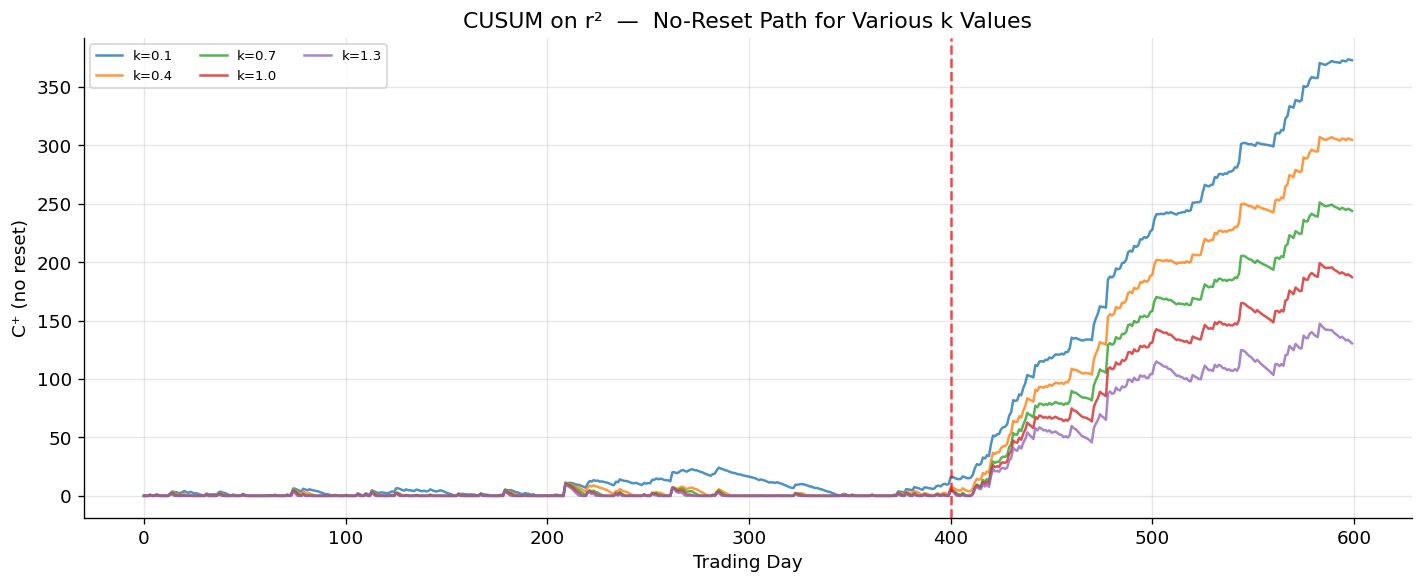

In [26]:

# ── 9.6 Plotly 3D: CUSUM path surface over (k, time) ─────────────────────────
# Run CUSUM on squared returns across many k values simultaneously
# Shows how the sensitivity to the vol shift changes with k
k_sweep = np.arange(0.1, 1.55, 0.1)
n_show  = 600   # show first 600 days (captures both change points)

C_surface = np.zeros((len(k_sweep), n_show))
for i, kk in enumerate(k_sweep):
    Cu, _ = cusum_one_sided(sq_rets[:n_show], k=kk, h=999,   # h=999 → never reset
                             mu0=sigma0_sq, sigma=np.sqrt(2)*sigma0_sq, reset=False)
    C_surface[i] = Cu

T_g, K_g = np.meshgrid(np.arange(n_show), k_sweep, indexing='ij')

# 2D companion: a few k curves
fig2d, ax2d = plt.subplots(figsize=(12, 5))
for kk, row in zip(k_sweep[::3], C_surface[::3]):
    ax2d.plot(np.arange(n_show), row, linewidth=1.5, alpha=0.8, label=f'k={kk:.1f}')
for cp in chg_pts:
    if cp < n_show:
        ax2d.axvline(cp, color='red', linestyle='--', alpha=0.7)
ax2d.set_xlabel('Trading Day'); ax2d.set_ylabel('C⁺ (no reset)')
ax2d.set_title('CUSUM on r²  —  No-Reset Path for Various k Values')
ax2d.legend(fontsize=8, ncol=3); plt.tight_layout(); plt.show()

# 3D Plotly
fig3d = go.Figure(go.Surface(
    x=T_g, y=K_g, z=C_surface.T,
    colorscale='Plasma',
    colorbar=dict(title='C⁺ value', len=0.6),
    hovertemplate='Day=%{x}<br>k=%{y:.2f}<br>C⁺=%{z:.2f}<extra></extra>',
))
# Mark the change points as vertical planes via scatter lines
for cp in chg_pts:
    if cp < n_show:
        fig3d.add_trace(go.Scatter3d(
            x=[cp]*len(k_sweep), y=k_sweep,
            z=C_surface[:, cp],
            mode='lines', line=dict(color='red', width=4),
            name=f'Change pt day {cp}', showlegend=True,
        ))
fig3d.update_layout(
    title='3D: CUSUM Path Surface on r²  —  Time × Allowance k<br>'
          '<sup>Red lines = true regime-change days. '
          'Small k (front) accumulates faster; large k (back) is more selective</sup>',
    scene=dict(
        xaxis_title='Trading Day',
        yaxis_title='Allowance k',
        zaxis_title='C⁺ (no reset)',
        camera=dict(eye=dict(x=1.5, y=-1.8, z=1.0)),
    ),
    height=670, width=1050, margin=dict(l=0, r=0, t=80, b=0),
    legend=dict(x=0.01, y=0.95),
)
fig3d.show()

### 9.7 Two-Sided Joint Path Surface

A ribbon plot of $C^+$ (above zero) and $-C^-$ (below zero) over the full sample. This gives a compact visual of both detectors evolving together — regime transitions appear as sharp divergences between the upper and lower ribbons.

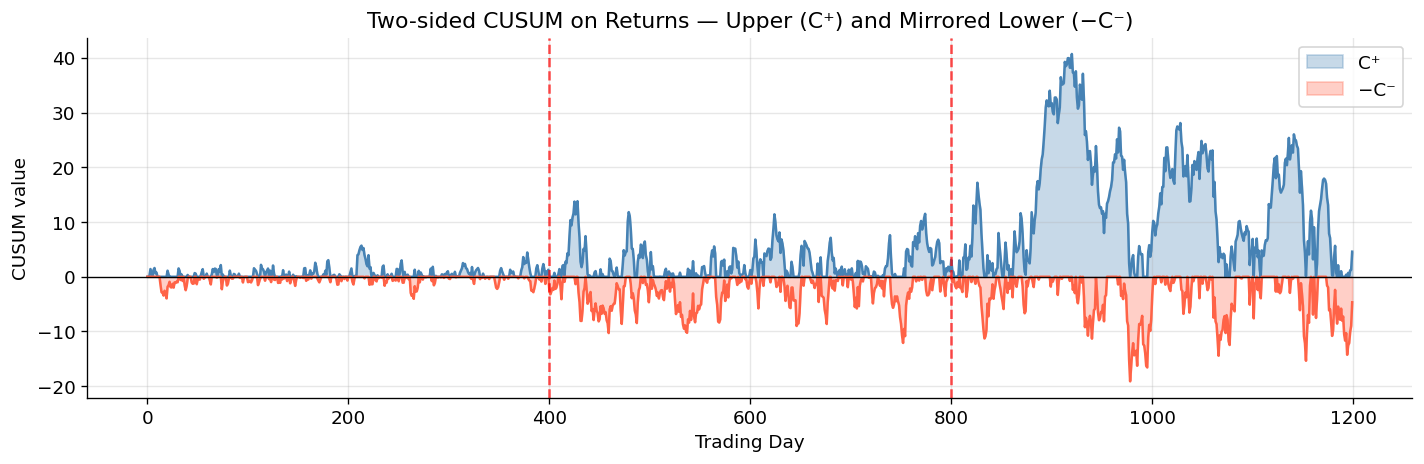

In [27]:

# ── 9.7 Plotly 3D: Two-sided CUSUM joint path surface (C⁺ and C⁻ over time) ──
# Shows how the upper and lower detectors evolve simultaneously — a combined ridge view
Cu_path, Cl_path, _, _ = cusum_two_sided(
    log_rets, k=0.5, h=999, mu0=mu0, sigma=sigma0, reset=False
)

n_3d = n_days
t3d  = np.arange(n_3d)
# Stack into shape (n_days, 2) for two ribbon surfaces
Z_both = np.column_stack([Cu_path[:n_3d], -Cl_path[:n_3d]])  # mirror lower below zero
sides  = np.array([0, 1])                                # 0=upper, 1=lower
T3, S3 = np.meshgrid(t3d, sides, indexing='ij')

# 2D companion
fig2d, ax2d = plt.subplots(figsize=(12, 4))
ax2d.fill_between(t3d, Cu_path[:n_3d], alpha=0.3, color='steelblue', label='C⁺')
ax2d.fill_between(t3d, -Cl_path[:n_3d], alpha=0.3, color='tomato', label='−C⁻')
ax2d.plot(t3d, Cu_path[:n_3d], color='steelblue', linewidth=1.5)
ax2d.plot(t3d, -Cl_path[:n_3d], color='tomato', linewidth=1.5)
ax2d.axhline(0, color='k', linewidth=0.8)
for cp in chg_pts:
    ax2d.axvline(cp, color='red', linestyle='--', alpha=0.7)
ax2d.set_title('Two-sided CUSUM on Returns — Upper (C⁺) and Mirrored Lower (−C⁻)')
ax2d.set_ylabel('CUSUM value'); ax2d.set_xlabel('Trading Day'); ax2d.legend()
plt.tight_layout(); plt.show()

# 3D Plotly — two ribbon surfaces side by side
fig3d = go.Figure()
fig3d.add_trace(go.Surface(
    x=T3, y=S3.astype(float), z=Z_both,
    colorscale=[
        [0.0, 'tomato'], [0.45, 'white'],
        [0.55, 'white'], [1.0, 'steelblue'],
    ],
    showscale=False,
    hovertemplate='Day=%{x}<br>Side=%{y:.0f}<br>Value=%{z:.2f}<extra></extra>',
    opacity=0.85,
))
for cp in chg_pts:
    fig3d.add_trace(go.Scatter3d(
        x=[cp, cp], y=[0, 1], z=[Z_both[cp, 0], Z_both[cp, 1]],
        mode='lines', line=dict(color='red', width=5),
        name=f'Change pt {cp}',
    ))
fig3d.update_layout(
    title='3D: Two-Sided CUSUM Path  (C⁺ upper, −C⁻ mirrored below zero)<br>'
          '<sup>Red lines = regime change days. '
          'Blue ridge = upward drift pressure; Red ridge = downward drift pressure</sup>',
    scene=dict(
        xaxis_title='Trading Day',
        yaxis=dict(title='Side', tickvals=[0,1], ticktext=['Upper C⁺','Lower −C⁻']),
        zaxis_title='CUSUM Value',
        camera=dict(eye=dict(x=1.6, y=-1.6, z=0.9)),
    ),
    height=650, width=1050, margin=dict(l=0, r=0, t=80, b=0),
)
fig3d.show()

---

# Part X — Applications: Regime Detection & Trading Signals

## 10.1 CUSUM as a Regime Filter

In systematic trading, CUSUM signals can serve as **regime filters** — binary on/off switches that change how a strategy behaves:

| CUSUM state | Regime | Strategy action |
|-------------|--------|----------------|
| $C^+$ silent, $C^-$ silent | Neutral / mean-reverting | Mean-reversion / carry |
| $C^+ > h$ fires | Bull / uptrend | Trend-follow long, reduce short |
| $C^- > h$ fires | Bear / downtrend | Trend-follow short, reduce long |
| Vol CUSUM fires | High-vol | Reduce position sizes, add hedges |

## 10.2 Volatility Targeting with CUSUM Gating

A **vol-targeted** strategy sizes positions as $w_t = \sigma^* / \hat\sigma_t$ where $\sigma^*$ is the target vol. A CUSUM vol alarm acts as a **gate**: if the alarm fires, cut the multiplier by half until the CUSUM resets.

## 10.3 CUSUM Event Labels for ML

Each CUSUM signal creates a **labeled event**: the window $[t_{\text{signal}-L}, t_{\text{signal}}]$ becomes a training example. The label is the direction (up/down) and the target can be the subsequent $P\&L$ over a fixed holding period.

### 10.4 CUSUM Regime Filter + Vol-Targeted Strategy

We combine two CUSUM detectors into a trading strategy:
1. **Volatility CUSUM** — signals vol spikes and triggers a 21-day risk-off window
2. **Return CUSUM** (two-sided) — provides directional bias (long/short/neutral)

Position sizing is vol-targeted: leverage $= \sigma^* / \hat\sigma_t$. The strategy is benchmarked against buy-and-hold and a vol-target-only baseline.

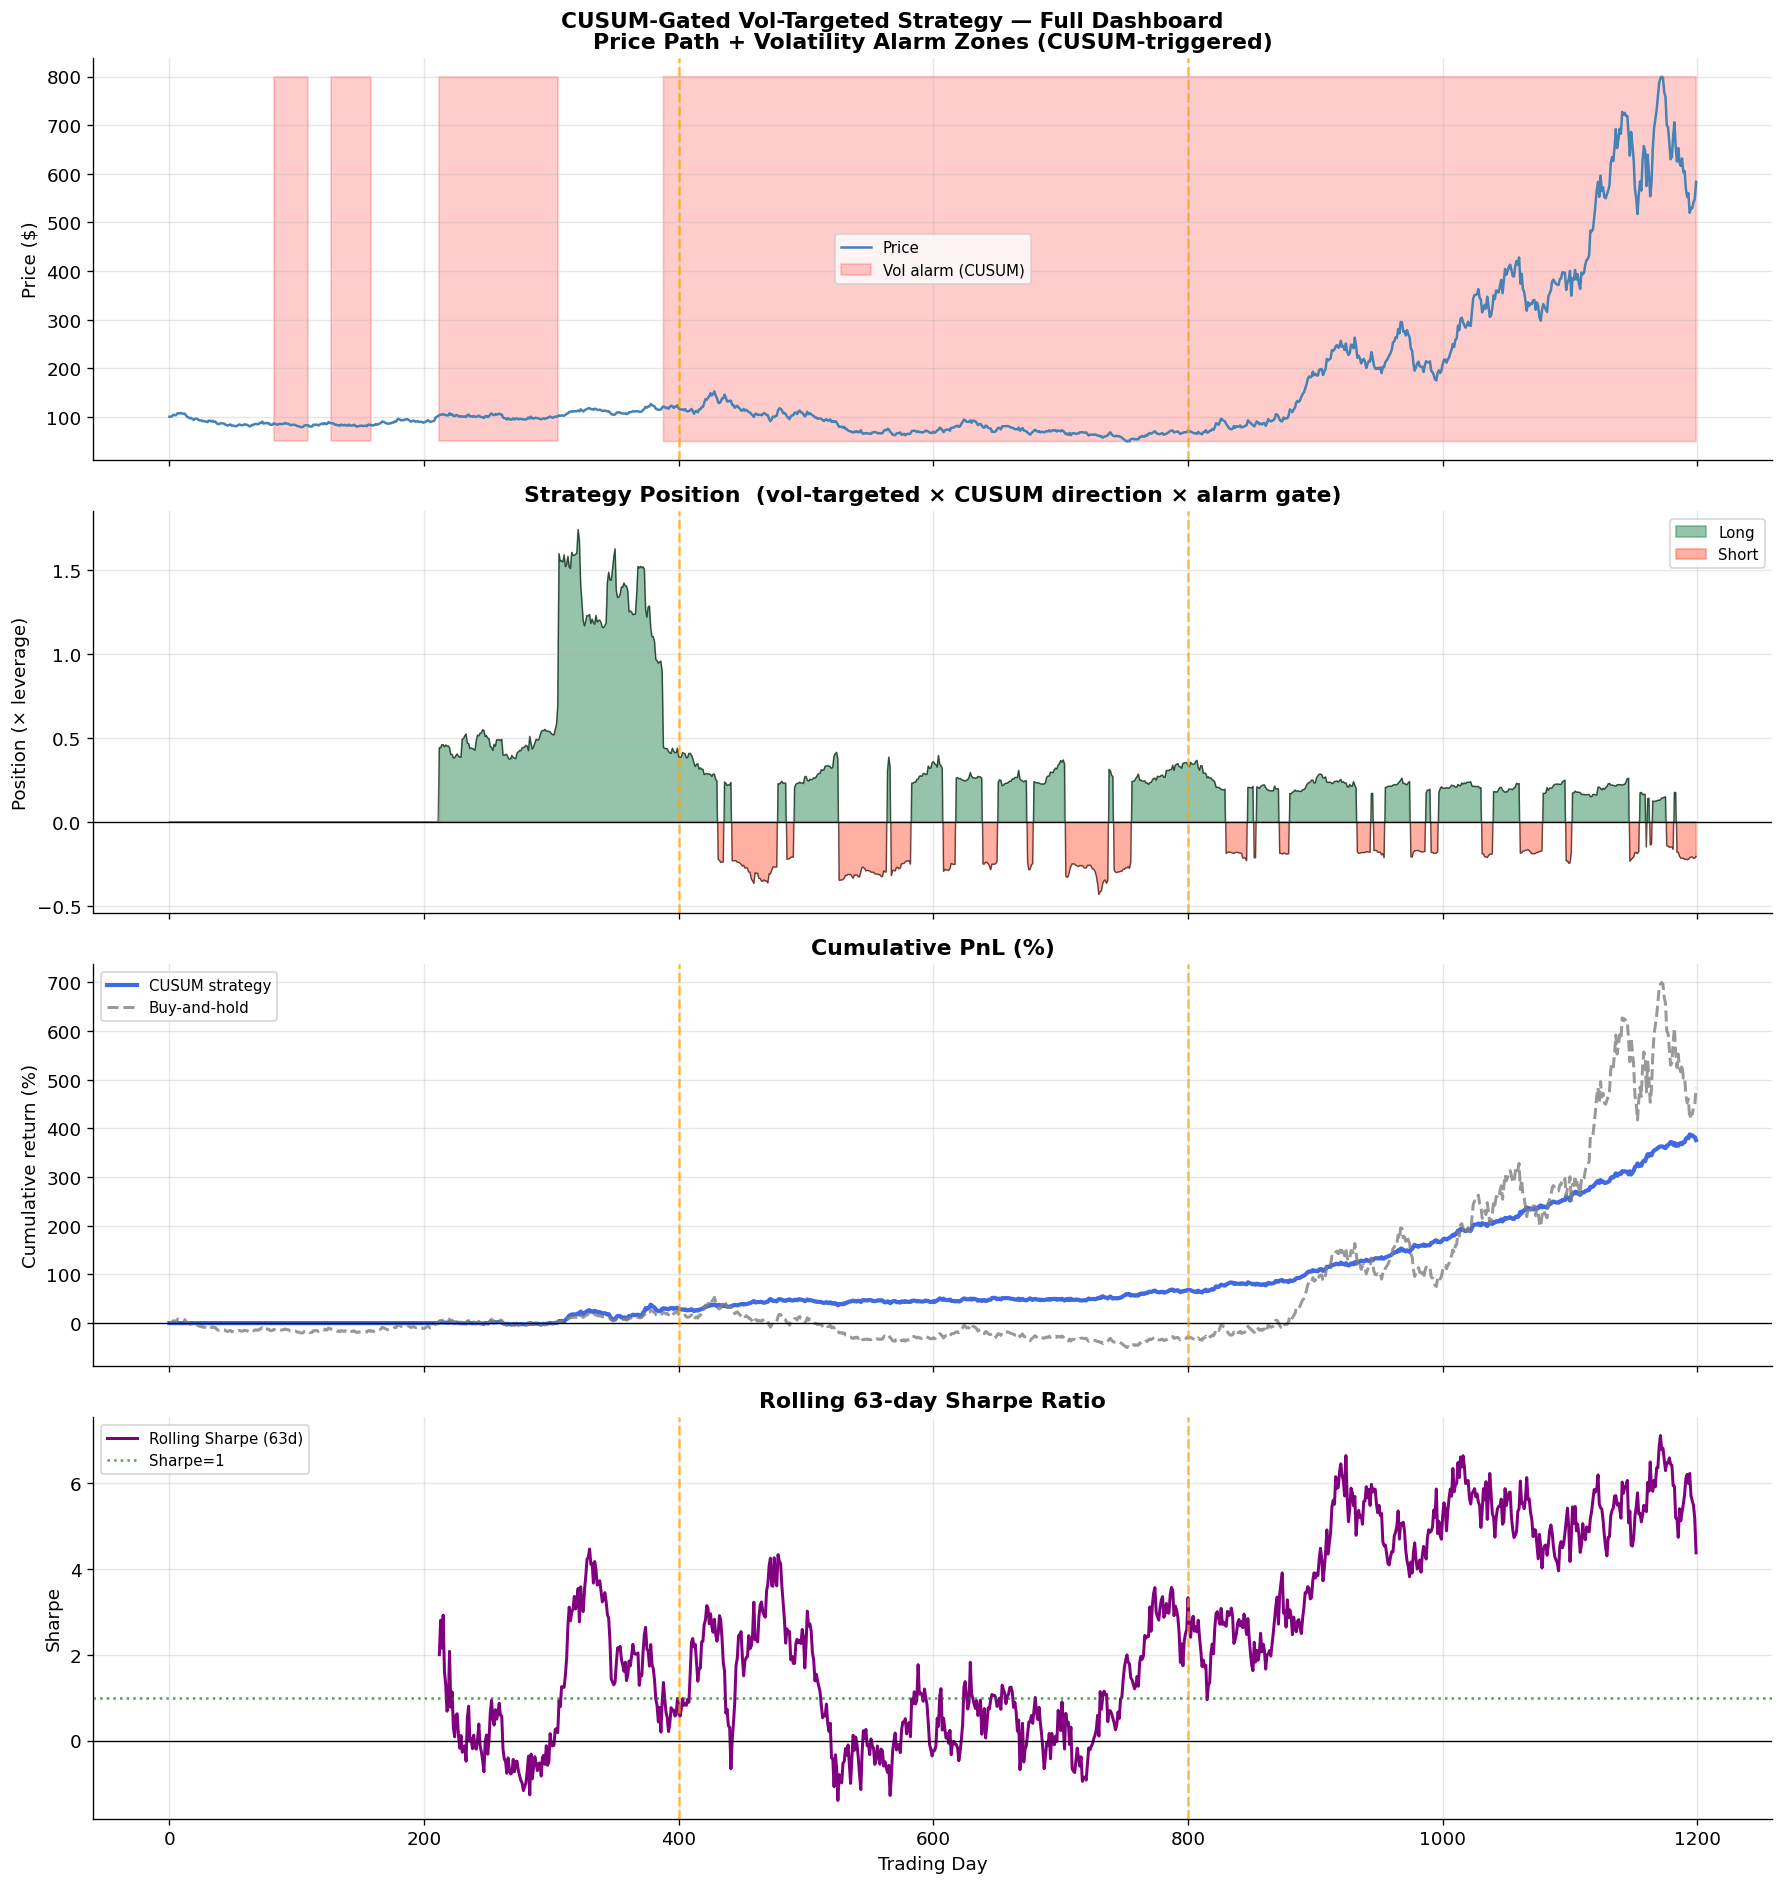

Strategy total return : +376.1%   Sharpe: 2.20
Buy-and-hold return   : +483.5%   Sharpe: 0.68
Vol alarm fired for   : 966 / 1200 days (80.5%)


In [28]:

# ── 10.4 CUSUM regime filter + vol-targeted strategy ─────────────────────────
target_vol  = TRUE_VOL * ANN * 100    # target annualised vol %
sigma_star  = target_vol

# Rolling vol estimate (21-day) used for position sizing
rv_21 = pd.Series(log_rets).rolling(21).std().values * ANN * 100
rv_21 = np.where(np.isnan(rv_21) | (rv_21 < 1e-3), target_vol, rv_21)

# Vol CUSUM gate: fire if vol spikes
Cu_vg, sigs_vg = cusum_one_sided(rv_21, k=0.5, h=5.0,
                                   mu0=hv21_mu, sigma=hv21_sig, reset=True)
vol_alarm = np.zeros(n_days, dtype=bool)
for s in sigs_vg:
    # mark alarm for next 21 days after each signal
    vol_alarm[s:min(s+21, n_days)] = True

# Return CUSUM for directional bias
Cu_ret_u, Cu_ret_l, up_ret, dn_ret = cusum_two_sided(
    log_rets, k=0.5, h=5.0, mu0=mu0, sigma=sigma0, reset=True
)

# Build a simple strategy
# Signal: +1 if recent up_signal, -1 if recent dn_signal, 0 otherwise
direction = np.zeros(n_days)
last_signal = 0
for i in range(n_days):
    if i in up_ret: last_signal =  1
    if i in dn_ret: last_signal = -1
    direction[i] = last_signal

# Position: vol-targeted, halved during alarm
pos_size = (sigma_star / rv_21)        # basic vol-targeting
pos_gated = pos_size * np.where(vol_alarm, 0.5, 1.0)   # gate during alarm
position  = direction * pos_gated
position  = np.clip(position, -5, 5)   # cap leverage

# Strategy PnL (daily)
pnl_strategy = position * log_rets
pnl_bah      = log_rets                # buy-and-hold benchmark

# Cumulative
cum_strat = np.exp(np.cumsum(pnl_strategy)) - 1
cum_bah   = np.exp(np.cumsum(pnl_bah)) - 1

# ── Visualisation ─────────────────────────────────────────────────────────────
fig, axes = plt.subplots(4, 1, figsize=(15, 16), sharex=True)

# Panel 0: price + vol alarm
ax = axes[0]
ax.plot(t, prices[1:], color='steelblue', linewidth=1.5, label='Price')
ax.fill_between(t, prices[1:].min(), prices[1:].max(),
                where=vol_alarm, alpha=0.2, color='red', label='Vol alarm (CUSUM)')
for cp in chg_pts:
    ax.axvline(cp, color='orange', linestyle='--', alpha=0.7)
ax.set_title('Price Path + Volatility Alarm Zones (CUSUM-triggered)', fontweight='bold')
ax.set_ylabel('Price ($)'); ax.legend(fontsize=9)

# Panel 1: position over time
ax2 = axes[1]
ax2.fill_between(t, position, 0, where=position > 0, alpha=0.5, color='seagreen', label='Long')
ax2.fill_between(t, position, 0, where=position < 0, alpha=0.5, color='tomato', label='Short')
ax2.plot(t, position, color='k', linewidth=0.8, alpha=0.6)
ax2.axhline(0, color='k', linewidth=0.8)
for cp in chg_pts:
    ax2.axvline(cp, color='orange', linestyle='--', alpha=0.7)
ax2.set_title('Strategy Position  (vol-targeted × CUSUM direction × alarm gate)',
              fontweight='bold')
ax2.set_ylabel('Position (× leverage)')
ax2.legend(fontsize=9)

# Panel 2: cumulative PnL
ax3 = axes[2]
ax3.plot(t, cum_strat * 100, color='royalblue', linewidth=2.5, label='CUSUM strategy')
ax3.plot(t, cum_bah   * 100, color='gray',      linewidth=1.8,
         linestyle='--', alpha=0.8, label='Buy-and-hold')
ax3.axhline(0, color='k', linewidth=0.8)
for cp in chg_pts:
    ax3.axvline(cp, color='orange', linestyle='--', alpha=0.7)
ax3.set_title('Cumulative PnL (%)', fontweight='bold')
ax3.set_ylabel('Cumulative return (%)')
ax3.legend(fontsize=9)

# Panel 3: rolling Sharpe (63-day)
pnl_roll = pd.Series(pnl_strategy)
roll_sr   = (pnl_roll.rolling(63).mean() / pnl_roll.rolling(63).std()) * np.sqrt(252)
ax4 = axes[3]
ax4.plot(t, roll_sr, color='purple', linewidth=1.8, label='Rolling Sharpe (63d)')
ax4.axhline(0, color='k', linewidth=0.8)
ax4.axhline(1, color='green', linestyle=':', alpha=0.7, label='Sharpe=1')
for cp in chg_pts:
    ax4.axvline(cp, color='orange', linestyle='--', alpha=0.7)
ax4.set_title('Rolling 63-day Sharpe Ratio', fontweight='bold')
ax4.set_ylabel('Sharpe'); ax4.set_xlabel('Trading Day')
ax4.legend(fontsize=9)

plt.suptitle('CUSUM-Gated Vol-Targeted Strategy — Full Dashboard', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

total_strat = cum_strat[-1] * 100
total_bah   = cum_bah[-1] * 100
sr_strat    = pnl_strategy.mean() / pnl_strategy.std() * np.sqrt(252)
sr_bah      = pnl_bah.mean() / pnl_bah.std() * np.sqrt(252)
print(f'Strategy total return : {total_strat:+.1f}%   Sharpe: {sr_strat:.2f}')
print(f'Buy-and-hold return   : {total_bah:+.1f}%   Sharpe: {sr_bah:.2f}')
print(f'Vol alarm fired for   : {vol_alarm.sum()} / {n_days} days ({vol_alarm.mean():.1%})')

### 10.5 CUSUM Event Labelling for ML

Each CUSUM signal is converted into a labelled training sample for supervised learning:
- **Features:** rolling statistics (mean, std, skew, etc.) in the $L$-day window before the signal
- **Label:** sign of the realised return over $H$ days after the signal

This produces a dataset where each row is a CUSUM-detected event with a forward-looking outcome — ready for classification models that learn to distinguish true regime shifts from noise.

Total CUSUM events labeled: 99
   day  direction    f_mean     f_std     f_rv21  label_sign  label_ret
0  212          1  0.005633  0.019805  32.290262           1   0.023663
1  420          1 -0.000251  0.027983  50.573143           1   0.166840
2  425          1  0.009973  0.030772  50.539139           1   0.011494
3  431         -1  0.009369  0.036079  63.993697          -1  -0.001599
4  436          1  0.009867  0.036728  60.121369          -1  -0.037618
5  442         -1  0.001558  0.037377  61.789918          -1  -0.079687
6  459         -1 -0.014039  0.025010  38.942974           1   0.009126
7  471         -1 -0.004290  0.024126  46.201269          -1  -0.035284
8  478          1 -0.002974  0.032722  62.698239           1   0.047753
9  485         -1  0.000463  0.038211  64.232589          -1  -0.019968


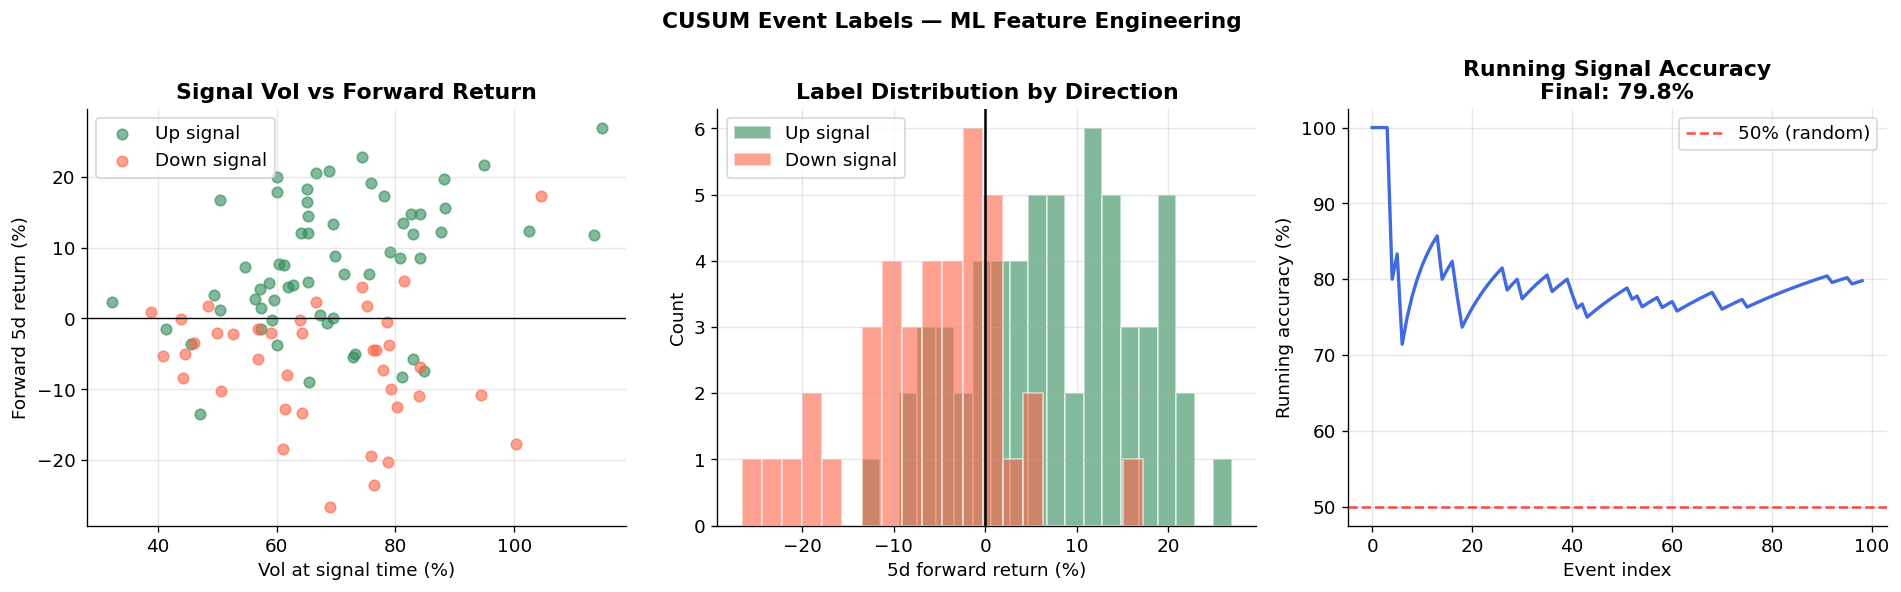

: 

In [ ]:

# ── 10.5 CUSUM event labeling for ML ──────────────────────────────────────────
# Each CUSUM signal becomes a labeled training event.
# Features: rolling stats in the L-day window before the signal.
# Label: sign of the realised return over H days after the signal.

L_feat = 21   # feature lookback
H_hold = 5    # holding period for label

all_signals = sorted(set(up_ret.tolist() + dn_ret.tolist()))
events = []

for sig in all_signals:
    if sig < L_feat or sig + H_hold >= n_days:
        continue
    window  = log_rets[sig - L_feat : sig]
    fwd_ret = log_rets[sig : sig + H_hold].sum()

    # Features
    feat = {
        'day'          : sig,
        'direction'    : 1 if sig in up_ret else -1,
        'f_mean'       : window.mean(),
        'f_std'        : window.std(),
        'f_skew'       : pd.Series(window).skew(),
        'f_rv21'       : rv_21[sig],
        'f_cusum_up'   : float(Cu_ret_u[sig]),
        'f_cusum_dn'   : float(Cu_ret_l[sig]),
        'label_sign'   : int(np.sign(fwd_ret)),
        'label_ret'    : fwd_ret,
    }
    events.append(feat)

df_events = pd.DataFrame(events)
print(f'Total CUSUM events labeled: {len(df_events)}')
print(df_events[['day','direction','f_mean','f_std','f_rv21','label_sign','label_ret']].head(10).to_string())

# ── Visualise event outcomes ──────────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# Panel 1: return at signal vs label
ax = axes[0]
for d, col, lbl in [(1,'seagreen','Up signal'), (-1,'tomato','Down signal')]:
    sub = df_events[df_events['direction'] == d]
    ax.scatter(sub['f_rv21'], sub['label_ret'] * 100,
               color=col, alpha=0.6, s=40, label=lbl)
ax.axhline(0, color='k', linewidth=0.8)
ax.set_xlabel('Vol at signal time (%)')
ax.set_ylabel(f'Forward {H_hold}d return (%)')
ax.set_title('Signal Vol vs Forward Return', fontweight='bold')
ax.legend()

# Panel 2: label distribution by direction
ax2 = axes[1]
for d, col, lbl in [(1,'seagreen','Up signal'), (-1,'tomato','Down signal')]:
    sub = df_events[df_events['direction'] == d]['label_ret'] * 100
    ax2.hist(sub, bins=20, alpha=0.6, color=col, label=lbl, edgecolor='white')
ax2.axvline(0, color='k', linewidth=1.5)
ax2.set_xlabel(f'{H_hold}d forward return (%)')
ax2.set_ylabel('Count')
ax2.set_title('Label Distribution by Direction', fontweight='bold')
ax2.legend()

# Panel 3: cumulative accuracy (is signal direction correct?)
df_events['correct'] = (df_events['direction'] * df_events['label_sign'] > 0).astype(int)
running_acc = df_events['correct'].expanding().mean()
ax3 = axes[2]
ax3.plot(range(len(df_events)), running_acc * 100, color='royalblue', linewidth=2)
ax3.axhline(50, color='red', linestyle='--', alpha=0.7, label='50% (random)')
ax3.set_xlabel('Event index')
ax3.set_ylabel('Running accuracy (%)')
ax3.set_title(f'Running Signal Accuracy\nFinal: {df_events["correct"].mean():.1%}', fontweight='bold')
ax3.legend()

plt.suptitle('CUSUM Event Labels — ML Feature Engineering', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

---

# Part XI — Complete Reference Summary

## CUSUM Estimator Decision Guide

```
What shift are you detecting?
│
├─► Mean shift in returns
│   ├─► One direction only → One-sided CUSUM (§II)
│   └─► Both directions   → Two-sided CUSUM (§III)
│
├─► Volatility regime change
│   ├─► No vol model fitted
│   │   ├─► Fast, noisy     → CUSUM on r² (§IV)
│   │   ├─► Moderate         → CUSUM on |r| (§IV)
│   │   └─► Smooth, lagged   → CUSUM on rolling HV (§IV)
│   └─► GARCH model available → CUSUM on ε² (§V)  ← most powerful
│
├─► Multiple change points → Binary Segmentation (§VII)
│
└─► Comparing with other methods
    ├─► Small persistent shifts (< 1σ) → CUSUM wins (§VIII)
    ├─► Medium shifts (1–2σ)           → EWMA competitive (§VIII)
    └─► Large sudden shifts (> 3σ)     → Shewhart sufficient (§VIII)
```

## Parameter Selection Guide

| Parameter | Symbol | Typical Range | Effect of Increasing |
|-----------|--------|---------------|---------------------|
| **Allowance** | $k$ | 0.25 – 1.0 | Fewer false alarms, slower detection |
| **Threshold** | $h$ | 3.0 – 8.0 | Higher ARL₀ (fewer false alarms), higher ARL₁ (slower) |
| **Burn-in** | — | 100 – 500 obs | More stable $\hat\mu_0$, $\hat\sigma_0$ estimates |

**Design recipe** (Hawkins & Olwell):
1. Choose target ARL₀ (e.g., 500 for daily data ≈ ~2 years)
2. Choose shift size $\delta$ you want to detect quickly
3. Set $k = \delta / 2$ (minimax optimal for Normal CUSUM)
4. Read $h$ from the ARL₀ surface (§IX) or use Siegmund's approximation

## Key Formulas

| Quantity | Formula |
|----------|---------|
| Standardised score | $y_t = (x_t - \mu_0) / \sigma_0$ |
| Upper CUSUM | $C_t^+ = \max(0,\ C_{t-1}^+ + y_t - k)$ |
| Lower CUSUM | $C_t^- = \max(0,\ C_{t-1}^- - y_t - k)$ |
| Signal | $C_t^+ > h$ (upward) or $C_t^- > h$ (downward) |
| Siegmund ARL₀ | $\text{ARL}_0 \approx \frac{e^{2\Delta b} - 2\Delta b - 1}{2\Delta^2}$ where $\Delta = h+1.166$ |
| Optimal allowance | $k^* = \delta/2$ for detecting shift of size $\delta$ |
| Binary Seg statistic | $\max_{1 \le \tau < n} \lvert S_\tau - \frac{\tau}{n} S_n \rvert$ |

## CUSUM vs Other Methods — Quick Reference

| Criterion | CUSUM | EWMA | Shewhart |
|-----------|-------|------|----------|
| Memory | Since last reset | Exponential decay | None |
| Best for | Small persistent shifts | Medium shifts | Large sudden shifts |
| Parameters | $k, h$ | $\lambda, L$ | $L$ |
| ARL₀ = 500 at | $k{=}0.5, h{\approx}4.8$ | $\lambda{=}0.2, L{=}2.86$ | $L{=}3.09$ |
| Computational cost | O(n) | O(n) | O(1) per point |
| Handles non-Normal | With adjustments | Robust | Robust |
| Two-sided | Run C⁺ and C⁻ | Natural | Natural |

## Applications in Quantitative Finance

| Application | CUSUM variant | Key insight |
|-------------|--------------|-------------|
| Regime detection | Two-sided on returns | Replaces HMM for online use |
| Vol breakout | One-sided on r² or ε² | Early warning for risk mgmt |
| Trend following | Direction from C⁺ vs C⁻ | Alternative to moving-average crossover |
| Structural break | Binary segmentation | Finds all parameter changes offline |
| ML event labels | Signal timestamps | Creates training events for supervised learning |
| Execution monitoring | CUSUM on slippage | Detects algo performance degradation |

## References

1. **Page, E.S.** (1954). "Continuous inspection schemes." *Biometrika*, 41(1/2), 100-115.
2. **Hawkins, D.M. & Olwell, D.H.** (1998). *Cumulative Sum Charts and Charting for Quality Improvement.* Springer.
3. **Siegmund, D.** (1985). *Sequential Analysis: Tests and Confidence Intervals.* Springer.
4. **López de Prado, M.** (2018). *Advances in Financial Machine Learning.* Wiley. (Ch. 17: CUSUM filters)
5. **Montgomery, D.C.** (2009). *Introduction to Statistical Quality Control.* Wiley. 7th ed.
